# 短信外呼26年在线运筹

In [150]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)
import socket

driver_ip = socket.gethostbyname(socket.gethostname())
import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

warnings.filterwarnings("ignore")


# Project root
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "jupyter-workspace":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Cannot find jupyter-workspace from current path")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Using project root:", PROJECT_ROOT)


# Local src imports
from src.backtest import run_manual_train_val_recent, run_target_dates_backtest, run_fixed_period_simulation
from src.configs import CONTROL_NAME, DEFAULT_COUPON, DISCOUNT_PARA, GROUP_NAME_LIST
from src.reporting import plot_rolling_backtest_with_uniform_coupon_points
from src.binning import (
    move_threshold_train_with_nan,
    apply_threshold_to_test,
    build_stage_bucket_mapping,
    assign_bucket_num,
    split_data_no_cartesian,
)

# Backflow imports
from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools


# Matplotlib font
font_path = PROJECT_ROOT / "SubsetOTF/CN/SourceHanSansCN-Normal.otf"

if font_path.exists():
    fm.fontManager.addfont(str(font_path))
    font_prop = fm.FontProperties(fname=str(font_path))
    font_name = font_prop.get_name()
    plt.rcParams["font.sans-serif"] = [font_name]

plt.rcParams["axes.unicode_minus"] = False

from pyspark.sql import SparkSession
spark3conf_best = {
    "spark.submit.deployMode": "client",
    "spark.driver.host": driver_ip,
    "spark.driver.bindAddress": driver_ip,
    "spark.yarn.queue": "root.profile_prod",

    "spark.driver.memory": "24g",
    "spark.driver.memoryOverhead": "4g",

    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "80",
    "spark.dynamicAllocation.initialExecutors": "80",
    "spark.dynamicAllocation.maxExecutors": "120",
    "spark.dynamicAllocation.shuffleTracking.enabled": "true",

    "spark.executor.cores": "2",
    "spark.executor.memory": "12g",
    "spark.executor.memoryOverhead": "8g",

    "spark.default.parallelism": "1200",
    "spark.sql.shuffle.partitions": "1200",

    "spark.sql.adaptive.enabled": "true",
    "spark.sql.adaptive.coalescePartitions.enabled": "true",
    "spark.sql.adaptive.skewJoin.enabled": "true",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "134217728",

    "spark.sql.autoBroadcastJoinThreshold": "104857600",
    "spark.sql.broadcastTimeout": "3000",

    "spark.network.timeout": "600s",
    "spark.executor.heartbeatInterval": "60s",

    "spark.memory.fraction": "0.8",
    "spark.memory.storageFraction": "0.3",

    "spark.sql.execution.arrow.pyspark.enabled": "true",
    "spark.sql.execution.arrow.maxRecordsPerBatch": "5000",

    "spark.hadoop.mapreduce.input.fileinputformat.input.dir.recursive": "true",
    "spark.hadoop.hive.mapred.supports.subdirectories": "true",

    "spark.serializer": "org.apache.spark.serializer.KryoSerializer",
    "spark.kryoserializer.buffer.max": "1024m",

    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster_63.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.15_for_tfcluster_63.tgz/py3.7.15_for_tfcluster/bin/python3",

    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",

    "spark.sql.merge.mode": "FAST",
    "spark.sql.merge.enabled": "TRUE",
}

builder = (
    SparkSession
    .builder
    .appName("flowback_auto")
    .master("yarn")
)

for k, v in spark3conf_best.items():
    builder = builder.config(k, v)

spark = builder.enableHiveSupport().getOrCreate()

print("[Info] Spark Version:", spark.version)
print("[Info] Spark Queue:", spark.conf.get("spark.yarn.queue"))
print("[Info] Spark App ID:", spark.sparkContext.applicationId)
print(spark.conf.get("spark.yarn.queue"))
print(spark.sparkContext.applicationId)

Using project root: /home/luban/zyr/jupyter-workspace


Application Id: application_1782979140233_51818840, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_51818840/


[Info] Spark Version: 3.2.0-101
[Info] Spark Queue: root.profile_prod
[Info] Spark App ID: application_1782979140233_51818840
root.profile_prod
application_1782979140233_51818840


INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 52876)


# 离线运筹函数定义

In [127]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)

import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

def move_threshold_train_with_nan_list(train_data, group_name_list, columns, bin_count=5):
    """
    训练集分位数处理函数（包含空值/999）。
    bin_count 支持：
      - int: 所有列同一个分桶数
      - dict: 每列单独配置分桶数，例如 {"purchase_score": 10, "uplift_6_5": 5}
    """
    train_data = train_data.copy()

    quantile_thresholds = {}
    for col in columns:
        if col not in train_data.columns:
            quantile_thresholds[col] = None
            continue

        col_bin_count = _bin_count_for_column(bin_count, col)
        quantiles = _quantiles_for_bin_count(col_bin_count)

        filled_data = train_data[col].fillna(999)

        if filled_data.nunique() > 1 and len(quantiles) > 0:
            quantile_thresholds[col] = filled_data.quantile(quantiles).values
        else:
            quantile_thresholds[col] = None

    for col in columns:
        if col not in train_data.columns:
            continue

        new_col_name = f"{col}_per"
        thresholds = quantile_thresholds.get(col)

        if thresholds is None:
            train_data[new_col_name] = 1.0
            continue

        bins = np.concatenate([[-np.inf], thresholds, [np.inf]])
        bins = np.asarray(_unique_increasing_edges(bins))

        labels = _labels_for_bin_count(len(bins) - 1)

        train_data[new_col_name] = pd.cut(
            train_data[col].fillna(999),
            bins=bins,
            labels=labels,
            include_lowest=True
        )

    train_df = train_data[train_data["group_name_eve"].isin(group_name_list)].copy()

    return quantile_thresholds, train_df

def _quantiles_for_bin_count(bin_count):
    if not isinstance(bin_count, int) or bin_count < 1:
        raise ValueError("bin_count must be a positive integer")
    if bin_count == 1:
        return np.asarray([])
    return np.linspace(1.0 / bin_count, (bin_count - 1.0) / bin_count, bin_count - 1)

def _bin_count_for_column(bin_count, col):
    """bin_count 支持 int 或 {col: bin_count}."""
    if isinstance(bin_count, dict):
        if col not in bin_count:
            raise ValueError("bin_count dict missing column: {}".format(col))
        use_bin_count = bin_count[col]
    else:
        use_bin_count = bin_count

    if not isinstance(use_bin_count, int) or use_bin_count < 1:
        raise ValueError("bin_count for {} must be a positive integer".format(col))

    return use_bin_count

def _labels_for_bin_count(bin_count):
    return [round(float(x), 3) for x in np.linspace(1.0 / bin_count, 1.0, bin_count)]


def _unique_increasing_edges(edges):
    unique_edges = []
    for edge in edges:
        edge = float(edge)
        if not unique_edges or edge > unique_edges[-1]:
            unique_edges.append(edge)
    return unique_edges

def move_threshold_train_with_nan(train_data, group_name_list, columns, bin_count=5):
    """
    训练集分位数处理函数，支持指定分桶数。
    bin_count=5  -> 0.2, 0.4, 0.6, 0.8, 1.0
    bin_count=10 -> 0.1, 0.2, ..., 0.9, 1.0
    """
    if not isinstance(bin_count, int) or bin_count < 1:
        raise ValueError("bin_count 必须是正整数")

    train_data = train_data.copy()

    if bin_count == 1:
        quantiles = np.asarray([])
    else:
        quantiles = np.linspace(
            1.0 / bin_count,
            (bin_count - 1.0) / bin_count,
            bin_count - 1,
        )

    quantile_thresholds = {}
    for col in columns:
        if col in train_data.columns:
            filled_data = train_data[col].fillna(999)

            if filled_data.nunique(dropna=False) > 1 and len(quantiles) > 0:
                quantile_thresholds[col] = filled_data.quantile(quantiles).values
            else:
                quantile_thresholds[col] = None

    for col in columns:
        if col not in train_data.columns:
            continue

        new_col_name = f"{col}_per"
        thresholds = quantile_thresholds.get(col)

        if thresholds is None:
            train_data[new_col_name] = 1.0
            continue

        bins = np.concatenate([[-np.inf], thresholds, [np.inf]])

        # 去重，避免分位点重复导致 pd.cut labels 数量不匹配
        bins = np.array(sorted(set(float(x) for x in bins)))

        labels = [
            round(float(x), 3)
            for x in np.linspace(1.0 / (len(bins) - 1), 1.0, len(bins) - 1)
        ]

        train_data[new_col_name] = pd.cut(
            train_data[col].fillna(999),
            bins=bins,
            labels=labels,
            include_lowest=True,
        )

    train_df = train_data[train_data["group_name_eve"].isin(group_name_list)].copy()

    return quantile_thresholds, train_df

def apply_threshold_to_test(test_data, quantile_thresholds, columns):
    """
    使用训练集计算的阈值对测试集进行分桶。
    支持不同列不同分桶数。
    """
    test_data = test_data.copy()

    for col in columns:
        if col not in test_data.columns:
            continue

        thresholds = quantile_thresholds.get(col)
        new_col_name = f"{col}_per"

        if thresholds is None:
            test_data[new_col_name] = 1.0
            continue

        bins = np.concatenate([[-np.inf], thresholds, [np.inf]])

        # 去重后再生成 labels，避免 duplicates='drop' 后 labels 数量不匹配
        bins = np.array(sorted(set(float(x) for x in bins)))

        n_bins = len(bins) - 1
        labels = [
            round(float(x), 3)
            for x in np.linspace(1.0 / n_bins, 1.0, n_bins)
        ]

        test_data[new_col_name] = pd.cut(
            test_data[col].fillna(999),
            bins=bins,
            labels=labels,
            include_lowest=True,
        )

    return test_data


import datetime
from itertools import product

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # 计算 delta_cac
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr


def process_df(df, control_name, bucket_name='bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    group_dfs = []

    for name, group in df.groupby(bucket_name):  # 将每个桶中不同折扣的数据进行放缩
        group = group.copy()

        sample = group['in_uv'].sum()  # 该分桶下的总人数，也即某一桶下所有 treatment 总和
        group['zoom_sample'] = sample

        group['zoom_first'] = group.apply(
            lambda row: row.zoom_sample / row.in_uv * row.finish_uv if row.in_uv != 0 else 0,
            axis=1
        )
        group['zoom_finish'] = group.apply(
            lambda row: row.zoom_sample / row.in_uv * row.finish_pv if row.in_uv != 0 else 0,
            axis=1
        )
        group['zoom_cost'] = group.apply(
            lambda row: row.zoom_sample / row.in_uv * float(row.total_cost) if row.in_uv != 0 else 0,
            axis=1
        )

        group['cvr_pv'] = group.apply(
            lambda row: row.zoom_finish / row.zoom_sample if row.zoom_sample != 0 else 0,
            axis=1
        )

        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
        control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()

        group['zoom_delta_cost'] = group['zoom_cost'] - control_cost
        group['zoom_delta_finish'] = group['zoom_finish'] - control_finish
        group['zoom_delta_first'] = group['zoom_first'] - control_first

        group_dfs.append(group)

    new_df = pd.concat(group_dfs, ignore_index=True) if group_dfs else pd.DataFrame()
    return new_df

def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_delta_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target)
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    if solver is None:
        raise RuntimeError('SCIP不可用，停止产策')
    solver.SetTimeLimit(15000)  # 与CF 3T原始搜索一致
    # 创建N个二进制变量
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i]
    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i]
    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
    # 约束条件2: 成本约束
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # obj_exp：delta_finish
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()
    if result_status != pywraplp.Solver.OPTIMAL:
        raise RuntimeError('SCIP未达到OPTIMAL，停止产策: status={}'.format(result_status))
    selected = np.asarray(res)
    if not np.allclose(selected.reshape(bucket_num, discount_num).sum(axis=1), 1.0):
        raise ValueError('求解结果未满足每桶一个动作')
    if float(np.dot(constraint, selected)) > set_cost * float(np.dot(target, selected)) + 1e-6:
        raise ValueError('求解结果违反增量CAC约束')
    return (max_finish, res)

def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

# 引入对预测集出现新的组合桶，也即打上bucket_num=-1的桶的给出策略处理：通补线上基线

def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping

def simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y: 
    C: 
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res= {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []
    
    color_mapping = {
    '555': 'brown',
    '留存6张3元': 'darkgreen'
    # add others...
}
    

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        discount_res = or_convert(res, bucket_info, discount_para)
        discount_res_list.append(discount_res)

        # 计算训练集结果
        train_ans = mock_use(processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)
        # 计算测试集结果
        test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        discount_dict = {key: group_name for key in discount_res}
        train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name, all_default_coupon_flag=True)
        test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name, default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])
        
        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }
    
    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'), label=f'train_{group_name}_single', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')
    
    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'), label=f'test_{group_name}_single', marker='.')
    
    
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()
    
    return discount_res_list, train_list, test_list, tongbu_list

def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '6张5元新': 'brown',
        '10张3元': 'darkgreen'
        # add others...
    }

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        discount_res = or_convert(res, bucket_info, discount_para)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 2  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return discount_res_list, train_list, test_list, tongbu_list, tongbu_all_list

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket

def split_data_no_cartesian(small_data, columns, all_columns, min_count):
    # 仅使用指定列进行分组和统计，但保留所有列
    combination_counts = small_data.groupby(columns, observed=True)['pid'].count().reset_index(name='counts')

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]

    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    # small_sample_data + large_sample_data 长度正好等于 small_data

    large_use_combinations = large_sample_data.groupby(all_columns, observed=True).size().reset_index(name='counts') # 是复原到全部all_columns的结果，因此每条不一定满足最小样本量
    small_use_combinations = small_sample_data.groupby(all_columns, observed=True).size().reset_index(name='counts')
    
    assert (large_use_combinations['counts'] > 0).all(), \
        f"发现 {(large_use_combinations['counts'] == 0).sum()} 条 large_use_combinations 的 counts = 0"

    assert (small_use_combinations['counts'] > 0).all(), \
        f"发现 {(small_use_combinations['counts'] == 0).sum()} 条 small_use_combinations 的 counts = 0"

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

def main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name,cost_list, all_columns, stages, discount_para, method=0, read_directly=True, \
                show_tongbu=True, combinations=False, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]

    if not stages:
        raise ValueError("未能匹配到传入分阶段划分参数组合")

    # 执行多阶段分层拆分
    use_data_input = train_df.copy()
    stage_results = []
    current_data = use_data_input

    # step 1: 基于逐层兜底获取分桶结果
    for stage in stages:
        columns, min_count = stage
        large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_data_no_cartesian(current_data, columns, all_columns, min_count)
        current_data = small_data
        stage_results.append((large_use_combinations, small_use_combinations, columns))

    # 获取最后阶段的组合数据
    large_use_combinations = stage_results[-1][0]
    small_use_combinations = stage_results[-1][1]

    # 准备传入generate_bucket_mapping_final的组合数据
    stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

    # 生成桶号映射
    bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
    reverse_mapping = {}
    mapping = bucket_mapping
    for bucket_num, combinations in mapping.items():
        for combination in combinations:
            reverse_mapping[combination] = bucket_num
        
    # step 2: 基于分桶结果统计后验label: 'zoom_cost', 'zoom_delta_finish'
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print("train_df_bucket_num: "+str(train_df['bucket_num'].unique()))
    # 用新的分桶实现
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])
    processed_data = process_df(rct_pred_data, control_name='DS空白')
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')

    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    unknown_count = (val_df['bucket_num'] == -1).sum()
    total_count = len(val_df)
    unknown_ratio = unknown_count / total_count * 100 if total_count > 0 else 0
    print(f"\n验证集 bucket_num 统计:")
    print(f"  总数据量: {total_count}")
    print(f"  未知组合数量 (bucket_num=-1): {unknown_count}")
    print(f"  未知组合占比: {unknown_ratio:.2f}%")
    print(f"  已知组合数量: {total_count - unknown_count}")

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])
    next_processed_data = process_df(next_rct_pred, control_name='DS空白')
    # 绘制仿真结果
    discount_res_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, train_list, test_list, tongbu_list, tongbu_all_list

# 在线运筹函数定义

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from itertools import combinations
from IPython.display import display

### 样本准备与质量处理

In [75]:
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt and start_dt not in ignore_dts:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

### 基模型验证与绘图

In [76]:
def pandas_delta_cvr_simulate_gap(df, prob_t, prob_c, label_col, 
                  group_c='control_group',                          
                  group_t='555',                                
                  group_col='group_name_eve',                      
                  is_in_treat_compare=True,
                  add_group_cols=None, 
                  bins=10,
                  add_agg=None):
    if is_in_treat_compare:
        # Add delta_prob calculation column
        df["delta_prob"] = df[prob_t] - df[prob_c]
        bucket_col = "delta_prob"
        agg_cmd_base = {
            "total_cnt": (label_col, "count"),
            f"mean_{prob_c}": (prob_c, "mean"),
            f"mean_{prob_t}": (prob_t, "mean"),
            "mean_delta_pred": ("delta_prob", "mean"),
            # Calculate the mean label values for the treatment and control groups respectively
            "mean_t_label": (label_col, lambda x: x[df.loc[x.index, group_col] == group_t].mean()),
            "mean_c_label": (label_col, lambda x: x[df.loc[x.index, group_col] == group_c].mean())
        }
    else:
        bucket_col = prob_t
        # 预处理分组标识列
        df['_is_group_c'] = (df[group_col] == group_c).astype(int)
        df['_is_group_t'] = (df[group_col] == group_t).astype(int)
        
        agg_cmd_base = {
            "ingroup_cnt": ('_is_group_c', 'sum'),  # 总样本数为对照组+实验组
            "cvt": (label_col, "sum"),
            "tCVR": (label_col, lambda x: x.sum() / x.count()),
            prob_t: (prob_t, "mean"),
            # 直接计算两个组的计数和标签和
            "count_1": ('_is_group_c', 'sum'),  # 对照组计数
            "sum_label_1": (label_col, lambda x: x[df.loc[x.index, group_col] == group_c].sum()),
            "count_2": ('_is_group_t', 'sum'),  # 实验组计数
            "sum_label_2": (label_col, lambda x: x[df.loc[x.index, group_col] == group_t].sum())
        }
        if add_agg is not None:
            agg_cmd_base.update(add_agg)

    # Common binning operation
    df = df[df[label_col].notnull()]
    df[f"{bucket_col}_freq_bucket"] = pd.qcut(df[bucket_col], bins, labels=False)

    __group_cols = [f"{bucket_col}_freq_bucket"]
    if add_group_cols:
        __group_cols += add_group_cols
        
    stats = df.groupby(__group_cols).agg(**agg_cmd_base).reset_index()

    if is_in_treat_compare:
        # Calculate the true difference (treatment group - control group)
        stats['mean_label_diff'] = stats['mean_t_label'] - stats['mean_c_label']
        
        plt.figure(figsize=(12, 6))
        stats['delta_prob_freq_bucket'] = stats['delta_prob_freq_bucket'].astype(str)
        
        # Hyperbola comparison
        plt.plot(stats['delta_prob_freq_bucket'], stats['mean_delta_pred'], 
                'b-o', label='Prediction Delta (T - C)')
        plt.plot(stats['delta_prob_freq_bucket'], stats['mean_label_diff'], 
                'r--s', label='Actual Delta (T - C)')
        
        plt.xticks(rotation=45)
        plt.xlabel('Delta Prob Bucket')
        plt.ylabel('Delta Value')
        plt.title(f"Delta Analysis: {prob_t} vs {prob_c}")
        plt.legend()
        plt.grid(True)
        plt.show()
    else:
        stats[f'mean_label_1'] = stats['sum_label_1'] / stats['count_1']
        stats[f'mean_label_2'] = stats['sum_label_2'] / stats['count_2']
        stats['mean_true_label_diff'] = stats[f'mean_label_2'] - stats[f'mean_label_1']
        stats['prob_c_col'] = prob_t
        stats['freq_bucket_col'] = f"{prob_t}_freq_bucket"
        stats['group_c'] = group_c
        stats['group_t'] = group_t

        # Plot the comparison chart of mean label values between the control and treatment groups
        plt.figure(figsize=(12, 6))
        stats[f'{prob_t}_freq_bucket'] = stats[f'{prob_t}_freq_bucket'].astype(str)
        
        plt.plot(stats[f'{prob_t}_freq_bucket'], stats[prob_t], 
                'b-o', label='Prediction Delta Cvr')
        plt.plot(stats[f'{prob_t}_freq_bucket'], stats[f'mean_true_label_diff'], 
                'r--s', label= 'Actual Delta Label')
        
        plt.xticks(rotation=45)
        plt.xlabel(f'{prob_t} Bucket')
        plt.ylabel('Mean Label Value')
        plt.title(f"Mean Label Comparison: {group_c} vs {group_t}")
        plt.legend()
        plt.show()
    return stats

### 在线打分与乘子求解

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
from scipy.optimize import minimize_scalar
from IPython.display import display
import os


def intervention_scores(df, lambda_val, cost, action_list):
    # action_list 顺序就是同分优先级；本任务把left_63放在第一位。
    scores = pd.DataFrame(index=df.index)
    for action in action_list:
        scores['intervention_' + action] = (
            0.0 if action == 'C' else df['delta_cvr_' + action]
            + lambda_val * (cost * df['delta_cvr_' + action] - df['cost_' + action]))
    return scores


def objective_function(lambda_val, df, cost, action_list):
    return intervention_scores(df, lambda_val, cost, action_list).max(axis=1).sum()


def find_optimal_lambda(df, cost, lamb_s, lamb_end, action_list):
    result = minimize_scalar(
        fun=objective_function, args=(df, cost, action_list),
        bounds=(lamb_s, lamb_end), method='bounded', options={'xatol': 1e-6})
    if not result.success:
        raise RuntimeError(f"优化失败: {result.message}")
    # bounded通常不访问端点，显式比较；同目标值时取较小λ。
    candidates = [float(lamb_s), float(result.x), float(lamb_end)]
    optimal_lambda = min(candidates, key=lambda x: (objective_function(x, df, cost, action_list), x))
    return optimal_lambda


def prediction_summary(selected, cost, action_list):
    predicted_pv = sum(selected.loc[selected.best_intervention == a, 'delta_cvr_' + a].sum()
                       for a in action_list if a != 'C')
    predicted_cost = sum(selected.loc[selected.best_intervention == a, 'cost_' + a].sum()
                         for a in action_list if a != 'C')
    residual = predicted_cost - cost * predicted_pv
    return dict(predicted_delta_pv=predicted_pv, predicted_cost=predicted_cost,
                predicted_delta_cac=predicted_cost / predicted_pv if predicted_pv > 0 else np.nan,
                constraint_residual=residual, constraint_satisfied=bool(residual <= 1e-8),
                predicted_feasible=bool(predicted_pv > 0 and residual <= 1e-8),
                no_send_share=(selected.best_intervention == 'C').mean())


In [86]:
def online_process_df(df, control_name, bucket_name='bucket_name'):
    # 保留旧版：各RCT组均值放缩到推荐动作层的总人数。
    parts = []
    for _, group in df.groupby(bucket_name):
        group = group.copy()
        group['zoom_sample'] = group['in_uv'].sum()
        group['zoom_finish'] = group['zoom_sample'] / group['in_uv'] * group['finish_pv']
        group['zoom_cost'] = group['zoom_sample'] / group['in_uv'] * group['total_cost']
        group['cvr_pv'] = group['finish_pv'] / group['in_uv']
        control = group[group['exp_name'] == control_name]
        group['zoom_delta_cost'] = group['zoom_cost'] - control['zoom_cost'].sum()
        group['zoom_delta_finish'] = group['zoom_finish'] - control['zoom_finish'].sum()
        parts.append(group)
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


def mock_online(df, dict_coupon, control_name='control_group', return_details=False):
    # 遍历实际推荐层，不能因dict_coupon漏配而静默丢掉推荐人口。
    rows = []
    if not df.empty:
        for action, group in df.groupby('bucket_name'):
            n = float(group['zoom_sample'].iloc[0])
            t = group[group.exp_name == dict_coupon[action]]
            c = group[group.exp_name == control_name]
            # 不发与空白是同一个动作，增量恒为0，不需要额外估计均值。
            supported = action == 'C' or (not t.empty and not c.empty)
            dy = 0.0 if action == 'C' else (float(t.zoom_finish.iloc[0] - c.zoom_finish.iloc[0]) if supported else np.nan)
            dc = 0.0 if action == 'C' else (float(t.zoom_cost.iloc[0] - c.zoom_cost.iloc[0]) if supported else np.nan)
            rows.append(dict(action=action, n=n, n_t=int(t.in_uv.sum()), n_c=int(c.in_uv.sum()),
                             supported=supported, zoom_delta_pv=dy, zoom_delta_cost=dc))
    detail = pd.DataFrame(rows, columns=['action','n','n_t','n_c','supported','zoom_delta_pv','zoom_delta_cost'])
    supported = not detail.empty and bool(detail.supported.all())
    population = detail.n.sum()
    dy = detail.zoom_delta_pv.sum() if supported else np.nan
    dc = detail.zoom_delta_cost.sum() if supported else np.nan
    missing = detail.loc[~detail.supported.astype(bool), ['action','n','n_t','n_c']].to_dict('records')
    status = ('empty_population' if detail.empty else 'missing_support' if not supported
              else 'all_no_send' if (detail.action == 'C').all()
              else 'nonpositive_delta_pv' if dy <= 0 else 'historical_rct_replay')
    metrics = dict(status=status, n=population, delta_finish_pv_total=dy, delta_cost=dc,
                   delta_pv_per_user=dy/population if population > 0 else np.nan,
                   delta_cac=dc/dy if supported and dy > 0 else np.nan,
                   unsupported_n=sum(r['n'] for r in missing), missing_support=missing)
    if return_details:
        return metrics, detail
    # 保留旧版的两个返回值：CAC、人均增量PV。
    return [metrics['delta_cac'], metrics['delta_pv_per_user']]


In [87]:
def calculate_all_metrics(df, group_name_1, group_name_2):
    t = df[df.group_name_eve == group_name_1]
    c = df[df.group_name_eve == group_name_2]
    if t.empty or c.empty:
        return np.nan, np.nan
    dy = t.finish_cnt_7d.mean() - c.finish_cnt_7d.mean()
    dc = t.cost_7d.mean() - c.cost_7d.mean()
    return (dc/dy if dy > 0 else np.nan), dy


In [88]:
def apply_lambda_strategy(df, optimal_lambda, cost, dict_coupon, control_name, action_list,
                          return_details=False):
    # 默认保留旧版两个返回值；return_details=True提供指标、分层回放、推荐明细。
    selected = df.copy()
    scores = intervention_scores(selected, optimal_lambda, cost, action_list)
    selected['best_intervention'] = scores.idxmax(axis=1).str.replace('intervention_', '', regex=False)
    selected['best_score'] = scores.max(axis=1)
    pred_data = selected.groupby(['best_intervention','group_name_eve']).agg(
        in_uv=('pid','size'), finish_pv=('finish_cnt_7d','sum'), total_cost=('cost_7d','sum')
    ).reset_index().rename(columns={'best_intervention':'bucket_name','group_name_eve':'exp_name'})
    processed_data = online_process_df(pred_data, control_name)
    metrics, detail = mock_online(processed_data, dict_coupon, control_name, return_details=True)
    metrics.update(prediction_summary(selected, cost, action_list))
    if return_details:
        return metrics, detail, selected
    return [metrics['delta_cac'], metrics['delta_pv_per_user']]


In [91]:
def setup_chinese_font():
    font_path = '/usr/share/fonts/wqy-microhei/wqy-microhei.ttc'
    if os.path.exists(font_path):
        zh_font = FontProperties(fname=font_path)
        mpl.rcParams['font.family'] = 'WenQuanYi Micro Hei'
        mpl.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei']
        mpl.rcParams['axes.unicode_minus'] = False
        return zh_font
    return None

def calculate_stratified_rct_points(
    df, optimal_lambda, focus_cost,
    action_list, dict_coupon, control_name
):
    # 使用指定C、λ形成推荐分层，不修改传入DataFrame
    selected = df.copy()
    scores = intervention_scores(
        selected, optimal_lambda, focus_cost, action_list
    )
    selected['recommendation'] = (
        scores.idxmax(axis=1)
        .str.replace('intervention_', '', regex=False)
    )

    detail_rows = []
    summary_rows = []
    total_n = len(selected)

    # 每次固定一种券，遍历全部推荐层
    for action in action_list:
        if action == 'C':
            continue

        group_name = dict_coupon[action]
        action_details = []

        for recommendation, layer in selected.groupby('recommendation'):
            treatment = layer[
                layer['group_name_eve'] == group_name
            ]
            control = layer[
                layer['group_name_eve'] == control_name
            ]

            supported = len(treatment) > 0 and len(control) > 0

            # 包括推荐不发层，也计算“固定券减空白”，不能直接记0
            delta_pv = (
                len(layer) * (
                    treatment['finish_cnt_7d'].mean()
                    - control['finish_cnt_7d'].mean()
                )
                if supported else np.nan
            )
            delta_cost = (
                len(layer) * (
                    treatment['cost_7d'].mean()
                    - control['cost_7d'].mean()
                )
                if supported else np.nan
            )

            row = {
                'action': action,
                'coupon': group_name,
                'recommendation': recommendation,
                'layer_n': len(layer),
                'treatment_n': len(treatment),
                'control_n': len(control),
                'supported': supported,
                'delta_pv': delta_pv,
                'delta_cost': delta_cost,
            }
            action_details.append(row)
            detail_rows.append(row)

        supported = (
            bool(action_details)
            and all(row['supported'] for row in action_details)
        )

        # 任意层缺支持，不能跳过该层后仍报告全人口结果
        total_delta_pv = (
            sum(row['delta_pv'] for row in action_details)
            if supported else np.nan
        )
        total_delta_cost = (
            sum(row['delta_cost'] for row in action_details)
            if supported else np.nan
        )

        summary_rows.append({
            'cost_setting': focus_cost,
            'optimal_lambda': optimal_lambda,
            'action': action,
            'coupon': group_name,
            'supported': supported,
            'delta_finish_pv_total': total_delta_pv,
            'delta_cost': total_delta_cost,
            'delta_pv_per_user': (
                total_delta_pv / total_n if total_n else np.nan
            ),
            'delta_cac': (
                total_delta_cost / total_delta_pv
                if supported and total_delta_pv > 0 else np.nan
            ),
        })

    return pd.DataFrame(summary_rows), pd.DataFrame(detail_rows)

def evaluate_train_val_strategy(
    train_df, val_df, cost_list,
    dict_coupon, group_name_list, action_list,
    lamb_s=0, lamb_end=10,
    control_name='control_group',
    focus_cost=None,
):
    # action_list统一控制求解动作和固定券参考点
    if len(action_list) != len(set(action_list)) or 'C' not in action_list:
        raise ValueError('action_list须唯一且包含不发C')

    missing_actions = set(action_list) - set(dict_coupon)
    if missing_actions:
        raise ValueError(f'动作缺少RCT组映射: {sorted(missing_actions)}')

    if dict_coupon['C'] != control_name:
        raise ValueError('不发C必须映射到control_name')

    if train_df.empty or val_df.empty:
        raise ValueError('求解集或验证集为空')

    # 提前确认focus_cost在本次求解范围中
    if focus_cost is not None:
        matched_costs = [
            c for c in cost_list if np.isclose(c, focus_cost)
        ]
        if len(matched_costs) != 1:
            raise ValueError('focus_cost须唯一匹配cost_list中的一个C')
        focus_cost = matched_costs[0]

    zh_font = setup_chinese_font()
    train_results = []
    val_results = []

    # 1. 每个C在求解集上求λ，再冻结应用到验证集
    for cost in cost_list:
        optimal_lambda = find_optimal_lambda(
            train_df, cost, lamb_s, lamb_end, action_list
        )

        for name, data, results in [
            ('求解集', train_df, train_results),
            ('验证集', val_df, val_results),
        ]:
            metrics, _, _ = apply_lambda_strategy(
                data, optimal_lambda, cost,
                dict_coupon, control_name, action_list,
                return_details=True,
            )

            results.append({
                'cost_setting': cost,
                'optimal_lambda': optimal_lambda,
                **metrics,
                # 保留旧字段，人均增量PV
                'delta_finish_pv': metrics['delta_pv_per_user'],
                'lambda_at_boundary': (
                    optimal_lambda in (lamb_s, lamb_end)
                ),
            })

            print(
                f"{name} - C={cost:g}, λ={optimal_lambda:.10g}: "
                f"delta_cac={metrics['delta_cac']:.4f}, "
                f"delta_pv_per_user={metrics['delta_pv_per_user']:.4f}"
            )

    # 2. 原通补点：直接在整个输入样本上计算RCT均值差
    coupon_names = [
        dict_coupon[a] for a in action_list if a != 'C'
    ]

    train_tongbu_points = {
        name: calculate_all_metrics(train_df, name, control_name)
        for name in coupon_names
    }
    val_tongbu_points = {
        name: calculate_all_metrics(val_df, name, control_name)
        for name in coupon_names
    }

    # 3. 指定C下的分层通补点
    stratified_points = {}
    stratified_details = {}

    if focus_cost is not None:
        focus_lambda = next(
            r['optimal_lambda']
            for r in train_results
            if r['cost_setting'] == focus_cost
        )

        for name, data in [
            ('Train', train_df),
            ('Validation', val_df),
        ]:
            points, detail = calculate_stratified_rct_points(
                data, focus_lambda, focus_cost,
                action_list, dict_coupon, control_name,
            )
            stratified_points[name] = points
            stratified_details[name] = detail

            print(
                f'{name}分层通补：'
                f'C={focus_cost:g}，λ={focus_lambda:.10g}'
            )
            display(points)

            # 缺少支持时展示具体层，不画成完整人口效果点
            missing = detail.loc[~detail['supported']]
            if not missing.empty:
                print('以下推荐层缺少RCT支持：')
                display(missing)

    # 4. 绘图：同券同色，不同统计方法用不同形状
    colors = {
        name: plt.get_cmap('tab10')(i)
        for i, name in enumerate(coupon_names)
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    panels = [
        (axes[0], 'Train', train_results, train_tongbu_points),
        (axes[1], 'Validation', val_results, val_tongbu_points),
    ]

    for ax, name, results, original_points in panels:
        result_df = pd.DataFrame(results)

        # 策略曲线
        ax.plot(
            result_df['delta_cac'],
            result_df['delta_pv_per_user'],
            'o-', color='gray', alpha=0.7,
            label='Policy curve',
        )

        # 原通补点
        for coupon, (x, y) in original_points.items():
            if np.isfinite([x, y]).all():
                ax.scatter(
                    x, y,
                    marker='o', s=100,
                    facecolors='none',
                    edgecolors=[colors[coupon]],
                    linewidths=1.8,
                    label=f'{coupon} 原通补',
                )

        # 标注曲线上的C；重合点合并标签
        finite_results = result_df.loc[
            np.isfinite(result_df['delta_cac'])
            & np.isfinite(result_df['delta_pv_per_user'])
        ]
        for (x, y), rows in finite_results.groupby(
            ['delta_cac', 'delta_pv_per_user']
        ):
            label = 'C=' + '/'.join(
                f'{c:g}' for c in rows['cost_setting']
            )
            ax.annotate(
                label, (x, y),
                textcoords='offset points',
                xytext=(3, 6), fontsize=8,
            )

        if focus_cost is not None:
            # 当前C对应的策略点
            focus = result_df.loc[
                result_df['cost_setting'] == focus_cost
            ].iloc[0]

            if np.isfinite([
                focus['delta_cac'],
                focus['delta_pv_per_user'],
            ]).all():
                ax.scatter(
                    focus['delta_cac'],
                    focus['delta_pv_per_user'],
                    marker='*', s=220, color='black',
                    label=f'Policy C={focus_cost:g}', zorder=5,
                )

            # 分层通补点
            for _, row in stratified_points[name].iterrows():
                x = row['delta_cac']
                y = row['delta_pv_per_user']
                if not np.isfinite([x, y]).all():
                    continue

                coupon = row['coupon']
                color = colors[coupon]

                ax.scatter(
                    x, y,
                    marker='^', s=110, color=color,
                    label=f'{coupon} 分层通补',
                )

                # 连接同券原通补点与分层通补点
                original_x, original_y = original_points[coupon]
                if np.isfinite([original_x, original_y]).all():
                    ax.plot(
                        [original_x, x],
                        [original_y, y],
                        '--', color=color, alpha=0.5,
                    )

        title = name
        if focus_cost is not None:
            title += f' | strata from C={focus_cost:g}'

        ax.set_title(title)
        ax.set_xlabel('Delta CAC')
        ax.set_ylabel('Delta PV per decision')
        ax.grid(True, alpha=0.3)
        ax.margins(x=0.1, y=0.15)
        ax.legend(prop=zh_font)

    plt.tight_layout()
    plt.show()

    # 与原接口保持一致
    return (
        train_results,
        val_results,
        train_tongbu_points,
        val_tongbu_points,
    )

### 求解与回放结果说明

仅保留上方一套交互函数，避免同名覆盖。沿用bounded搜索及推荐动作层RCT放缩，不引入自动成本校准或按日期的新估计器。

- `action_list`统一控制求λ、选券、通补基线；列表顺序决定同分优先级。样本排除单独在输入处完成。
- λ显式比较搜索端点；不自动扩展区间或修复动作。`constraint_residual > 0`表示最终选券不满足预测约束，即使优化器正常结束。
- `constraint_satisfied`只反映线性约束；`predicted_feasible`还要求预测增量PV为正。
- 缺失RCT支持时整项回放为NaN，`missing_support`列列出动作及人数；不发层的增量直接为0。
- 总增量PV非正时CAC为空。旧列`delta_finish_pv`仍为人均增量；总量见`delta_finish_pv_total`。

# 取数

In [191]:
EXE_DT = '2026-09-14'

exe_dt_date = datetime.datetime.strptime(EXE_DT, '%Y-%m-%d')
exe_dt_end_date = exe_dt_date - datetime.timedelta(days=1)
EXE_DT_END = exe_dt_end_date.strftime('%Y-%m-%d')
FILTER_DTS = ['2026-08-02', '2026-08-08', '2026-08-09']
# # 固定训练数据周期
__val_days = 31
CHECK_DTS = smart_generate_dt_list(start_dt=EXE_DT_END, degree_days=__val_days, flag=-1, ignore_dts=FILTER_DTS)

print("check dts:{}".format(CHECK_DTS))

check dts:['2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26', '2026-08-27', '2026-08-28', '2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04', '2026-09-05', '2026-09-06', '2026-09-07', '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11', '2026-09-12', '2026-09-13']


### 2.3 26_V2

In [13]:
QUERY_ALL_FMT = """
with base as (
    select t1.*
    ,nvl(fin_order_wxmini_28d,0) as fin_order_wxmini_28d
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张3元','留存6张5元', '10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
    left join
    (
        select
            dt,pid as passenger_id, wx_wallet_28d_order_cnt as fin_order_wxmini_28d
        from ut_app.dm_ut_usr_wx_wallet_order_cnt_tag_df
        where
            dt in {dts}
        group by dt,pid,wx_wallet_28d_order_cnt 
    )t2
    on t1.pid = t2.passenger_id and t1.dt = date_add(t2.dt, 1)
),
prediction_agg as (
    select
        bs.*,
        nvl(mapping_data.left63, 999) as msg_euen_uplift_cost_26_v2_final_uplift_1,
        nvl(mapping_data.left853, 999) as msg_euen_uplift_cost_26_v2_final_uplift_2,
        nvl(mapping_data.left65, 999) as msg_euen_uplift_cost_26_v2_final_uplift_3,
        nvl(mapping_data.left1053, 999) as msg_euen_uplift_cost_26_v2_final_uplift_4,
        nvl(mapping_data.left853_minus_left63, 999) as euen_uplift_cost_2605_v2_final_uplift_2,
        nvl(mapping_data.left1053_minus_853, 999) as euen_uplift_cost_2605_v2_final_uplift_3,
        nvl(mapping_data.left65_minus_853, 999) as euen_uplift_cost_2605_v2_final_uplift_4,
        nvl(mapping_data.cost63, 999) as msg_euen_uplift_cost_26_v2_final_cost_1,
        nvl(mapping_data.cost853, 999) as msg_euen_uplift_cost_26_v2_final_cost_2,
        nvl(mapping_data.cost65, 999) as msg_euen_uplift_cost_26_v2_final_cost_3,
        nvl(mapping_data.cost1053, 999) as msg_euen_uplift_cost_26_v2_final_cost_4,
        mapping_data.treatment as euen_uplift_cost_2605_v2_treatment
    from (
        select * from base where fin_order_wxmini_28d>= 3
    ) bs
    left join (
        select 
            pid,
            dt,
            treatment,
            uplift_1 as left63,
            case when nvl(uplift_1, 999) = 999 then 999
                else uplift_2 + uplift_1
            end as left853,
            case when nvl(uplift_1, 999) = 999 then 999
                else uplift_3 + uplift_2 + uplift_1
            end as left1053,
            case when nvl(uplift_1, 999) = 999 then 999
                else uplift_4 + uplift_2 + uplift_1
            end as left65,
            uplift_2 as left853_minus_left63,
            uplift_3 as left1053_minus_853,
            uplift_4 as left65_minus_853,
            cost_1 as cost63,
            cost_2 as cost853,
            cost_3 as cost65,
            cost_4 as cost1053
        from {mapping_data}
        where label_dt in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

all_rct_data_fmt = QUERY_ALL_FMT.format(
    seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    dts=tuple(dt for dt in CHECK_DTS[:]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_v2_di',
    mapping_data='dm.ut_alg_flowback_outcall_euen_26_v2_month_5_6_model_inference_di'
)

all_rct_data_pdf_v2 = spark.sql(all_rct_data_fmt).toPandas()

In [14]:
all_rct_data_pdf_v2.head()

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,msg_euen_uplift_cost_26_v2_final_uplift_3,msg_euen_uplift_cost_26_v2_final_uplift_4,euen_uplift_cost_2605_v2_final_uplift_2,euen_uplift_cost_2605_v2_final_uplift_3,euen_uplift_cost_2605_v2_final_uplift_4,msg_euen_uplift_cost_26_v2_final_cost_1,msg_euen_uplift_cost_26_v2_final_cost_2,msg_euen_uplift_cost_26_v2_final_cost_3,msg_euen_uplift_cost_26_v2_final_cost_4,euen_uplift_cost_2605_v2_treatment
0,DS空白,100072700,v1_17592592680246,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.029212,0.046210,0.006900,0.021419,0.004421,0.112069,0.211147,0.339137,0.346327,0.0
1,DS空白,100217106,v1_17592693649101,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.009794,0.012729,0.003744,0.003949,0.001014,0.025178,0.023107,0.054495,0.053836,0.0
2,留存6张3元,100297129,v1_17592873210557,探索,2.0,0.0,0.0,0.0,0.0,0.0,...,0.009257,0.011970,0.003686,0.003812,0.001099,0.024519,0.022994,0.051966,0.045057,1.0
3,DS空白,100464740,v1_17593090057604,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.009195,0.011857,0.003233,0.004117,0.001455,0.023473,0.025400,0.059932,0.061204,0.0
4,DS空白,1004664332289,v1_17592756067416,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.005977,0.008168,0.002279,0.003428,0.001237,0.017515,0.010558,0.033105,0.024709,0.0


### 2.1 26_V3

In [192]:
QUERY_ALL_FMT = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost,
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt,
        cast(nvl(fin_order_mini_28d, 999) as double) as fin_order_wxmini_28d,
        cast(
            if(nvl(fin_order_mini_28d, 999) >= 9, 1.0, 0.0)
            as double
        ) as fin_order_wxmini_28d_per
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and oneid is not null
    and oneid not in ('')
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        nvl(mapping_data.left63, 999) as msg_euen_uplift_cost_26_v3_final_uplift_1,
        nvl(mapping_data.left853, 999) as msg_euen_uplift_cost_26_v3_final_uplift_2,
        nvl(mapping_data.left65, 999) as msg_euen_uplift_cost_26_v3_final_uplift_3,
        nvl(mapping_data.left1053, 999) as msg_euen_uplift_cost_26_v3_final_uplift_4,
        nvl(mapping_data.cost_1, 999) as msg_euen_uplift_cost_26_v3_final_cost_1,
        nvl(mapping_data.cost_2, 999) as msg_euen_uplift_cost_26_v3_final_cost_2,
        nvl(mapping_data.cost_3, 999) as msg_euen_uplift_cost_26_v3_final_cost_3,
        nvl(mapping_data.cost_4, 999) as msg_euen_uplift_cost_26_v3_final_cost_4,
        nvl(mapping_data.left853_minus_left63, 999) as msg_euen_uplift_cost_26_v3_final_uplift_diff_2_1,
        nvl(mapping_data.left65_minus_left63, 999) as msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1,
        nvl(mapping_data.left1053_minus_left63, 999) as msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1,
        nvl(mapping_data.left65_minus_left853, 999) as msg_euen_uplift_cost_26_v3_final_uplift_diff_3_2,
        nvl(mapping_data.left1053_minus_left853, 999) as msg_euen_uplift_cost_26_v3_final_uplift_diff_4_2,
        nvl(mapping_data.left1053_minus_left65, 999) as msg_euen_uplift_cost_26_v3_final_uplift_diff_4_3,
        mapping_data.treatment as msg_euen_uplift_cost_26_v3_treatment
    from (
        select * from base
    ) bs
    left join (
        select
            pid,
            dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,
            cost_1,
            cost_2,
            cost_3,
            cost_4,
            final_uplift_diff_2_1 as left853_minus_left63,
            final_uplift_diff_3_1 as left65_minus_left63,
            final_uplift_diff_4_1 as left1053_minus_left63,
            final_uplift_diff_3_2 as left65_minus_left853,
            final_uplift_diff_4_2 as left1053_minus_left853,
            final_uplift_diff_4_3 as left1053_minus_left65
        from {mapping_data}
        where dt in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""
seed_dts = '(' + ', '.join("'" + pd.Timestamp(dt).strftime('%Y-%m-%d') + "'" for dt in CHECK_DTS[1:]) + ')'
all_rct_data_fmt = QUERY_ALL_FMT.format(
    seed_dts=seed_dts,
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_v2_di',
    mapping_data='dm.ut_alg_flowback_outcall_euen_26_v3_model_inference_di'
)
all_rct_data_df = spark.sql(all_rct_data_fmt)
all_rct_data_pdf_v3 = all_rct_data_df.toPandas()
all_rct_data_pdf_v3.head(5)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,msg_euen_uplift_cost_26_v3_final_cost_2,msg_euen_uplift_cost_26_v3_final_cost_3,msg_euen_uplift_cost_26_v3_final_cost_4,msg_euen_uplift_cost_26_v3_final_uplift_diff_2_1,msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1,msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1,msg_euen_uplift_cost_26_v3_final_uplift_diff_3_2,msg_euen_uplift_cost_26_v3_final_uplift_diff_4_2,msg_euen_uplift_cost_26_v3_final_uplift_diff_4_3,msg_euen_uplift_cost_26_v3_treatment
0,DS空白,100072700,v1_17592592680246,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.315094,0.402217,0.493954,0.001551,0.023403,0.026658,0.021852,0.025107,0.003255,0.0
1,DS空白,100100296,v1_17593017565976,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.021217,0.045168,0.065154,-0.003998,-0.002549,0.000859,0.001449,0.004858,0.003409,0.0
2,留存6张3元,100297129,v1_17592873210557,探索,2.0,0.0,0.0,0.0,0.0,0.0,...,0.028785,0.059129,0.071591,-0.003656,0.001112,0.004201,0.004768,0.007858,0.003090,1.0
3,留存6张3元,100330821,v1_17593051466814,探索,0.0,0.0,0.0,0.0,0.0,0.0,...,0.029978,0.061300,0.063793,-0.003265,0.000451,0.001059,0.003716,0.004324,0.000609,1.0
4,8元留存5张3,10044880,v1_17592555439136,探索,0.0,0.0,0.0,0.0,0.0,0.0,...,0.105163,0.175924,0.180939,-0.000269,0.004672,0.011526,0.004940,0.011795,0.006855,2.0


### 2.2 26_V4

In [193]:
QUERY_ALL_FMT = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        cast(nvl(fin_order_mini_28d, 999) as double) as fin_order_wxmini_28d,
        cast(
            if(nvl(fin_order_mini_28d, 999) >= 9, 1.0, 0.0)
            as double
        ) as fin_order_wxmini_28d_per
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and oneid is not null 
    and oneid not in ('')
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        nvl(mapping_data.left63, 999) as msg_euen_uplift_cost_26_v4_final_uplift_1,
        nvl(mapping_data.left853, 999) as msg_euen_uplift_cost_26_v4_final_uplift_2,
        nvl(mapping_data.left65, 999) as msg_euen_uplift_cost_26_v4_final_uplift_3,
        nvl(mapping_data.left1053, 999) as msg_euen_uplift_cost_26_v4_final_uplift_4,
        nvl(mapping_data.cost_1, 999) as msg_euen_uplift_cost_26_v4_final_cost_1,
        nvl(mapping_data.cost_2, 999) as msg_euen_uplift_cost_26_v4_final_cost_2,
        nvl(mapping_data.cost_3, 999) as msg_euen_uplift_cost_26_v4_final_cost_3,
        nvl(mapping_data.cost_4, 999) as msg_euen_uplift_cost_26_v4_final_cost_4,
        nvl(mapping_data.left853_minus_left63, 999) as msg_euen_uplift_cost_26_v4_final_uplift_diff_2_1,
        nvl(mapping_data.left65_minus_left63, 999) as msg_euen_uplift_cost_26_v4_final_uplift_diff_3_1,
        nvl(mapping_data.left1053_minus_left63, 999) as msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1,
        nvl(mapping_data.left65_minus_left853, 999) as msg_euen_uplift_cost_26_v4_final_uplift_diff_3_2,
        nvl(mapping_data.left1053_minus_left853, 999) as msg_euen_uplift_cost_26_v4_final_uplift_diff_4_2,
        nvl(mapping_data.left1053_minus_left65, 999) as msg_euen_uplift_cost_26_v4_final_uplift_diff_4_3,
        mapping_data.treatment as msg_euen_uplift_cost_26_v4_treatment
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,
            cost_1,
            cost_2,
            cost_3,
            cost_4,
            uplift_2_1 as left853_minus_left63,
            uplift_3_1 as left65_minus_left63,
            uplift_4_1 as left1053_minus_left63,
            uplift_3_2 as left65_minus_left853,
            uplift_4_2 as left1053_minus_left853,
            uplift_4_3 as left1053_minus_left65
        from {mapping_data}
        where dt in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

new_feature_rct_data_fmt = QUERY_ALL_FMT.format(
    seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_v2_di',
    mapping_data='dm.ut_alg_flowback_outcall_euen_26_v4_new_rct_new_feature_month_5_6_model_inference_di'
)
new_feature_data_df = spark.sql(new_feature_rct_data_fmt)
all_rct_data_pdf_v4 = new_feature_data_df.toPandas()
all_rct_data_pdf_v4.head(5)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,msg_euen_uplift_cost_26_v4_final_cost_2,msg_euen_uplift_cost_26_v4_final_cost_3,msg_euen_uplift_cost_26_v4_final_cost_4,msg_euen_uplift_cost_26_v4_final_uplift_diff_2_1,msg_euen_uplift_cost_26_v4_final_uplift_diff_3_1,msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1,msg_euen_uplift_cost_26_v4_final_uplift_diff_3_2,msg_euen_uplift_cost_26_v4_final_uplift_diff_4_2,msg_euen_uplift_cost_26_v4_final_uplift_diff_4_3,msg_euen_uplift_cost_26_v4_treatment
0,DS空白,100072700,v1_17592592680246,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.149842,0.178993,0.250988,0.004935,0.007096,0.018601,0.002161,0.013666,0.011505,0.0
1,DS空白,100100296,v1_17593017565976,DS空白,0.0,0.0,0.0,0.0,0.0,0.0,...,0.054349,0.055720,0.078270,0.003054,0.003290,0.006347,0.000236,0.003293,0.003057,0.0
2,留存6张3元,100297129,v1_17592873210557,探索,2.0,0.0,0.0,0.0,0.0,0.0,...,0.037890,0.038191,0.041663,0.002839,0.005742,0.007029,0.002902,0.004190,0.001288,1.0
3,留存6张3元,100330821,v1_17593051466814,探索,0.0,0.0,0.0,0.0,0.0,0.0,...,0.026378,0.040258,0.049010,0.002241,0.002829,0.005656,0.000588,0.003415,0.002827,1.0
4,8元留存5张3,10044880,v1_17592555439136,探索,0.0,0.0,0.0,0.0,0.0,0.0,...,0.106479,0.185094,0.229431,0.005780,0.008636,0.025001,0.002856,0.019220,0.016365,2.0


# 基模型验证
## 每个动作相对空白的增量收益

In [ ]:
all_rct_data_pdf_v4

#### 留存6张3元 - 空白

msg_euen_uplift_cost_26_v2_final_uplift_1    0.867034
Random                                       0.503433
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v2_final_uplift_1    0.867034
 Random                                       0.503433
 dtype: float64]

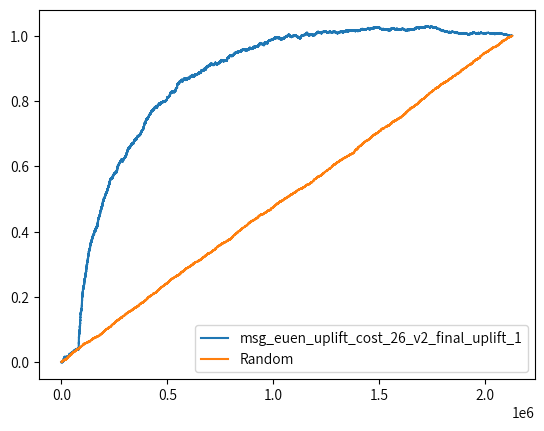

In [17]:
vis.draw_auuc(all_rct_data_pdf_v2, 
              treatments=['留存6张3元'], 
              ite_names=['msg_euen_uplift_cost_26_v2_final_uplift_1'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='DS空白',
              real_treatment='group_name_eve',
              show_curve=1)

msg_euen_uplift_cost_26_v3_final_uplift_1    0.944574
Random                                       0.504849
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v3_final_uplift_1    0.944574
 Random                                       0.504849
 dtype: float64]

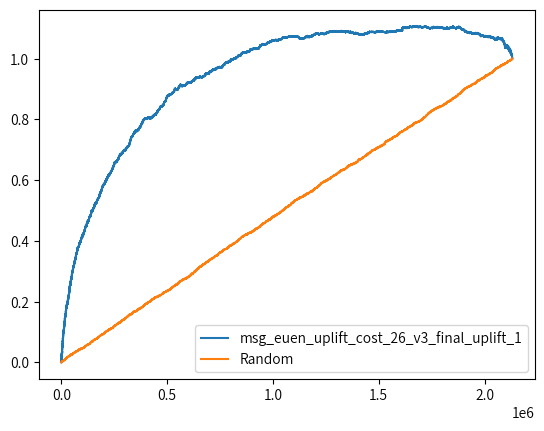

In [19]:
vis.draw_auuc(all_rct_data_pdf_v3, 
              treatments=['留存6张3元'], 
              ite_names=['msg_euen_uplift_cost_26_v3_final_uplift_1'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='DS空白',
              real_treatment='group_name_eve',
              show_curve=1)

In [203]:
all_rct_data_pdf_v4.columns

Index(['group_name_eve', 'pid', 'oneid', 'flowtree_group_name', 'send_cnt',
       'send_success_cnt', 'send_cost', 'send_remind_cost', 'outcall_cost',
       'remind_cost', 'coupon_cost', 'outcall_coupon_cost',
       'outcall_coupon2_cost', 'uv_label', 'pv_label', 'uv_label_7d',
       'pv_label_7d', 'cost', 'cost_7d', 'dt', 'fin_order_wxmini_28d',
       'fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v4_final_uplift_1',
       'msg_euen_uplift_cost_26_v4_final_uplift_2',
       'msg_euen_uplift_cost_26_v4_final_uplift_3',
       'msg_euen_uplift_cost_26_v4_final_uplift_4',
       'msg_euen_uplift_cost_26_v4_final_cost_1',
       'msg_euen_uplift_cost_26_v4_final_cost_2',
       'msg_euen_uplift_cost_26_v4_final_cost_3',
       'msg_euen_uplift_cost_26_v4_final_cost_4',
       'msg_euen_uplift_cost_26_v4_final_uplift_diff_2_1',
       'msg_euen_uplift_cost_26_v4_final_uplift_diff_3_1',
       'msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1',
       'msg_euen_uplift_cost_26_v4

In [215]:
all_rct_data_pdf_v4['dt'].max()

'2026-09-13'

In [207]:
all_rct_data_pdf_v4_use = all_rct_data_pdf_v4[all_rct_data_pdf_v4['dt'].between('2026-08-15', '2026-08-21')]

In [209]:
all_rct_data_pdf_v4_use = all_rct_data_pdf_v4[all_rct_data_pdf_v4['dt'].between('2026-08-19', '2026-08-25')]

msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1    1.000584
Random                                              0.602825
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1    1.000584
 Random                                              0.602825
 dtype: float64]

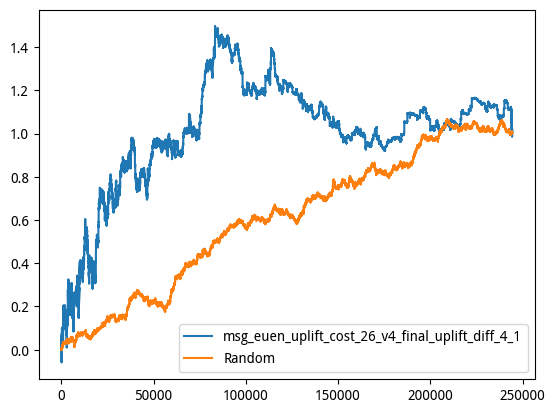

In [210]:
vis.draw_auuc(all_rct_data_pdf_v4_use, 
              treatments=['留存6张5元'], 
              ite_names=['msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='留存6张3元',
              real_treatment='group_name_eve',
              show_curve=1)

msg_euen_uplift_cost_26_v4_final_uplift_1    1.006109
Random                                       0.504849
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v4_final_uplift_1    1.006109
 Random                                       0.504849
 dtype: float64]

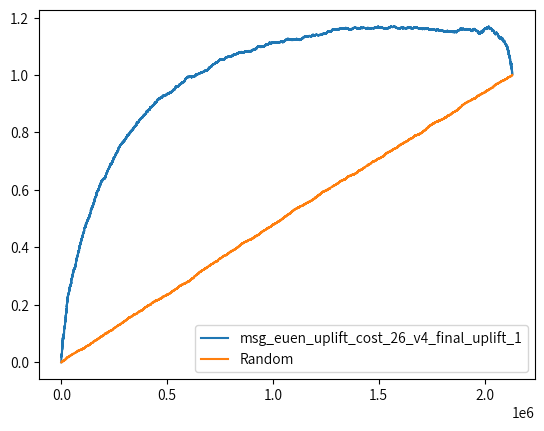

In [22]:
vis.draw_auuc(all_rct_data_pdf_v4, 
              treatments=['留存6张3元'], 
              ite_names=['msg_euen_uplift_cost_26_v4_final_uplift_1'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='DS空白',
              real_treatment='group_name_eve',
              show_curve=1)

#### 10元留存5张3 - 空白

msg_euen_uplift_cost_26_v4_final_uplift_4    0.922536
Random                                       0.498215
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v4_final_uplift_4    0.922536
 Random                                       0.498215
 dtype: float64]

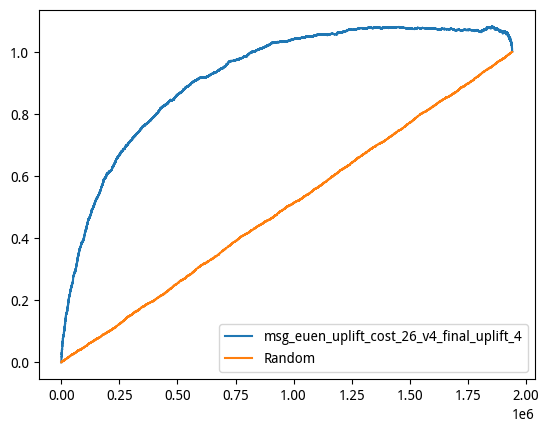

In [54]:
vis.draw_auuc(all_rct_data_pdf_v4, 
              treatments=['10元留存5张3'], 
              ite_names=['msg_euen_uplift_cost_26_v4_final_uplift_4'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='DS空白',
              real_treatment='group_name_eve',
              show_curve=1)

#### 8元留存5张3 - 空白

msg_euen_uplift_cost_26_v3_final_uplift_2    0.977297
Random                                       0.501527
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v3_final_uplift_2    0.977297
 Random                                       0.501527
 dtype: float64]

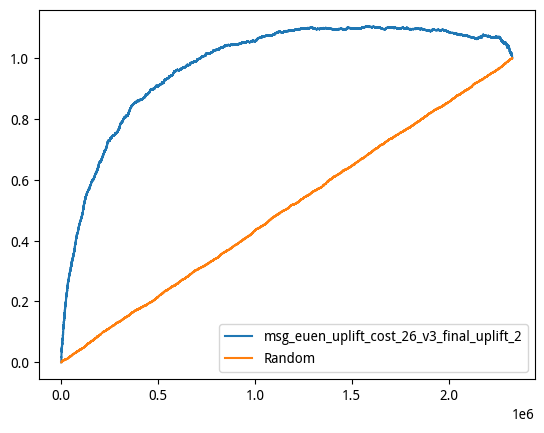

In [34]:
vis.draw_auuc(all_rct_data_pdf_v3, 
              treatments=['8元留存5张3'], 
              ite_names=['msg_euen_uplift_cost_26_v3_final_uplift_2'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='DS空白',
              real_treatment='group_name_eve',
              show_curve=1)

msg_euen_uplift_cost_26_v3_final_uplift_3    0.909475
Random                                       0.499456
dtype: float64
****************************************


[msg_euen_uplift_cost_26_v3_final_uplift_3    0.909475
 Random                                       0.499456
 dtype: float64]

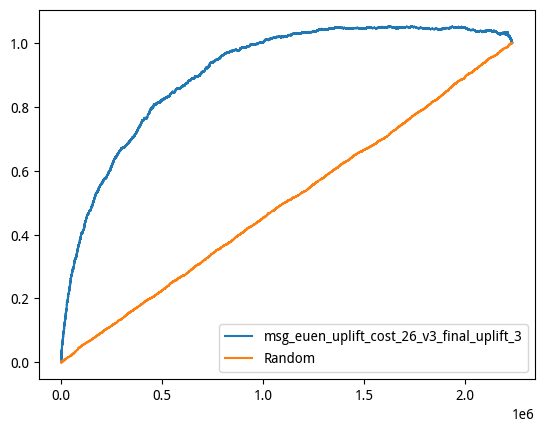

In [33]:
vis.draw_auuc(all_rct_data_pdf_v3, 
              treatments=['留存6张5元'], 
              ite_names=['msg_euen_uplift_cost_26_v3_final_uplift_3'],
              label_col='pv_label_7d',
              curve_type='auuc',
              control_group_name='DS空白',
              real_treatment='group_name_eve',
              show_curve=1)

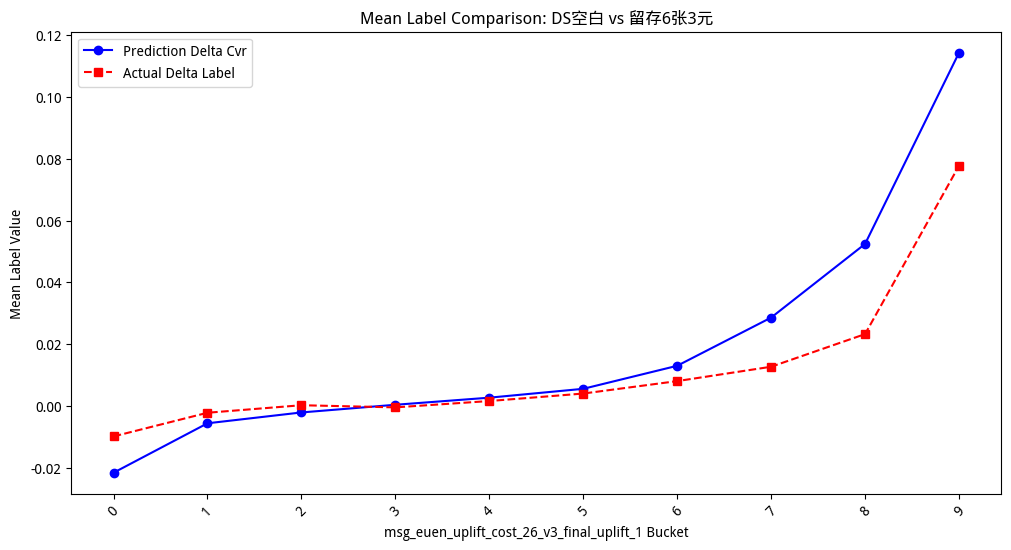

In [28]:
ans_63_control = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v3,
    prob_t='msg_euen_uplift_cost_26_v3_final_uplift_1',
    prob_c='none', 
    label_col='pv_label_7d', # 指定label列名
    group_t='留存6张3元', # 指定T组组名
    group_c='DS空白', # 指定C组组名
    group_col='group_name_eve',
    is_in_treat_compare=False)

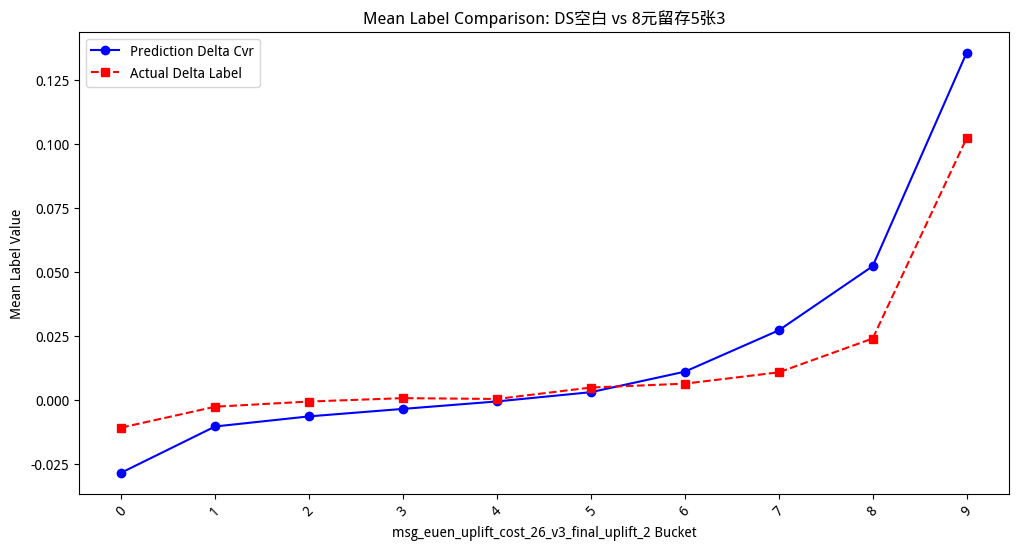

In [36]:
ans_63_control = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v3,
    prob_t='msg_euen_uplift_cost_26_v3_final_uplift_2',
    prob_c='none', 
    label_col='pv_label_7d', # 指定label列名
    group_t='8元留存5张3', # 指定T组组名
    group_c='DS空白', # 指定C组组名
    group_col='group_name_eve',
    is_in_treat_compare=False)

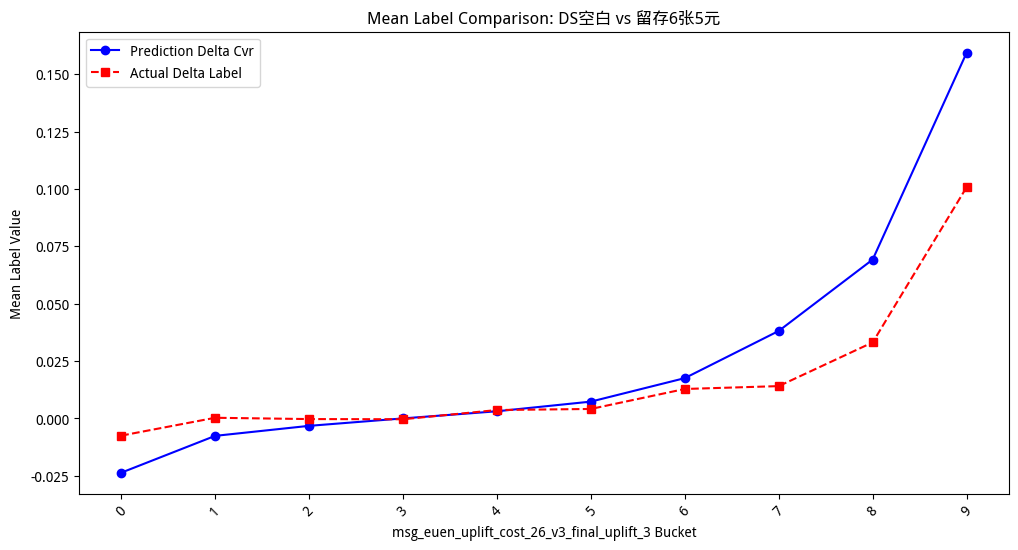

In [35]:
ans_63_control = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v3,
    prob_t='msg_euen_uplift_cost_26_v3_final_uplift_3',
    prob_c='none', 
    label_col='pv_label_7d', # 指定label列名
    group_t='留存6张5元', # 指定T组组名
    group_c='DS空白', # 指定C组组名
    group_col='group_name_eve',
    is_in_treat_compare=False)

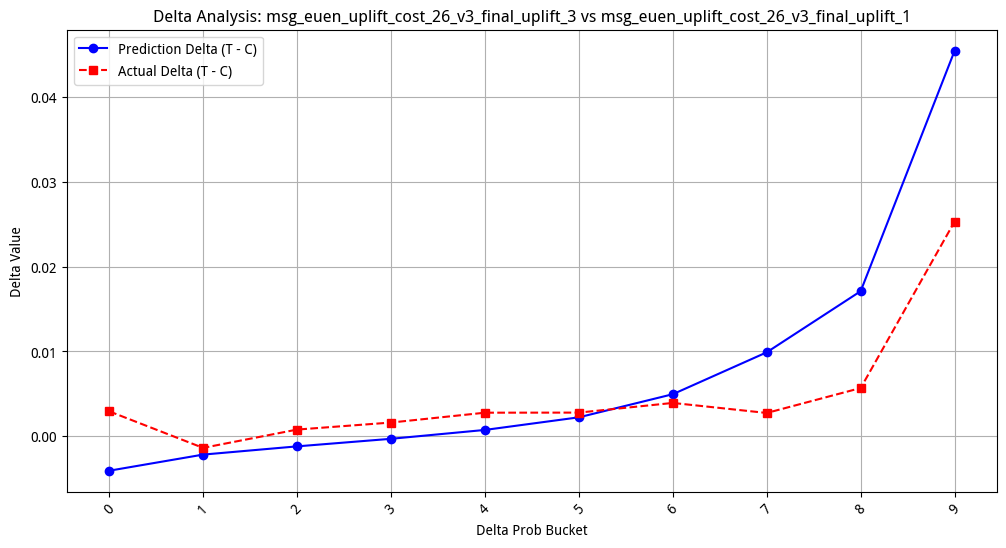

In [29]:
ans_65_63 = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v3,
                      prob_t='msg_euen_uplift_cost_26_v3_final_uplift_3',
                      prob_c='msg_euen_uplift_cost_26_v3_final_uplift_1', 
                      label_col='pv_label_7d',
                      group_t='留存6张5元',
                      group_c='留存6张3元',
                      group_col='group_name_eve',
                      is_in_treat_compare=True)

## 两动作增量差与模型diff输出检查

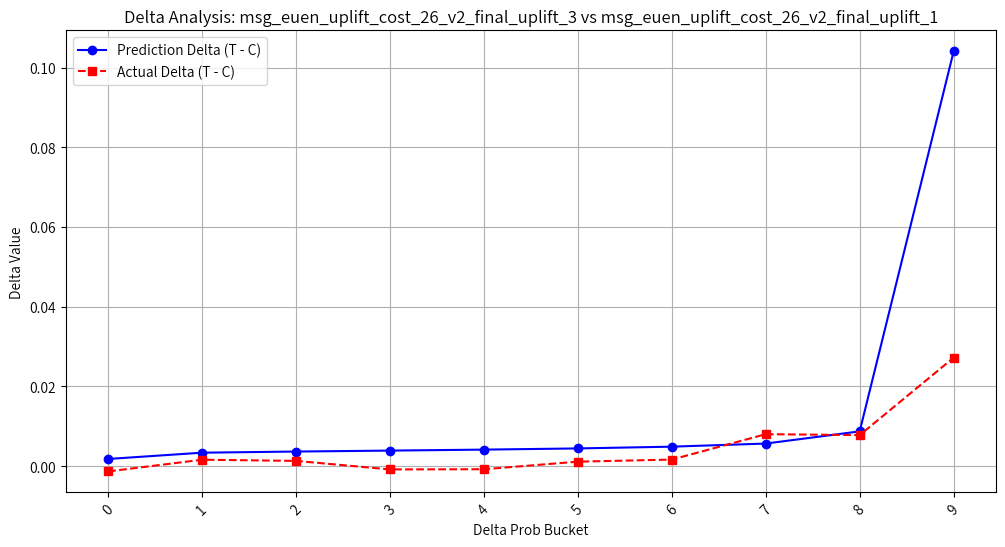

In [29]:
ans_65_63 = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v2,
      prob_t='msg_euen_uplift_cost_26_v2_final_uplift_3',
      prob_c='msg_euen_uplift_cost_26_v2_final_uplift_1', 
      label_col='pv_label_7d',
      group_t='留存6张5元',
      group_c='留存6张3元',
      group_col='group_name_eve',
      is_in_treat_compare=True)

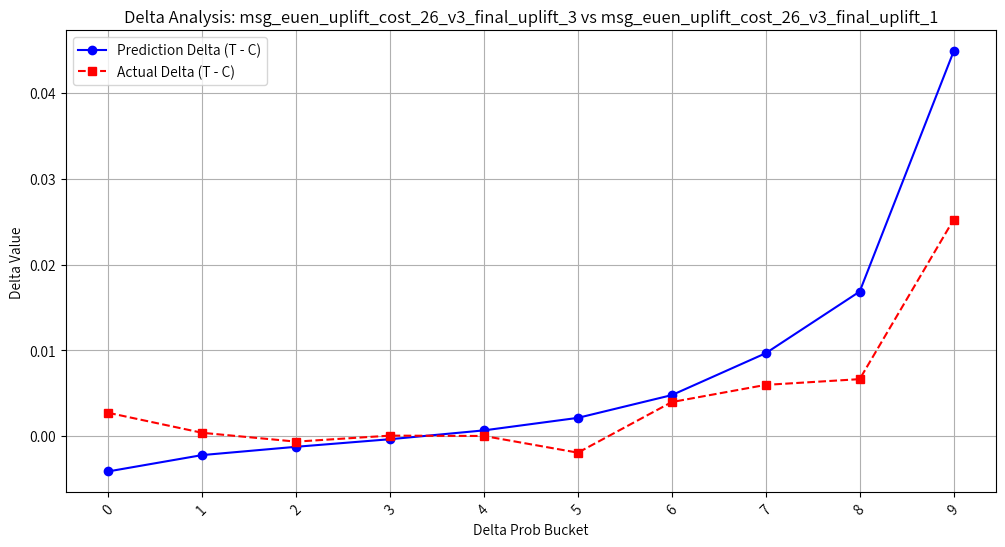

In [23]:
ans_65_63 = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v3,
      prob_t='msg_euen_uplift_cost_26_v3_final_uplift_3',
      prob_c='msg_euen_uplift_cost_26_v3_final_uplift_1', 
      label_col='pv_label_7d',
      group_t='留存6张5元',
      group_c='留存6张3元',
      group_col='group_name_eve',
      is_in_treat_compare=True)

In [26]:
all_rct_data_pdf_v4['dt'].unique()

array(['2026-08-27', '2026-08-14', '2026-08-12', '2026-08-20',
       '2026-08-29', '2026-08-13', '2026-08-28', '2026-08-15',
       '2026-09-02', '2026-08-26', '2026-09-03', '2026-09-04',
       '2026-08-30', '2026-08-11', '2026-08-22', '2026-08-23',
       '2026-08-24', '2026-08-18', '2026-08-31', '2026-08-16',
       '2026-08-17', '2026-08-25', '2026-08-21', '2026-09-01',
       '2026-08-19'], dtype=object)

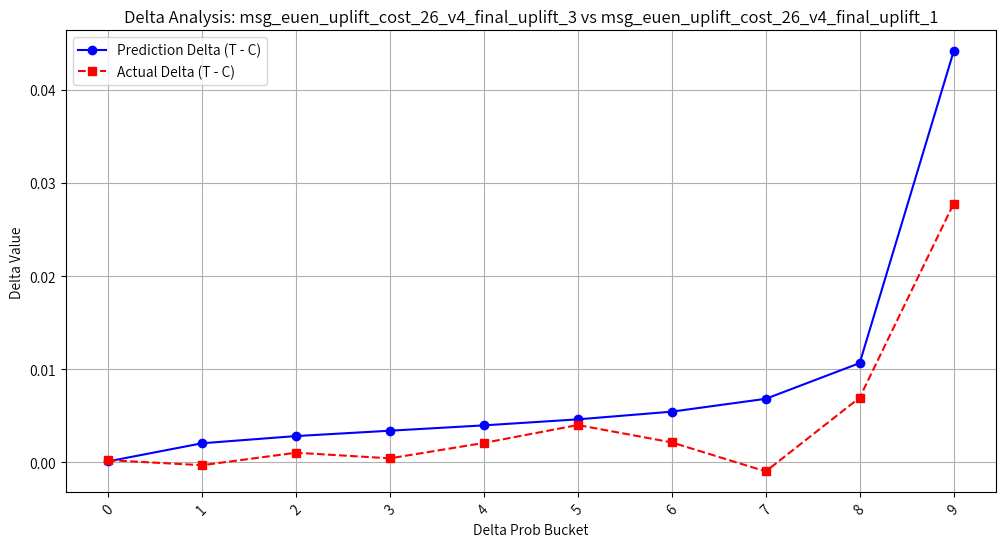

In [24]:
ans_65_63 = pandas_delta_cvr_simulate_gap(all_rct_data_pdf_v4,
      prob_t='msg_euen_uplift_cost_26_v4_final_uplift_3',
      prob_c='msg_euen_uplift_cost_26_v4_final_uplift_1', 
      label_col='pv_label_7d',
      group_t='留存6张5元',
      group_c='留存6张3元',
      group_col='group_name_eve',
      is_in_treat_compare=True)

## 组合公式排序

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

LAMBDA = 0.1218002994
TARGET_CAC = 5.6
ALPHA = LAMBDA / (1 + LAMBDA * TARGET_CAC)
N_BINS = 10

TRAIN_DTS = pd.date_range(
    '2026-08-12', '2026-08-19'
).strftime('%Y-%m-%d').tolist()

VAL_DTS = pd.date_range(
    '2026-08-20', '2026-08-26'
).strftime('%Y-%m-%d').tolist()

GROUPS = [
    '留存6张3元',
    '留存6张5元',
    'DS空白',
    '10元留存5张3',
]

PREFIX = 'msg_euen_uplift_cost_26_v4_final_'

# 源模型头编号保持1、3、4，不重新编号
ACTION_CONFIG = {
    'left_63':   {'group': '留存6张3元',   'head': 1},
    'left_65':   {'group': '留存6张5元',   'head': 3},
    'left_1053': {'group': '10元留存5张3', 'head': 4},
    'C':        {'group': 'DS空白',       'head': None},
}

# 同分优先级与当前策略保持一致
ACTION_ORDER = ['left_63', 'C', 'left_65', 'left_1053']

diagnosis_df = all_rct_data_pdf_v4.loc[
    all_rct_data_pdf_v4['group_name_eve'].isin(GROUPS)
].copy()

diagnosis_df['dt'] = pd.to_datetime(
    diagnosis_df['dt']
).dt.strftime('%Y-%m-%d')

for action, spec in ACTION_CONFIG.items():
    if action == 'C':
        diagnosis_df[f'reward_{action}'] = 0.0
        diagnosis_df[f'pred_cost_{action}'] = 0.0
    else:
        head = spec['head']
        diagnosis_df[f'reward_{action}'] = (
            diagnosis_df[PREFIX + f'uplift_{head}'].astype('float64')
        )
        diagnosis_df[f'pred_cost_{action}'] = (
            diagnosis_df[PREFIX + f'cost_{head}'].astype('float64')
        )

    diagnosis_df[f'combine_{action}'] = (
        diagnosis_df[f'reward_{action}']
        - ALPHA * diagnosis_df[f'pred_cost_{action}']
    )

# 还原固定C、λ下的推荐动作，供后续切片诊断
combine_scores = pd.DataFrame({
    action: diagnosis_df[f'combine_{action}']
    for action in ACTION_ORDER
})
diagnosis_df['recommended_action'] = combine_scores.idxmax(axis=1)

combine_train_df = diagnosis_df.loc[
    diagnosis_df['dt'].isin(TRAIN_DTS)
].copy()

combine_val_df = diagnosis_df.loc[
    diagnosis_df['dt'].isin(VAL_DTS)
].copy()

print(f'固定 λ={LAMBDA:.10f}, C={TARGET_CAC:g}, alpha={ALPHA:.8f}')
print('训练集行数：', len(combine_train_df))
print('验证集行数：', len(combine_val_df))

固定 λ=0.1218002994, C=5.6, alpha=0.07241045
训练集行数： 930969
验证集行数： 792415


In [109]:
def diagnose_combine_pair(
    df,
    action_a,
    action_b,
    alpha,
    action_config,
    bins=10,
    dataset_name='Validation',
):
    """
    比较动作a相对动作b的组合优势。

    预测：
        (reward_a - reward_b)
        - alpha * (pred_cost_a - pred_cost_b)

    实际：
        (mean_pv_a - mean_pv_b)
        - alpha * (mean_cost_a - mean_cost_b)

    返回：
        bucket_stats：分桶明细
        summary：描述性诊断指标
    """
    if df.empty:
        raise ValueError('诊断样本为空')

    group_a = action_config[action_a]['group']
    group_b = action_config[action_b]['group']

    # 保留计算必需列，不修改输入
    work = df[
        ['group_name_eve', 'pv_label_7d', 'cost_7d']
    ].copy()

    work['pred_reward_diff'] = (
        df[f'reward_{action_a}'] - df[f'reward_{action_b}']
    )
    work['pred_cost_diff'] = (
        df[f'pred_cost_{action_a}'] - df[f'pred_cost_{action_b}']
    )
    work['pred_combine_diff'] = (
        work['pred_reward_diff'] - alpha * work['pred_cost_diff']
    )

    # 假设预测已有效；避免999作为正常分数进入图中
    prediction_cols = [
        f'reward_{action_a}', f'reward_{action_b}',
        f'pred_cost_{action_a}', f'pred_cost_{action_b}',
    ]
    prediction_values = df[prediction_cols].to_numpy(dtype=float)

    if (
        not np.isfinite(prediction_values).all()
        or (prediction_values == 999).any()
    ):
        raise ValueError(
            f'{action_a} vs {action_b}包含无效预测，请先处理对应动作分数'
        )

    # 数值桶编号保证按预测分数从低到高展示
    if work['pred_combine_diff'].nunique() == 1:
        work['bucket'] = 1
    else:
        bucket_codes = pd.qcut(
            work['pred_combine_diff'],
            q=bins,
            labels=False,
            duplicates='drop',
        )
        # 大量同分可能使qcut退化为没有可用区间
        work['bucket'] = (
            1 if bucket_codes.isna().all()
            else bucket_codes + 1
        )

    rows = []

    for bucket, layer in work.groupby('bucket', sort=True):
        actual_a = layer.loc[layer['group_name_eve'] == group_a]
        actual_b = layer.loc[layer['group_name_eve'] == group_b]
        supported = len(actual_a) > 0 and len(actual_b) > 0

        mean_pv_a = actual_a['pv_label_7d'].mean()
        mean_pv_b = actual_b['pv_label_7d'].mean()
        mean_cost_a = actual_a['cost_7d'].mean()
        mean_cost_b = actual_b['cost_7d'].mean()

        observed_reward_diff = (
            mean_pv_a - mean_pv_b if supported else np.nan
        )
        observed_cost_diff = (
            mean_cost_a - mean_cost_b if supported else np.nan
        )

        rows.append({
            'bucket': int(bucket),
            'n': len(layer),
            'n_a': len(actual_a),
            'n_b': len(actual_b),
            'supported': supported,
            'score_min': layer['pred_combine_diff'].min(),
            'score_max': layer['pred_combine_diff'].max(),
            'pred_reward_diff': layer['pred_reward_diff'].mean(),
            'observed_reward_diff': observed_reward_diff,
            'pred_cost_diff': layer['pred_cost_diff'].mean(),
            'observed_cost_diff': observed_cost_diff,
            'pred_combine_diff': layer['pred_combine_diff'].mean(),
            'observed_combine_diff': (
                observed_reward_diff - alpha * observed_cost_diff
                if supported else np.nan
            ),
        })

    stats = pd.DataFrame(rows).sort_values('bucket').reset_index(drop=True)

    # 以下都是描述性指标，不代表统计显著性
    valid = stats.loc[
        stats['supported']
        & np.isfinite(stats['observed_combine_diff'])
    ].copy()

    rank_corr = np.nan
    if (
        len(valid) >= 2
        and valid['pred_combine_diff'].nunique() > 1
        and valid['observed_combine_diff'].nunique() > 1
    ):
        rank_corr = (
            valid['pred_combine_diff'].rank()
            .corr(valid['observed_combine_diff'].rank())
        )

    # 只检查相邻且均有效的桶，不能跨缺失桶计数
    comparable = (
        stats['supported']
        & stats['supported'].shift(1, fill_value=False)
        & stats['observed_combine_diff'].notna()
        & stats['observed_combine_diff'].shift(1).notna()
    )
    decreases = (
        comparable
        & stats['observed_combine_diff'].diff().lt(0)
    )

    summary = {
        'dataset': dataset_name,
        'pair': f'{action_a} - {action_b}',
        'alpha': alpha,
        'n': len(work),
        'actual_bins': len(stats),
        'unsupported_bins': int((~stats['supported']).sum()),
        'bucket_rank_correlation': rank_corr,
        'comparable_adjacent_pairs': int(comparable.sum()),
        'decreasing_adjacent_pairs': int(decreases.sum()),
        'bucket_weighted_mae': (
            np.average(
                abs(
                    valid['pred_combine_diff']
                    - valid['observed_combine_diff']
                ),
                weights=valid['n'],
            )
            if len(valid) else np.nan
        ),
    }

    # 三张图：桶间趋势、值准、两组支持人数
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    axes[0].plot(
        stats['bucket'], stats['pred_combine_diff'],
        'o-', label='Predicted'
    )
    axes[0].plot(
        stats['bucket'], stats['observed_combine_diff'],
        's--', label='RCT observed'
    )
    axes[0].axhline(0, color='gray', linewidth=1)
    axes[0].set_title('Combined advantage by score bucket')
    axes[0].set_xlabel('Bucket: low to high predicted score')
    axes[0].set_ylabel('Delta PV - alpha * delta cost')
    axes[0].legend()

    axes[1].scatter(
        valid['pred_combine_diff'],
        valid['observed_combine_diff'],
    )
    if len(valid):
        values = np.r_[
            valid['pred_combine_diff'].to_numpy(),
            valid['observed_combine_diff'].to_numpy(),
        ]
        lower, upper = values.min(), values.max()
        padding = max((upper - lower) * 0.05, 1e-6)
        axes[1].plot(
            [lower - padding, upper + padding],
            [lower - padding, upper + padding],
            '--', color='gray', label='Observed = predicted'
        )
        axes[1].legend()
    axes[1].axhline(0, color='lightgray', linewidth=1)
    axes[1].axvline(0, color='lightgray', linewidth=1)
    axes[1].set_title('Bucket calibration')
    axes[1].set_xlabel('Predicted combined advantage')
    axes[1].set_ylabel('RCT observed combined advantage')

    x = np.arange(len(stats))
    axes[2].bar(x - 0.2, stats['n_a'], width=0.4, label=action_a)
    axes[2].bar(x + 0.2, stats['n_b'], width=0.4, label=action_b)
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(stats['bucket'])
    axes[2].set_title('RCT sample counts')
    axes[2].set_xlabel('Bucket')
    axes[2].set_ylabel('Rows')
    axes[2].legend()

    for ax in axes:
        ax.grid(True, alpha=0.25)

    fig.suptitle(
        f'{dataset_name}: {action_a} minus {action_b}, '
        f'alpha={alpha:.6f}'
    )
    plt.tight_layout()
    plt.show()

    return stats, summary

留存6张3元 相对 DS空白


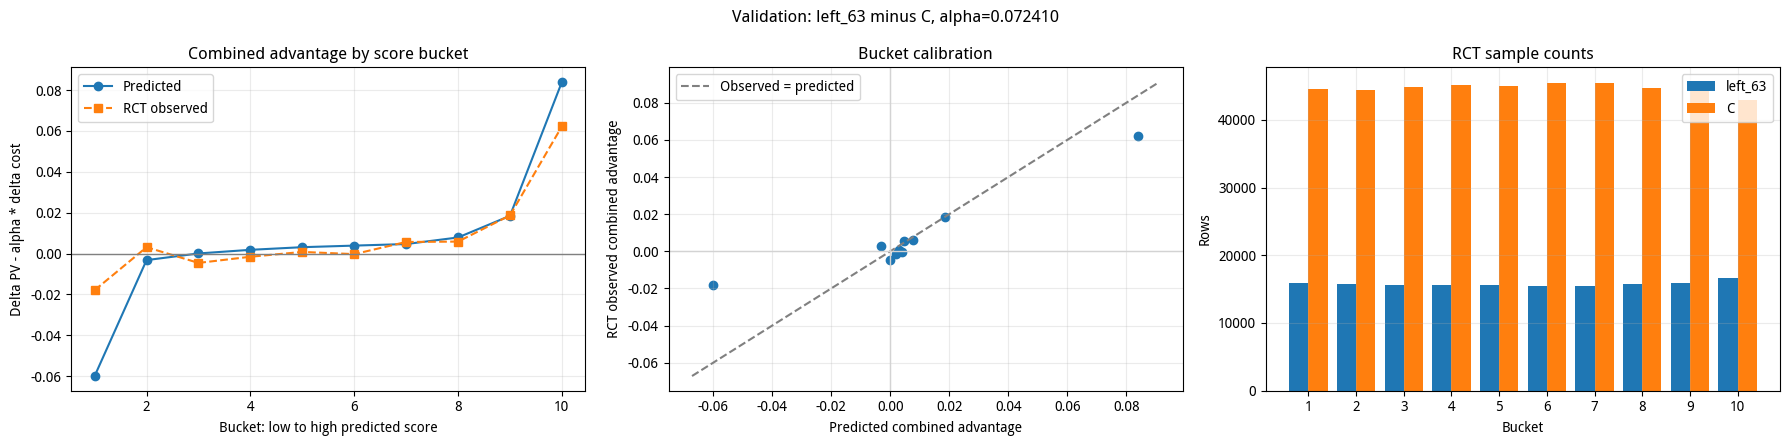

,bucket,n,n_a,n_b,supported,score_min,score_max,pred_reward_diff,observed_reward_diff,pred_cost_diff,observed_cost_diff,pred_combine_diff,observed_combine_diff
0,1,79242,15897,44590,True,-0.664613,-0.007399,-0.058167,-0.016201,0.025054,0.024345,-0.059981,-0.017964
1,2,79241,15786,44357,True,-0.007398,-0.001074,-0.002964,0.003653,0.003733,0.007805,-0.003234,0.003088
2,3,79242,15618,44867,True,-0.001074,0.000984,0.000511,-0.004203,0.006714,0.005587,0.000024,-0.004608
3,4,79241,15587,45127,True,0.000984,0.002549,0.002592,-0.000805,0.010933,0.010836,0.001800,-0.001589
4,5,79242,15598,44972,True,0.002549,0.003537,0.004311,0.002411,0.016750,0.022644,0.003098,0.000771
5,6,79241,15455,45464,True,0.003537,0.004187,0.005519,0.001738,0.022827,0.028245,0.003866,-0.000307
6,7,79241,15389,45468,True,0.004187,0.005339,0.006704,0.007992,0.028667,0.032391,0.004628,0.005646
7,8,79242,15821,44677,True,0.005339,0.011390,0.011401,0.009802,0.048968,0.054783,0.007855,0.005835
8,9,79241,15901,44519,True,0.011390,0.029122,0.024606,0.025513,0.085178,0.094733,0.018438,0.018654
9,10,79242,16640,42916,True,0.029122,0.935791,0.103648,0.081517,0.272050,0.266422,0.083949,0.062225


留存6张5元 相对 DS空白


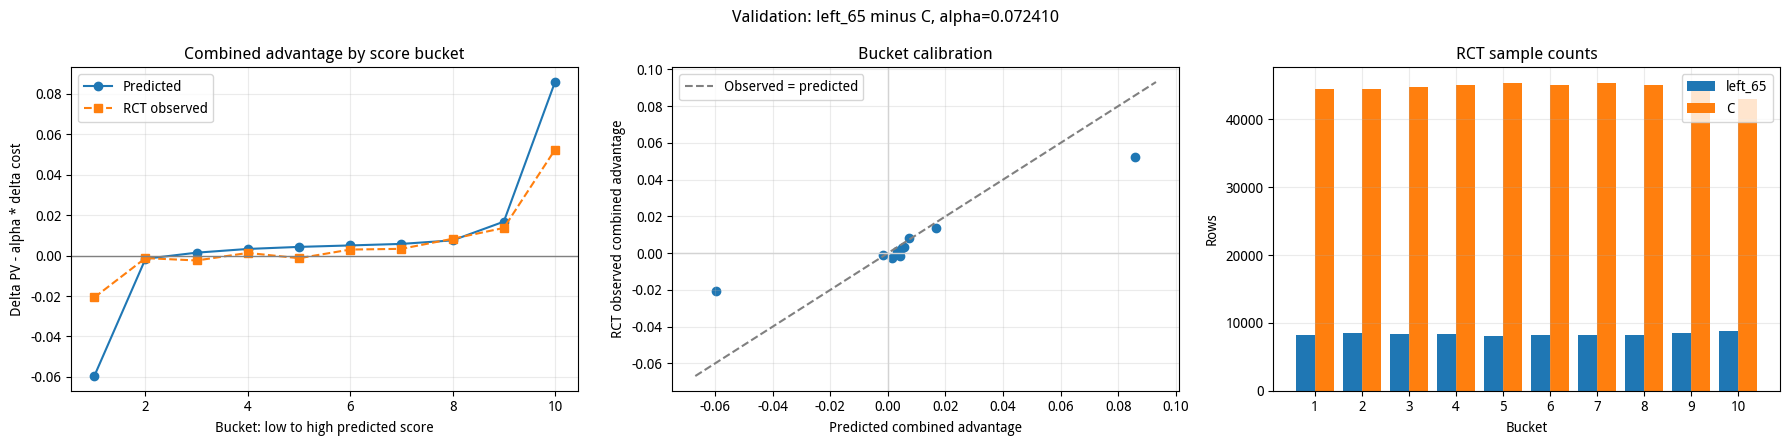

,bucket,n,n_a,n_b,supported,score_min,score_max,pred_reward_diff,observed_reward_diff,pred_cost_diff,observed_cost_diff,pred_combine_diff,observed_combine_diff
0,1,79242,8152,44491,True,-0.740138,-0.004476,-0.050604,-0.015357,0.123778,0.074046,-0.059567,-0.020718
1,2,79241,8478,44439,True,-0.004476,0.000220,0.000438,0.000130,0.028037,0.019156,-0.001592,-0.001257
2,3,79242,8352,44712,True,0.000220,0.002504,0.003578,-0.001078,0.029677,0.018722,0.001429,-0.002434
3,4,79241,8302,45005,True,0.002504,0.003866,0.006321,0.005313,0.042193,0.055273,0.003266,0.001310
4,5,79242,8098,45306,True,0.003866,0.004660,0.008046,0.001540,0.051969,0.039380,0.004283,-0.001312
5,6,79241,8179,45115,True,0.004660,0.005355,0.009022,0.007242,0.055467,0.059104,0.005006,0.002962
6,7,79241,8248,45392,True,0.005355,0.006249,0.010102,0.007292,0.059926,0.054780,0.005763,0.003325
7,8,79242,8225,45004,True,0.006249,0.010020,0.015222,0.016487,0.106492,0.113040,0.007511,0.008301
8,9,79241,8442,44526,True,0.010020,0.027577,0.033717,0.026624,0.234187,0.179131,0.016760,0.013653
9,10,79242,8769,42967,True,0.027577,1.240615,0.146073,0.095483,0.832354,0.595923,0.085802,0.052332


10元留存5张3 相对 DS空白


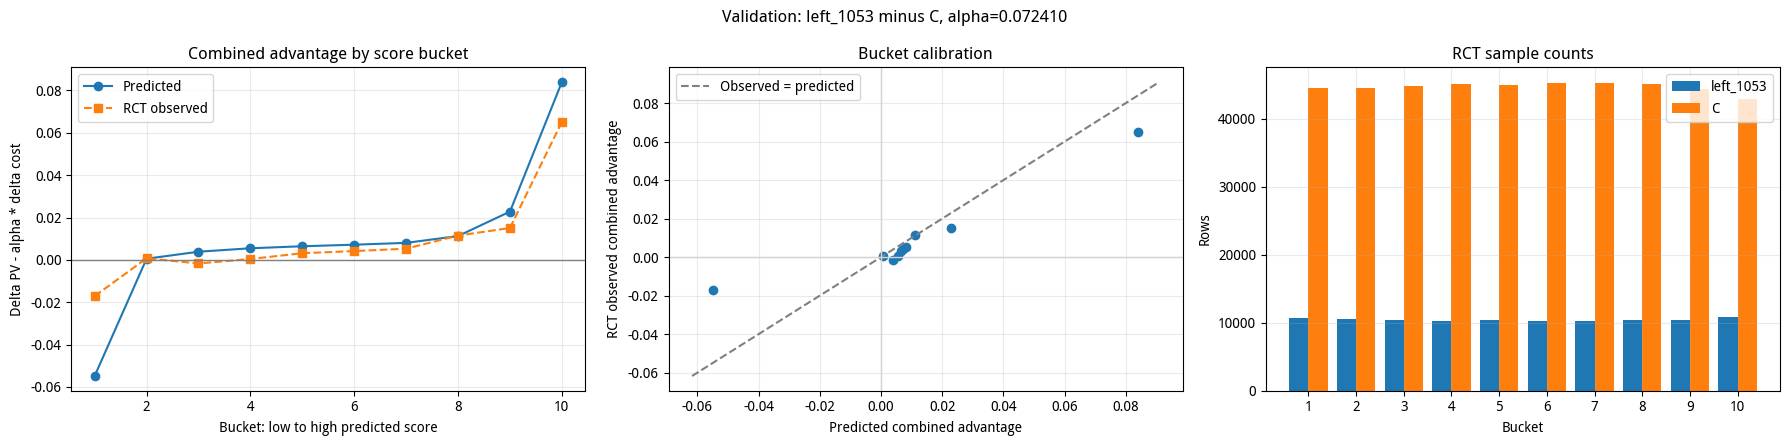

,bucket,n,n_a,n_b,supported,score_min,score_max,pred_reward_diff,observed_reward_diff,pred_cost_diff,observed_cost_diff,pred_combine_diff,observed_combine_diff
0,1,79242,10654,44508,True,-0.703071,-0.003235,-0.047185,-0.013056,0.105742,0.055814,-0.054842,-0.017097
1,2,79241,10490,44496,True,-0.003235,0.002675,0.002323,0.002462,0.024589,0.023648,0.000542,0.000750
2,3,79242,10438,44849,True,0.002675,0.004840,0.006245,0.000534,0.032836,0.030674,0.003867,-0.001687
3,4,79241,10306,45101,True,0.004840,0.006030,0.009581,0.004413,0.056508,0.055015,0.005489,0.000429
4,5,79242,10469,45016,True,0.006030,0.006823,0.010975,0.007442,0.062576,0.059188,0.006443,0.003156
5,6,79241,10212,45217,True,0.006823,0.007541,0.011844,0.008364,0.064463,0.058076,0.007176,0.004158
6,7,79241,10301,45319,True,0.007541,0.008755,0.013544,0.011317,0.075984,0.083182,0.008042,0.005294
7,8,79242,10334,45085,True,0.008755,0.015167,0.022786,0.021219,0.159197,0.134518,0.011258,0.011479
8,9,79241,10447,44463,True,0.015167,0.034057,0.043343,0.031420,0.283585,0.225863,0.022808,0.015065
9,10,79242,10870,42903,True,0.034058,0.848564,0.141398,0.116196,0.792706,0.704150,0.083998,0.065208


留存6张5元 相对 留存6张3元


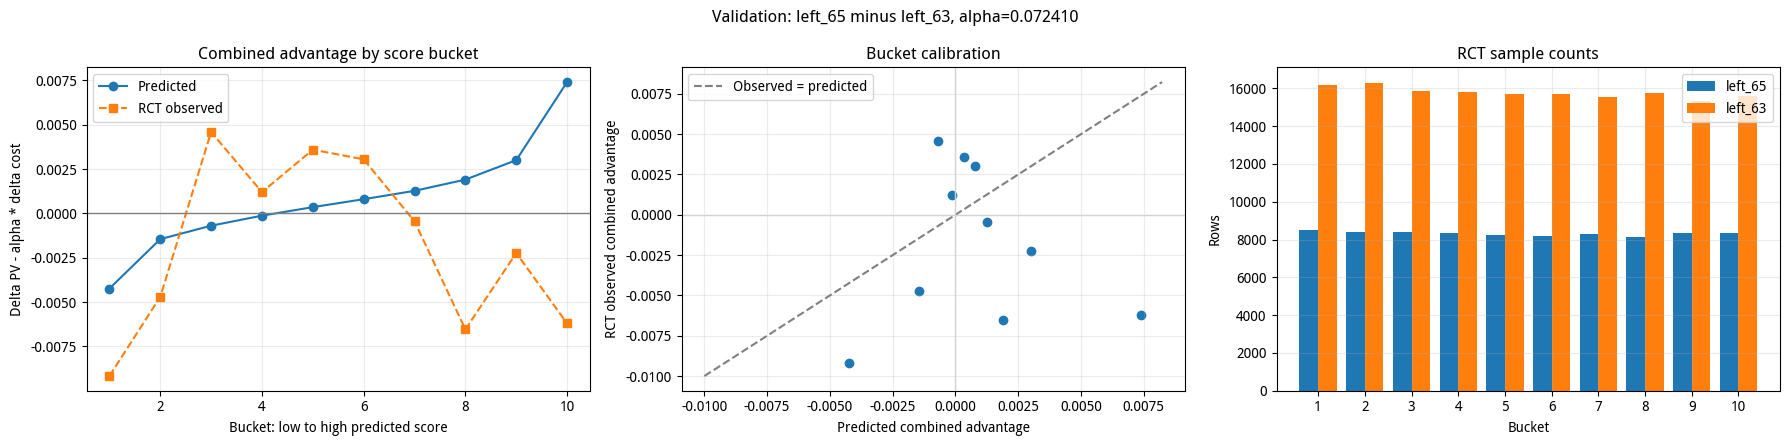

,bucket,n,n_a,n_b,supported,score_min,score_max,pred_reward_diff,observed_reward_diff,pred_cost_diff,observed_cost_diff,pred_combine_diff,observed_combine_diff
0,1,79242,8522,16183,True,-0.075525,-0.001960,0.013325,0.000425,0.242553,0.132461,-0.004238,-0.009167
1,2,79241,8381,16296,True,-0.001960,-0.001025,0.010805,0.002187,0.169264,0.095207,-0.001452,-0.004707
2,3,79242,8413,15854,True,-0.001025,-0.000392,0.008643,0.011951,0.128950,0.101745,-0.000694,0.004584
3,4,79241,8364,15816,True,-0.000392,0.000120,0.006952,0.006103,0.097798,0.067736,-0.000129,0.001198
4,5,79242,8250,15681,True,0.000120,0.000577,0.005774,0.008430,0.074876,0.066846,0.000352,0.003590
5,6,79241,8207,15701,True,0.000577,0.001024,0.005063,0.005653,0.058892,0.035988,0.000799,0.003047
6,7,79241,8303,15539,True,0.001024,0.001541,0.004717,0.002358,0.047601,0.038798,0.001271,-0.000451
7,8,79242,8126,15740,True,0.001541,0.002350,0.004724,-0.004463,0.038933,0.028641,0.001904,-0.006537
8,9,79241,8329,15306,True,0.002350,0.003771,0.005215,-0.000940,0.030589,0.017848,0.003001,-0.002233
9,10,79242,8350,15576,True,0.003772,0.304824,0.018536,0.000209,0.153752,0.088582,0.007403,-0.006205


10元留存5张3 相对 留存6张3元


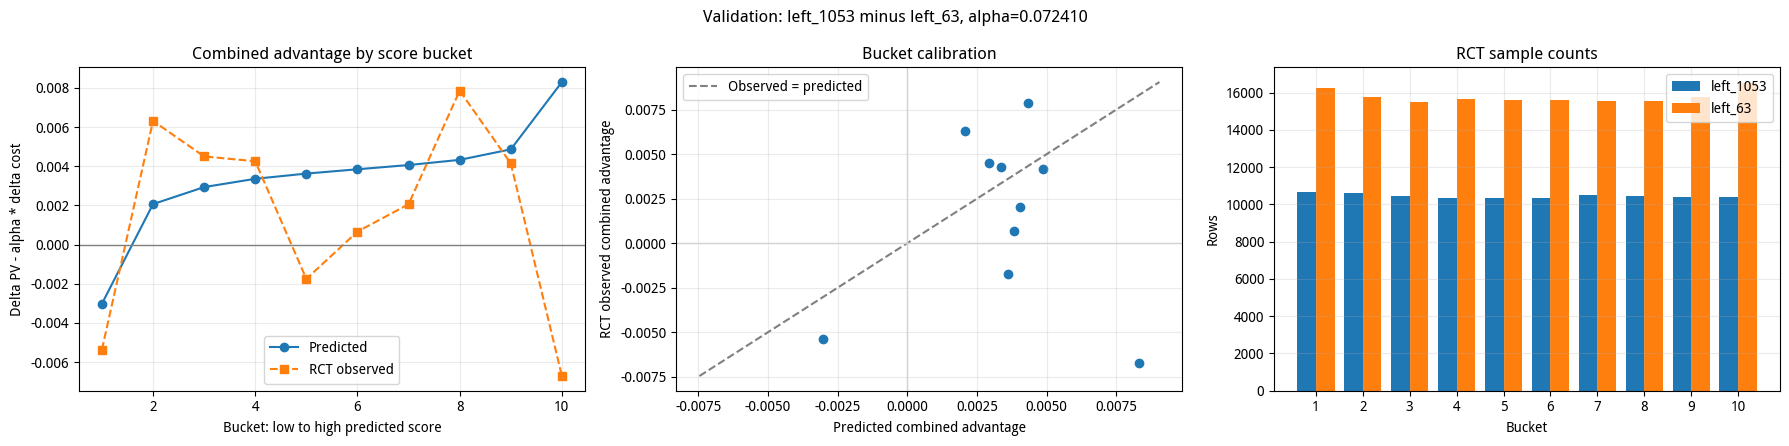

,bucket,n,n_a,n_b,supported,score_min,score_max,pred_reward_diff,observed_reward_diff,pred_cost_diff,observed_cost_diff,pred_combine_diff,observed_combine_diff
0,1,79242,10672,16226,True,-0.128690,0.001424,0.020784,0.015253,0.328768,0.284721,-0.003022,-0.005364
1,2,79241,10615,15777,True,0.001424,0.002601,0.012595,0.013635,0.145432,0.101118,0.002065,0.006313
2,3,79242,10438,15519,True,0.002601,0.003188,0.009772,0.011354,0.094451,0.094669,0.002933,0.004499
3,4,79241,10351,15655,True,0.003188,0.003503,0.007706,0.008610,0.060072,0.060179,0.003357,0.004252
4,5,79242,10338,15585,True,0.003503,0.003736,0.007108,0.000889,0.048130,0.036478,0.003623,-0.001753
5,6,79241,10339,15577,True,0.003736,0.003948,0.007032,0.003866,0.044044,0.044267,0.003843,0.000661
6,7,79241,10519,15535,True,0.003948,0.004177,0.007248,0.004716,0.044039,0.036737,0.004059,0.002056
7,8,79242,10455,15545,True,0.004177,0.004502,0.008037,0.011767,0.051284,0.054005,0.004324,0.007857
8,9,79241,10388,15744,True,0.004502,0.005480,0.011825,0.008935,0.096176,0.066208,0.004860,0.004141
9,10,79242,10406,16529,True,0.005480,0.021242,0.024583,0.001320,0.224917,0.110928,0.008297,-0.006712


10元留存5张3 相对 留存6张5元


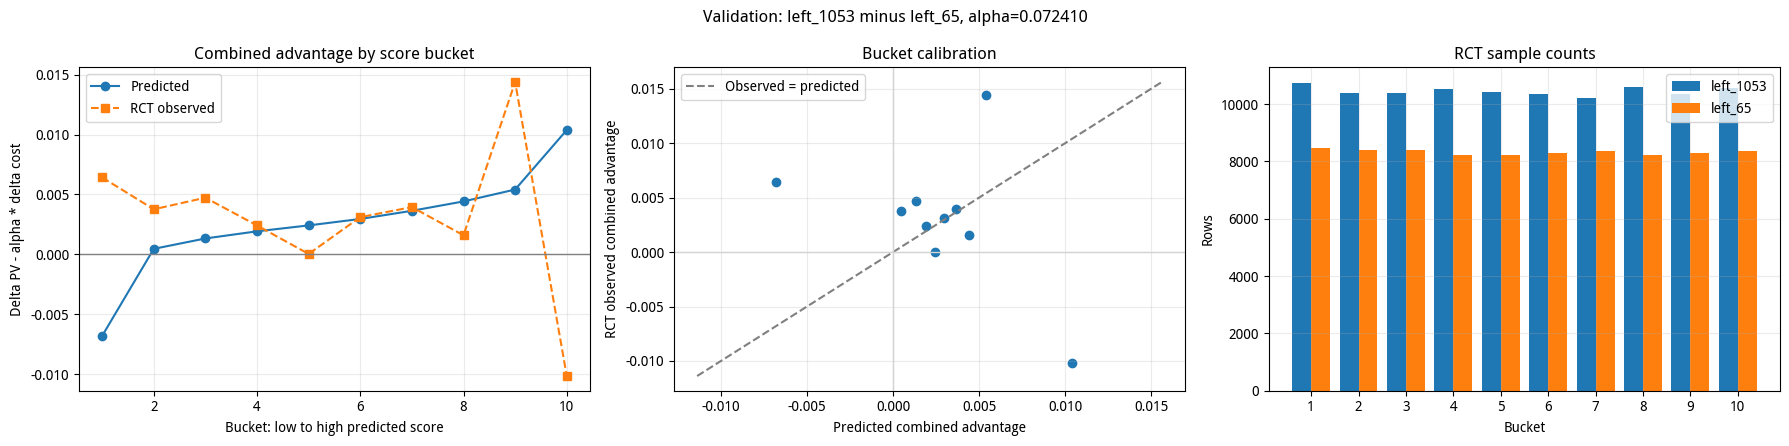

,bucket,n,n_a,n_b,supported,score_min,score_max,pred_reward_diff,observed_reward_diff,pred_cost_diff,observed_cost_diff,pred_combine_diff,observed_combine_diff
0,1,79242,10743,8466,True,-0.392051,-0.000172,-0.011982,0.008481,-0.071481,0.028457,-0.006806,0.006421
1,2,79241,10381,8381,True,-0.000171,0.000962,0.001216,0.005601,0.010416,0.025428,0.000462,0.003760
2,3,79242,10377,8391,True,0.000962,0.001652,0.002367,0.007179,0.014354,0.033847,0.001327,0.004728
3,4,79241,10527,8226,True,0.001652,0.002176,0.002992,0.002892,0.014762,0.006614,0.001923,0.002413
4,5,79242,10429,8236,True,0.002176,0.002665,0.003473,0.001215,0.014581,0.016317,0.002417,0.000034
5,6,79241,10335,8285,True,0.002665,0.003272,0.004010,0.003360,0.014580,0.003518,0.002954,0.003106
6,7,79241,10224,8358,True,0.003272,0.004014,0.004728,0.004603,0.015079,0.009099,0.003637,0.003944
7,8,79242,10598,8237,True,0.004014,0.004844,0.005681,0.002845,0.017425,0.017311,0.004419,0.001592
8,9,79241,10363,8303,True,0.004844,0.006195,0.007435,0.019509,0.027963,0.070805,0.005410,0.014382
9,10,79242,10544,8362,True,0.006195,0.051347,0.013016,-0.009955,0.036427,0.002726,0.010378,-0.010152


,dataset,pair,alpha,n,actual_bins,unsupported_bins,bucket_rank_correlation,comparable_adjacent_pairs,decreasing_adjacent_pairs,bucket_weighted_mae
0,Validation,left_63 - C,0.07241,792415,10,0,0.866667,9,2,0.008784
1,Validation,left_65 - C,0.07241,792415,10,0,0.939394,9,2,0.009245
2,Validation,left_1053 - C,0.07241,792415,10,0,0.963636,9,1,0.008437
3,Validation,left_65 - left_63,0.07241,792415,10,0,-0.115152,9,5,0.004928
4,Validation,left_1053 - left_63,0.07241,792415,10,0,-0.151515,9,5,0.003887
5,Validation,left_1053 - left_65,0.07241,792415,10,0,-0.345455,9,5,0.005559


In [110]:
coupon_actions = ['left_63', 'left_65', 'left_1053']

# 三张券分别相对空白
compare_pairs = [(action, 'C') for action in coupon_actions]

# 三组券间比较：后者相对前者
compare_pairs += [
    (higher, lower)
    for lower, higher in combinations(coupon_actions, 2)
]

combine_bucket_results = {}
combine_summaries = []

for action_a, action_b in compare_pairs:
    print(
        ACTION_CONFIG[action_a]['group'],
        '相对',
        ACTION_CONFIG[action_b]['group'],
    )

    bucket_stats, summary = diagnose_combine_pair(
        df=combine_val_df,
        action_a=action_a,
        action_b=action_b,
        alpha=ALPHA,
        action_config=ACTION_CONFIG,
        bins=N_BINS,
        dataset_name='Validation',
    )

    combine_bucket_results[(action_a, action_b)] = bucket_stats
    combine_summaries.append(summary)

    display(bucket_stats)

combine_summary_df = pd.DataFrame(combine_summaries)
display(combine_summary_df)

# 最严谨的在线运筹仿真方案

## 26_v4

In [132]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest)

bt = backtest.run_backtest(
    raw=all_rct_data_pdf_v4,
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    initial_params={
        "C": 5.6,
        "lambda": 0.1217217676,
    },
    cost_list=[i / 10 for i in range(40, 60)],
)

with pd.option_context(
    "display.precision", 12,
    "display.max_columns", None,
):
    display(bt["trajectory"])  # 七天参数继承、更新决策及选优集效果
    display(bt["daily"])       # 每天实际应用人群的后验回放
    display(bt["summary"])     # 两种策略的整周收益
    display(bt["comparison"])  # 自动选参与固定初始参数的差异

26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 65 on bigdata-rss-s2102-hdp888.nmg01.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 36 on bigdata-openeuler-s2102-hdp300.nmg01.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 32 on bigdata-s2102-ozone3433.nmg03.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 31 on bigdata-s2102-ozone3433.nmg03.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 38 on bigdata-openeuler-s2102-hdp300.nmg01.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 37 on bigdata-openeuler-s2102-hdp300.nmg01.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnScheduler: Lost executor 56 on bigdata-nmg-hdp6349.nmg01.diditaxi.com: Executor Process Lost
26/09/14 07:01:58 ERROR YarnClientSchedulerBackend: YARN application has exited unexpectedly with state KIL

,effective_dt,biz_date,train_start,train_end,selection_start,selection_end,old_C,old_lambda,C,lambda,status,old_selection_cac,old_selection_pv_per_user,chosen_selection_cac,chosen_selection_pv_per_user
0,2026-09-01,2026-08-31,2026-08-12,2026-08-18,2026-08-19,2026-08-25,5.6,0.121721767600,5.6,0.121721767600,KEEP_NO_DOMINATING_CANDIDATE,6.138798807940,0.021625732821,6.138798807940,0.021625732821
1,2026-09-02,2026-09-01,2026-08-13,2026-08-19,2026-08-20,2026-08-26,5.6,0.121721767600,5.6,0.121964567918,UPDATE,6.282430598591,0.020532460380,6.263423453831,0.020547434601
2,2026-09-03,2026-09-02,2026-08-14,2026-08-20,2026-08-21,2026-08-27,5.6,0.121964567918,5.6,0.122140973335,UPDATE,6.488470938568,0.018912352584,6.474534884171,0.018921965290
3,2026-09-04,2026-09-03,2026-08-15,2026-08-21,2026-08-22,2026-08-28,5.6,0.122140973335,5.6,0.122116843490,UPDATE,6.718932904877,0.017675326522,6.711359868386,0.017695983988
4,2026-09-05,2026-09-04,2026-08-16,2026-08-22,2026-08-23,2026-08-29,5.6,0.122116843490,5.6,0.122116843490,KEEP_NO_DOMINATING_CANDIDATE,6.694176388040,0.017413545476,6.694176388040,0.017413545476
5,2026-09-06,2026-09-05,2026-08-17,2026-08-23,2026-08-24,2026-08-30,5.6,0.122116843490,5.6,0.122116843490,KEEP_NO_DOMINATING_CANDIDATE,6.394890136060,0.017015811862,6.394890136060,0.017015811862
6,2026-09-07,2026-09-06,2026-08-18,2026-08-24,2026-08-25,2026-08-31,5.6,0.122116843490,5.6,0.122116843490,KEEP_NO_DOMINATING_CANDIDATE,6.377796237225,0.015811928888,6.377796237225,0.015811928888


,effective_dt,strategy,C,lambda,status,n,delta_finish_pv_total,delta_cost,delta_cac,delta_pv_per_user,delta_cvr_pv_ratio,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,2026-09-01,rolling,5.6,0.121721767600,historical_rct_replay,94304,1690.073529116313,10128.996177443392,5.993228106909,0.017921546585,0.017921546585,0.163121394639,0.022141160502,0.163121394639,0.056826857822,0.757910587038
1,2026-09-01,fixed_initial,5.6,0.121721767600,historical_rct_replay,94304,1690.073529116313,10128.996177443392,5.993228106909,0.017921546585,0.017921546585,0.163121394639,0.022141160502,0.163121394639,0.056826857822,0.757910587038
2,2026-09-02,rolling,5.6,0.121964567918,historical_rct_replay,94529,1461.624859855012,10503.816547693856,7.186397027166,0.015462184725,0.015462184725,0.163822742227,0.023929164595,0.163822742227,0.057157062912,0.755091030266
3,2026-09-02,fixed_initial,5.6,0.121721767600,historical_rct_replay,94529,1462.065573483052,10502.546069742652,7.183361854778,0.015466846930,0.015466846930,0.163822742227,0.023453120206,0.163822742227,0.057347480667,0.755376656899
4,2026-09-03,rolling,5.6,0.122140973335,historical_rct_replay,93632,760.472690850865,8396.778665428585,11.041525575407,0.008121931507,0.008121931507,0.158930707450,0.023571001367,0.158930707450,0.056604579631,0.760893711552
5,2026-09-03,fixed_initial,5.6,0.121721767600,historical_rct_replay,93632,796.997589404380,8444.902521964428,10.595894685548,0.008512021418,0.008512021418,0.158866626794,0.022716592618,0.158866626794,0.056914302802,0.761502477785
6,2026-09-04,rolling,5.6,0.122116843490,historical_rct_replay,106933,1600.744243146731,11240.947804800448,7.022325929283,0.014969600059,0.014969600059,0.150664434740,0.023968279203,0.150664434740,0.055427230135,0.769940055923
7,2026-09-04,fixed_initial,5.6,0.121721767600,historical_rct_replay,106933,1558.797678388499,11165.239627684179,7.162725337920,0.014577330463,0.014577330463,0.150617676489,0.023201443895,0.150617676489,0.055717131288,0.770463748328
8,2026-09-05,rolling,5.6,0.122116843490,historical_rct_replay,112133,2011.037285040687,12925.692403136654,6.427375812117,0.017934392953,0.017934392953,0.136516458135,0.025942407677,0.136516458135,0.051822389484,0.785718744705
9,2026-09-05,fixed_initial,5.6,0.121721767600,historical_rct_replay,112133,2004.722906379392,12969.436907103953,6.469441171063,0.017878081442,0.017878081442,0.136489704191,0.024916839824,0.136489704191,0.052250452588,0.786343003398


,strategy,n,days,unsupported_dates,status,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cvr_pv_ratio,delta_cac,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,rolling,703042,7,[],historical_rct_replay,10588.526344246140,74025.632092965825,0.015061015337,0.015061015337,6.991117525357,0.150625424939,0.024108090271,0.150625424939,0.055120462220,0.770146022570
1,fixed_initial,703042,7,[],historical_rct_replay,10576.193335969889,74013.210582497079,0.015043472987,0.015043472987,6.998095461320,0.150585598015,0.023425343009,0.150585598015,0.055377914833,0.770611144142


,metric,rolling,fixed_initial,rolling_minus_fixed
0,delta_finish_pv_total,10588.526344246140,10576.193335969889,12.333008276251
1,delta_cost,74025.632092965825,74013.210582497079,12.421510468746
2,delta_pv_per_user,0.015061015337,0.015043472987,0.000017542349
3,delta_cac,6.991117525357,6.998095461320,-0.006977935963


In [133]:
bt["selections"]["2026-09-01"]["candidates"]

[{'C': 4.0,
  'lambda': 0.1580617121788436,
  'alpha': 0.09683689222818397,
  'lambda_at_boundary': False,
  'train': {'status': 'historical_rct_replay',
   'n': 810705,
   'delta_finish_pv_total': 13990.880904472586,
   'delta_cost': 67877.82707725035,
   'delta_cvr_pv_ratio': 0.017257671908366898,
   'delta_pv_per_user': 0.017257671908366898,
   'delta_cac': 4.8515763618251695,
   'predicted_delta_pv': 17317.70703125,
   'predicted_cost': 69269.89111328125,
   'predicted_delta_cac': 3.9999458928530744,
   'constraint_residual': -0.93701171875,
   'predicted_feasible': True,
   'no_send_share': 0.13828581296525863,
   'action_share': {'left_63': 0.24440702845054613,
    'C': 0.13828581296525863,
    'left_65': 0.042820754775164824,
    'left_1053': 0.5744864038090304},
   'details': [{'action': 'left_1053',
     'n': 465739,
     'n_t': 60659,
     'n_c': 264615,
     'supported': True,
     'delta_pv': 3035.889725675255,
     'delta_cost': 29429.914923727032},
    {'action': 'left_63

In [144]:
display(bt["trajectory"][
    ["effective_dt", "status", "old_C", "old_lambda", "C", "lambda"]
])

,effective_dt,status,old_C,old_lambda,C,lambda
0,2026-09-01,KEEP_NO_DOMINATING_CANDIDATE,5.6,0.121722,5.6,0.121722
1,2026-09-02,UPDATE,5.6,0.121722,5.6,0.121965
2,2026-09-03,UPDATE,5.6,0.121965,5.6,0.122141
3,2026-09-04,UPDATE,5.6,0.122141,5.6,0.122117
4,2026-09-05,KEEP_NO_DOMINATING_CANDIDATE,5.6,0.122117,5.6,0.122117
5,2026-09-06,KEEP_NO_DOMINATING_CANDIDATE,5.6,0.122117,5.6,0.122117
6,2026-09-07,KEEP_NO_DOMINATING_CANDIDATE,5.6,0.122117,5.6,0.122117


In [166]:
# 修改参数更新逻辑 -- 1换1逻辑
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

# 两个文件都已更新时，需要同时重载
importlib.reload(backtest.opt)
importlib.reload(backtest)

bt_v4_new = backtest.run_backtest(
    raw=all_rct_data_pdf_v4,
    model_version="v4",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    initial_params={
        "C": 5.6,
        "lambda": 0.1217217676,
    },
    cost_list=[i / 10 for i in range(40, 60)],
)

with pd.option_context(
    "display.precision", 12,
    "display.max_columns", None,
):
    display(bt_v4_new["trajectory"])
    display(bt_v4_new["daily"])
    display(bt_v4_new["summary"])
    display(bt_v4_new["comparison"])

,effective_dt,biz_date,train_start,train_end,selection_start,selection_end,old_C,old_lambda,C,lambda,status,old_selection_cac,old_selection_pv_per_user,chosen_selection_cac,chosen_selection_pv_per_user
0,2026-09-01,2026-08-31,2026-08-12,2026-08-18,2026-08-19,2026-08-25,5.6,0.121721767600,5.6,0.121721767600,KEEP_NO_DOMINATING_CANDIDATE,6.138798807940,0.021625732821,6.138798807940,0.021625732821
1,2026-09-02,2026-09-01,2026-08-13,2026-08-19,2026-08-20,2026-08-26,5.6,0.121721767600,5.6,0.121964567918,UPDATE,6.282430598591,0.020532460380,6.263423453831,0.020547434601
2,2026-09-03,2026-09-02,2026-08-14,2026-08-20,2026-08-21,2026-08-27,5.6,0.121964567918,5.6,0.122140973335,UPDATE,6.488470938568,0.018912352584,6.474534884171,0.018921965290
3,2026-09-04,2026-09-03,2026-08-15,2026-08-21,2026-08-22,2026-08-28,5.6,0.122140973335,5.6,0.122116843490,UPDATE,6.718932904877,0.017675326522,6.711359868386,0.017695983988
4,2026-09-05,2026-09-04,2026-08-16,2026-08-22,2026-08-23,2026-08-29,5.6,0.122116843490,5.6,0.122116843490,KEEP_NO_DOMINATING_CANDIDATE,6.694176388040,0.017413545476,6.694176388040,0.017413545476
5,2026-09-06,2026-09-05,2026-08-17,2026-08-23,2026-08-24,2026-08-30,5.6,0.122116843490,5.6,0.122116843490,KEEP_NO_DOMINATING_CANDIDATE,6.394890136060,0.017015811862,6.394890136060,0.017015811862
6,2026-09-07,2026-09-06,2026-08-18,2026-08-24,2026-08-25,2026-08-31,5.6,0.122116843490,5.6,0.122605407248,UPDATE,6.377796237225,0.015811928888,6.379105239218,0.015821800921


,effective_dt,strategy,C,lambda,status,n,delta_finish_pv_total,delta_cost,delta_cac,delta_pv_per_user,delta_cvr_pv_ratio,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,2026-09-01,rolling,5.6,0.121721767600,historical_rct_replay,94304,1690.073529116313,10128.996177443392,5.993228106909,0.017921546585,0.017921546585,0.163121394639,0.022141160502,0.163121394639,0.056826857822,0.757910587038
1,2026-09-01,fixed_initial,5.6,0.121721767600,historical_rct_replay,94304,1690.073529116313,10128.996177443392,5.993228106909,0.017921546585,0.017921546585,0.163121394639,0.022141160502,0.163121394639,0.056826857822,0.757910587038
2,2026-09-02,rolling,5.6,0.121964567918,historical_rct_replay,94529,1461.624859855012,10503.816547693856,7.186397027166,0.015462184725,0.015462184725,0.163822742227,0.023929164595,0.163822742227,0.057157062912,0.755091030266
3,2026-09-02,fixed_initial,5.6,0.121721767600,historical_rct_replay,94529,1462.065573483052,10502.546069742652,7.183361854778,0.015466846930,0.015466846930,0.163822742227,0.023453120206,0.163822742227,0.057347480667,0.755376656899
4,2026-09-03,rolling,5.6,0.122140973335,historical_rct_replay,93632,760.472690850865,8396.778665428585,11.041525575407,0.008121931507,0.008121931507,0.158930707450,0.023571001367,0.158930707450,0.056604579631,0.760893711552
5,2026-09-03,fixed_initial,5.6,0.121721767600,historical_rct_replay,93632,796.997589404380,8444.902521964428,10.595894685548,0.008512021418,0.008512021418,0.158866626794,0.022716592618,0.158866626794,0.056914302802,0.761502477785
6,2026-09-04,rolling,5.6,0.122116843490,historical_rct_replay,106933,1600.744243146731,11240.947804800448,7.022325929283,0.014969600059,0.014969600059,0.150664434740,0.023968279203,0.150664434740,0.055427230135,0.769940055923
7,2026-09-04,fixed_initial,5.6,0.121721767600,historical_rct_replay,106933,1558.797678388499,11165.239627684179,7.162725337920,0.014577330463,0.014577330463,0.150617676489,0.023201443895,0.150617676489,0.055717131288,0.770463748328
8,2026-09-05,rolling,5.6,0.122116843490,historical_rct_replay,112133,2011.037285040687,12925.692403136654,6.427375812117,0.017934392953,0.017934392953,0.136516458135,0.025942407677,0.136516458135,0.051822389484,0.785718744705
9,2026-09-05,fixed_initial,5.6,0.121721767600,historical_rct_replay,112133,2004.722906379392,12969.436907103953,6.469441171063,0.017878081442,0.017878081442,0.136489704191,0.024916839824,0.136489704191,0.052250452588,0.786343003398


,strategy,n,days,unsupported_dates,status,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cvr_pv_ratio,delta_cac,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,rolling,703042,7,[],historical_rct_replay,10595.429165249561,74042.013992910273,0.015070833841,0.015070833841,6.988109007963,0.150636804060,0.024231838212,0.150636804060,0.055067833785,0.770063523943
1,fixed_initial,703042,7,[],historical_rct_replay,10576.193335969889,74013.210582497079,0.015043472987,0.015043472987,6.998095461320,0.150585598015,0.023425343009,0.150585598015,0.055377914833,0.770611144142


,metric,rolling,fixed_initial,rolling_minus_fixed
0,delta_finish_pv_total,10595.429165249561,10576.193335969889,19.235829279673
1,delta_cost,74042.013992910273,74013.210582497079,28.803410413195
2,delta_pv_per_user,0.015070833841,0.015043472987,0.000027360854
3,delta_cac,6.988109007963,6.998095461320,-0.009986453358


## 26_v3

In [139]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

# 两个文件都已更新时，需要同时重载
importlib.reload(backtest.opt)
importlib.reload(backtest)

bt_v3 = backtest.run_backtest(
    raw=all_rct_data_pdf_v3,
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    initial_params={
        "C": 5.4,
        "lambda": 0.03865011026,
    },
    cost_list=[i / 10 for i in range(40, 60)],
)

with pd.option_context(
    "display.precision", 12,
    "display.max_columns", None,
):
    display(bt_v3["trajectory"])
    display(bt_v3["daily"])
    display(bt_v3["summary"])
    display(bt_v3["comparison"])

,effective_dt,biz_date,train_start,train_end,selection_start,selection_end,old_C,old_lambda,C,lambda,status,old_selection_cac,old_selection_pv_per_user,chosen_selection_cac,chosen_selection_pv_per_user
0,2026-09-01,2026-08-31,2026-08-12,2026-08-18,2026-08-19,2026-08-25,5.4,0.038650110260,5.8,0.010861331347,UPDATE,6.752259939513,0.017983318411,6.682427633784,0.018980367831
1,2026-09-02,2026-09-01,2026-08-13,2026-08-19,2026-08-20,2026-08-26,5.8,0.010861331347,5.8,0.010861331347,KEEP_NO_DOMINATING_CANDIDATE,6.703140445359,0.018616541970,6.703140445359,0.018616541970
2,2026-09-03,2026-09-02,2026-08-14,2026-08-20,2026-08-21,2026-08-27,5.8,0.010861331347,5.8,0.010861331347,KEEP_NO_DOMINATING_CANDIDATE,6.851626478867,0.017374485389,6.851626478867,0.017374485389
3,2026-09-04,2026-09-03,2026-08-15,2026-08-21,2026-08-22,2026-08-28,5.8,0.010861331347,5.8,0.010861331347,KEEP_NO_DOMINATING_CANDIDATE,7.076674204511,0.016604316621,7.076674204511,0.016604316621
4,2026-09-05,2026-09-04,2026-08-16,2026-08-22,2026-08-23,2026-08-29,5.8,0.010861331347,5.7,0.018633348566,UPDATE,7.247501066700,0.015795552054,7.164892311135,0.015896926256
5,2026-09-06,2026-09-05,2026-08-17,2026-08-23,2026-08-24,2026-08-30,5.7,0.018633348566,5.7,0.018633348566,KEEP_NO_DOMINATING_CANDIDATE,6.931534342486,0.014976336681,6.931534342486,0.014976336681
6,2026-09-07,2026-09-06,2026-08-18,2026-08-24,2026-08-25,2026-08-31,5.7,0.018633348566,5.6,0.028058680428,UPDATE,6.449364096134,0.015063193105,6.288655883505,0.015290715029


,effective_dt,strategy,C,lambda,status,n,delta_finish_pv_total,delta_cost,delta_cac,delta_pv_per_user,delta_cvr_pv_ratio,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,2026-09-01,rolling,5.8,0.010861331347,historical_rct_replay,94304,1909.393879217636,11100.610357610571,5.813682801874,0.020247220470,0.020247220470,0.298089158466,0.047601374279,0.298089158466,0.238759755684,0.415549711571
1,2026-09-01,fixed_initial,5.4,0.038650110260,historical_rct_replay,94304,1864.910845854421,10454.545579641874,5.605922450868,0.019775522203,0.019775522203,0.341544367153,0.124363759756,0.341544367153,0.222959789617,0.311132083475
2,2026-09-02,rolling,5.8,0.010861331347,historical_rct_replay,94529,1718.574778381388,12007.639147610222,6.986975078803,0.018180397321,0.018180397321,0.296893016958,0.045869521522,0.296893016958,0.239577272583,0.417660188937
3,2026-09-02,fixed_initial,5.4,0.038650110260,historical_rct_replay,94529,1963.816745639763,12294.486783708224,6.260506134804,0.020774754262,0.020774754262,0.340583313057,0.122576140655,0.340583313057,0.224893947889,0.311946598398
4,2026-09-03,rolling,5.8,0.010861331347,historical_rct_replay,93632,982.051904333273,8670.546912230626,8.829010843492,0.010488421740,0.010488421740,0.298060492139,0.045561346548,0.298060492139,0.245642515379,0.410735645933
5,2026-09-03,fixed_initial,5.4,0.038650110260,historical_rct_replay,93632,1029.171729392901,8466.823613805022,8.226832677185,0.010991666625,0.010991666625,0.340225563910,0.121315362269,0.340225563910,0.230701042379,0.307758031442
6,2026-09-04,rolling,5.8,0.010861331347,historical_rct_replay,106933,1549.294352489431,11651.255373347234,7.520362644210,0.014488458684,0.014488458684,0.280437283159,0.045383557929,0.280437283159,0.259807543041,0.414371615872
7,2026-09-04,fixed_initial,5.4,0.038650110260,historical_rct_replay,106933,1389.802959368067,11126.481730940133,8.005797984485,0.012996950982,0.012996950982,0.322332675601,0.124302133111,0.322332675601,0.244293155527,0.309072035761
8,2026-09-05,rolling,5.7,0.018633348566,historical_rct_replay,112133,1705.124133815675,11520.706302893032,6.756520580770,0.015206265183,0.015206265183,0.268779039177,0.067562626524,0.268779039177,0.272283805838,0.391374528462
9,2026-09-05,fixed_initial,5.4,0.038650110260,historical_rct_replay,112133,1793.751485732047,11649.988948419972,6.494761978505,0.015996642253,0.015996642253,0.296647730820,0.130157937449,0.296647730820,0.259424076766,0.313770254965


,strategy,n,days,unsupported_dates,status,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cvr_pv_ratio,delta_cac,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,rolling,703042,7,[],historical_rct_replay,10282.783693274199,75272.532324284461,0.014626130008,0.014626130008,7.320248540628,0.289004070881,0.058386269953,0.289004070881,0.254994722933,0.397614936234
1,fixed_initial,703042,7,[],historical_rct_replay,10236.891366324324,72833.108489492210,0.014560853215,0.014560853215,7.114768134503,0.323586642050,0.124897232313,0.323586642050,0.241592963152,0.309923162485


,metric,rolling,fixed_initial,rolling_minus_fixed
0,delta_finish_pv_total,10282.783693274199,10236.891366324324,45.892326949875
1,delta_cost,75272.532324284461,72833.108489492210,2439.423834792251
2,delta_pv_per_user,0.014626130008,0.014560853215,0.000065276793
3,delta_cac,7.320248540628,7.114768134503,0.205480406125


In [143]:
display(bt_v3["trajectory"][
    ["effective_dt", "status", "old_C", "old_lambda", "C", "lambda"]
])

,effective_dt,status,old_C,old_lambda,C,lambda
0,2026-09-01,UPDATE,5.4,0.038650,5.8,0.010861
1,2026-09-02,KEEP_NO_DOMINATING_CANDIDATE,5.8,0.010861,5.8,0.010861
2,2026-09-03,KEEP_NO_DOMINATING_CANDIDATE,5.8,0.010861,5.8,0.010861
3,2026-09-04,KEEP_NO_DOMINATING_CANDIDATE,5.8,0.010861,5.8,0.010861
4,2026-09-05,UPDATE,5.8,0.010861,5.7,0.018633
5,2026-09-06,KEEP_NO_DOMINATING_CANDIDATE,5.7,0.018633,5.7,0.018633
6,2026-09-07,UPDATE,5.7,0.018633,5.6,0.028059


In [165]:
# 修改参数更新逻辑 -- 1换1逻辑
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

# 两个文件都已更新时，需要同时重载
importlib.reload(backtest.opt)
importlib.reload(backtest)

bt_v3 = backtest.run_backtest(
    raw=all_rct_data_pdf_v3,
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    initial_params={
        "C": 5.4,
        "lambda": 0.03865011026,
    },
    cost_list=[i / 10 for i in range(40, 60)],
)

with pd.option_context(
    "display.precision", 12,
    "display.max_columns", None,
):
    display(bt_v3["trajectory"])
    display(bt_v3["daily"])
    display(bt_v3["summary"])
    display(bt_v3["comparison"])

,effective_dt,biz_date,train_start,train_end,selection_start,selection_end,old_C,old_lambda,C,lambda,status,old_selection_cac,old_selection_pv_per_user,chosen_selection_cac,chosen_selection_pv_per_user
0,2026-09-01,2026-08-31,2026-08-12,2026-08-18,2026-08-19,2026-08-25,5.4,0.038650110260,5.9,0.000000000000,UPDATE,6.752259939513,0.017983318411,6.778478002340,0.018986120320
1,2026-09-02,2026-09-01,2026-08-13,2026-08-19,2026-08-20,2026-08-26,5.9,0.000000000000,5.8,0.010562059687,UPDATE,6.798740115643,0.018556507957,6.707392645538,0.018607098221
2,2026-09-03,2026-09-02,2026-08-14,2026-08-20,2026-08-21,2026-08-27,5.8,0.010562059687,5.8,0.010562059687,KEEP_NO_DOMINATING_CANDIDATE,6.857202741098,0.017361088596,6.857202741098,0.017361088596
3,2026-09-04,2026-09-03,2026-08-15,2026-08-21,2026-08-22,2026-08-28,5.8,0.010562059687,5.8,0.008673251231,UPDATE,7.082288731204,0.016593261400,7.081920101975,0.016641610728
4,2026-09-05,2026-09-04,2026-08-16,2026-08-22,2026-08-23,2026-08-29,5.8,0.008673251231,5.7,0.018633348566,UPDATE,7.252315601522,0.015814071269,7.164892311135,0.015896926256
5,2026-09-06,2026-09-05,2026-08-17,2026-08-23,2026-08-24,2026-08-30,5.7,0.018633348566,5.7,0.018633348566,KEEP_NO_DOMINATING_CANDIDATE,6.931534342486,0.014976336681,6.931534342486,0.014976336681
6,2026-09-07,2026-09-06,2026-08-18,2026-08-24,2026-08-25,2026-08-31,5.7,0.018633348566,5.6,0.028058680428,UPDATE,6.449364096134,0.015063193105,6.288655883505,0.015290715029


,effective_dt,strategy,C,lambda,status,n,delta_finish_pv_total,delta_cost,delta_cac,delta_pv_per_user,delta_cvr_pv_ratio,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,2026-09-01,rolling,5.9,0.000000000000,historical_rct_replay,94304,1927.676854926981,11098.629934204990,5.757515792047,0.020441093219,0.020441093219,0.277782490668,0.026573634204,0.277782490668,0.242524177129,0.453119697998
1,2026-09-01,fixed_initial,5.4,0.038650110260,historical_rct_replay,94304,1864.910845854421,10454.545579641874,5.605922450868,0.019775522203,0.019775522203,0.341544367153,0.124363759756,0.341544367153,0.222959789617,0.311132083475
2,2026-09-02,rolling,5.8,0.010562059687,historical_rct_replay,94529,1719.659697500360,12010.657122142893,6.984322037436,0.018191874425,0.018191874425,0.296364078748,0.045150165558,0.296364078748,0.239704217753,0.418781537941
3,2026-09-02,fixed_initial,5.4,0.038650110260,historical_rct_replay,94529,1963.816745639763,12294.486783708224,6.260506134804,0.020774754262,0.020774754262,0.340583313057,0.122576140655,0.340583313057,0.224893947889,0.311946598398
4,2026-09-03,rolling,5.8,0.010562059687,historical_rct_replay,93632,982.595463361544,8676.253365174534,8.829934279864,0.010494227010,0.010494227010,0.297462406015,0.044995300752,0.297462406015,0.245717276145,0.411825017088
5,2026-09-03,fixed_initial,5.4,0.038650110260,historical_rct_replay,93632,1029.171729392901,8466.823613805022,8.226832677185,0.010991666625,0.010991666625,0.340225563910,0.121315362269,0.340225563910,0.230701042379,0.307758031442
6,2026-09-04,rolling,5.8,0.008673251231,historical_rct_replay,106933,1600.950696106514,11780.089681223915,7.358183927758,0.014971530735,0.014971530735,0.276434776916,0.040417831726,0.276434776916,0.260565026699,0.422582364658
7,2026-09-04,fixed_initial,5.4,0.038650110260,historical_rct_replay,106933,1389.802959368067,11126.481730940133,8.005797984485,0.012996950982,0.012996950982,0.322332675601,0.124302133111,0.322332675601,0.244293155527,0.309072035761
8,2026-09-05,rolling,5.7,0.018633348566,historical_rct_replay,112133,1705.124133815675,11520.706302893030,6.756520580770,0.015206265183,0.015206265183,0.268779039177,0.067562626524,0.268779039177,0.272283805838,0.391374528462
9,2026-09-05,fixed_initial,5.4,0.038650110260,historical_rct_replay,112133,1793.751485732047,11649.988948419972,6.494761978505,0.015996642253,0.015996642253,0.296647730820,0.130157937449,0.296647730820,0.259424076766,0.313770254965


,strategy,n,days,unsupported_dates,status,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cvr_pv_ratio,delta_cac,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,rolling,703042,7,[],historical_rct_replay,10354.351490747871,75408.110636232159,0.014727927337,0.014727927337,7.282745877771,0.285520637458,0.054638271967,0.285520637458,0.255641910441,0.404199180134
1,fixed_initial,703042,7,[],historical_rct_replay,10236.891366324324,72833.108489492210,0.014560853215,0.014560853215,7.114768134503,0.323586642050,0.124897232313,0.323586642050,0.241592963152,0.309923162485


,metric,rolling,fixed_initial,rolling_minus_fixed
0,delta_finish_pv_total,10354.351490747871,10236.891366324324,117.460124423547
1,delta_cost,75408.110636232159,72833.108489492210,2575.002146739949
2,delta_pv_per_user,0.014727927337,0.014560853215,0.000167074121
3,delta_cac,7.282745877771,7.114768134503,0.167977743268


## STEP 1: 初步敲定初始参数

#### 对应9.2-9.8

求解日期: ['2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18'] 验证日期: ['2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25']
求解样本: 810705 验证样本: 803803
求解集 - C=4, λ=0.1612957643: delta_cac=4.9355, delta_pv_per_user=0.0179
验证集 - C=4, λ=0.1612957643: delta_cac=5.9523, delta_pv_per_user=0.0141
求解集 - C=4.1, λ=0.1555405687: delta_cac=5.0298, delta_pv_per_user=0.0182
验证集 - C=4.1, λ=0.1555405687: delta_cac=6.0674, delta_pv_per_user=0.0143
求解集 - C=4.2, λ=0.1501685221: delta_cac=5.1242, delta_pv_per_user=0.0184
验证集 - C=4.2, λ=0.1501685221: delta_cac=6.2570, delta_pv_per_user=0.0143
求解集 - C=4.3, λ=0.1451442491: delta_cac=5.2112, delta_pv_per_user=0.0189
验证集 - C=4.3, λ=0.1451442491: delta_cac=6.4172, delta_pv_per_user=0.0146
求解集 - C=4.4, λ=0.1399796306: delta_cac=5.3272, delta_pv_per_user=0.0193
验证集 - C=4.4, λ=0.1399796306: delta_cac=6.6549, delta_pv_per_user=0.0144
求解集 - C=4.5, λ=0.1340570631: delta_cac=5.4088, d

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.031112,left_63,留存6张3元,True,10831.623905,49582.684012,0.013361,4.577585
1,5.6,0.031112,left_65,留存6张5元,True,15989.664861,116487.741177,0.019723,7.285190
2,5.6,0.031112,left_1053,10元留存5张3,True,17131.666581,123412.364886,0.021132,7.203757


Validation分层通补：C=5.6，λ=0.03111192448


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.031112,left_63,留存6张3元,True,9671.460813,44951.110469,0.012032,4.647810
1,5.6,0.031112,left_65,留存6张5元,True,11684.738762,98945.776461,0.014537,8.467949
2,5.6,0.031112,left_1053,10元留存5张3,True,17347.872079,120903.281849,0.021582,6.969344


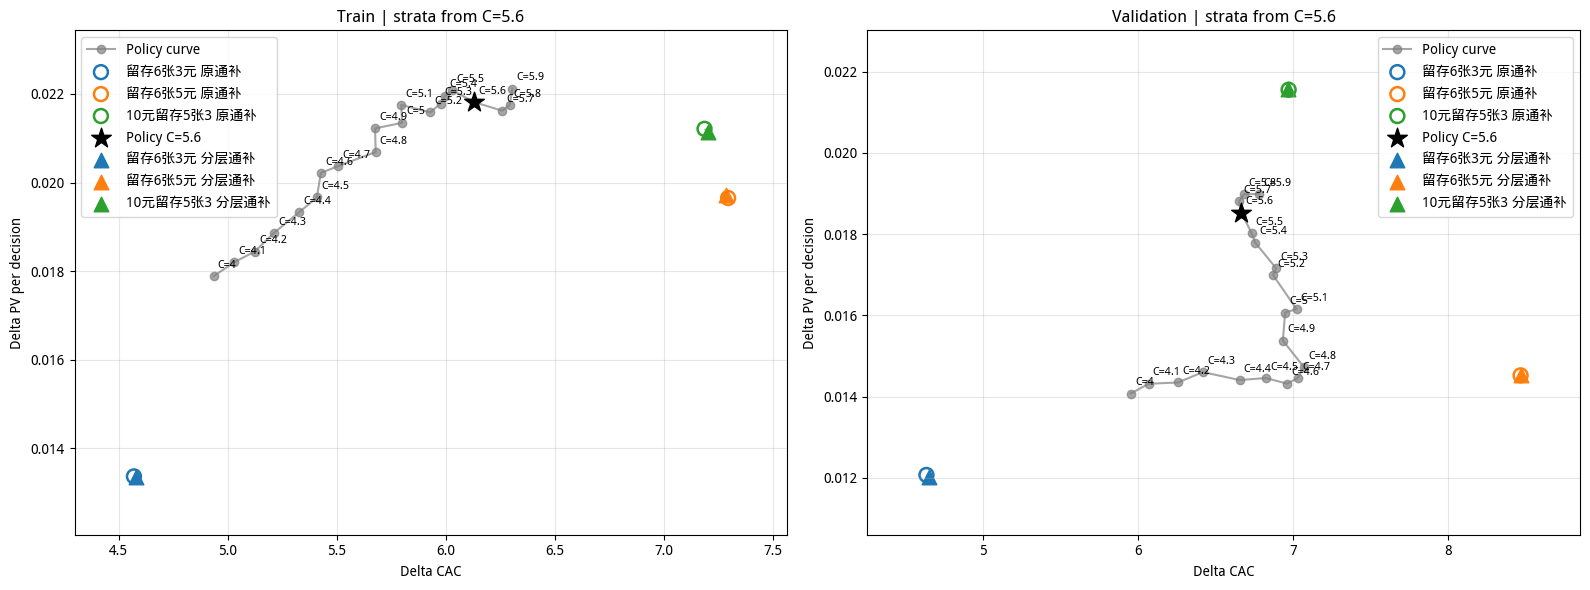

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161296,historical_rct_replay,810705.0,14498.476877,71556.803841,0.017884,4.935470,0,[],22022.637695,88089.414062,3.999948,-1.136719,True,True,0.422912,0.017884,False
1,4.1,0.155541,historical_rct_replay,810705.0,14755.167589,74215.822994,0.018200,5.029819,0,[],22374.344727,91734.771484,4.099998,-0.041895,True,True,0.417861,0.018200,False
2,4.2,0.150169,historical_rct_replay,810705.0,14950.357350,76608.353172,0.018441,5.124182,0,[],22718.932129,95419.871094,4.200016,0.356152,False,False,0.413079,0.018441,False
3,4.3,0.145144,historical_rct_replay,810705.0,15287.827745,79668.477237,0.018857,5.211236,0,[],23056.959473,99145.892578,4.300042,0.966846,False,False,0.408572,0.018857,False
4,4.4,0.139980,historical_rct_replay,810705.0,15667.770393,83464.889589,0.019326,5.327171,0,[],23388.127441,102908.830078,4.400046,1.069336,False,False,0.404238,0.019326,False
5,4.5,0.134057,historical_rct_replay,810705.0,15940.283012,86217.141301,0.019662,5.408759,0,[],23710.873535,106699.263672,4.500014,0.332764,False,False,0.399319,0.019662,False
6,4.6,0.126760,historical_rct_replay,810705.0,16389.282526,88950.616446,0.020216,5.427365,0,[],24022.397461,110503.306641,4.600012,0.278320,False,False,0.393655,0.020216,False
7,4.7,0.117773,historical_rct_replay,810705.0,16512.091533,90899.805730,0.020368,5.505045,0,[],24318.076416,114294.662109,4.699988,-0.297046,True,True,0.386684,0.020368,False
8,4.8,0.107608,historical_rct_replay,810705.0,16772.221551,95247.217095,0.020688,5.678867,0,[],24593.918457,118050.709961,4.799996,-0.098633,True,True,0.378552,0.020688,False
9,4.9,0.097175,historical_rct_replay,810705.0,17205.252957,97654.541960,0.021223,5.675856,0,[],24847.101562,121750.976562,4.900007,0.178906,False,False,0.369820,0.021223,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161296,historical_rct_replay,803803.0,11312.381583,67334.370680,0.014074,5.952272,0,[],22172.666504,88425.396484,3.988036,-265.269531,True,True,0.418982,0.014074,False
1,4.1,0.155541,historical_rct_replay,803803.0,11507.087595,69817.533058,0.014316,6.067350,0,[],22530.026367,92129.439453,4.089185,-243.668652,True,True,0.414067,0.014316,False
2,4.2,0.150169,historical_rct_replay,803803.0,11531.842072,72154.629711,0.014347,6.256991,0,[],22898.691406,96072.070312,4.195527,-102.433594,True,True,0.409430,0.014347,False
3,4.3,0.145144,historical_rct_replay,803803.0,11737.427720,75321.563128,0.014602,6.417212,0,[],23248.335449,99925.757812,4.298190,-42.084619,True,True,0.405184,0.014602,False
4,4.4,0.139980,historical_rct_replay,803803.0,11580.696450,77068.521570,0.014407,6.654913,0,[],23592.499023,103836.064453,4.401232,29.068750,False,False,0.400853,0.014407,False
5,4.5,0.134057,historical_rct_replay,803803.0,11619.526363,79302.781197,0.014456,6.824958,0,[],23925.548340,107746.943359,4.503426,81.975830,False,False,0.396056,0.014456,False
6,4.6,0.126760,historical_rct_replay,803803.0,11508.082081,80120.012432,0.014317,6.962065,0,[],24240.878418,111596.927734,4.603667,88.887012,False,False,0.390430,0.014317,False
7,4.7,0.117773,historical_rct_replay,803803.0,11623.001511,81727.790766,0.014460,7.031556,0,[],24535.460449,115373.244141,4.702306,56.580029,False,False,0.383226,0.014460,False
8,4.8,0.107608,historical_rct_replay,803803.0,11840.776337,83696.591247,0.014731,7.068505,0,[],24806.320801,119061.878906,4.799659,-8.460938,True,True,0.375206,0.014731,False
9,4.9,0.097175,historical_rct_replay,803803.0,12362.615371,85715.003878,0.015380,6.933404,0,[],25058.385498,122745.851562,4.898394,-40.237378,True,True,0.366550,0.015380,False


In [182]:
# V3: C=5.7, λ=0.02234797637
all_val_data_pdf_euen = all_rct_data_pdf_v3.copy()
prefix = 'msg_euen_uplift_cost_26_v3_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':b
        continue
    head = action_heads[action]
    all_val_data_pdf_euen['delta_cvr_' + action] = all_val_data_pdf_euen[prefix + f'uplift_{head}']
    all_val_data_pdf_euen['cost_' + action] = all_val_data_pdf_euen[prefix + f'cost_{head}']
all_val_data_pdf_euen['finish_cnt_7d'] = all_val_data_pdf_euen['pv_label_7d']
dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17','2026-08-18']
val_dt = ['2026-08-19', '2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25']

all_val_data_pdf_euen_use = all_val_data_pdf_euen[all_val_data_pdf_euen['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

In [183]:
# 填入你刚确定的新参数
initial_params_new = {
    "C": 5.7,
    "lambda": 0.02129862416,
}

bt_v3_new = backtest.run_backtest(
    raw=all_rct_data_pdf_v3,
    model_version="v3",
    start_dt="2026-09-02",
    end_dt="2026-09-08",
    initial_params=initial_params_new,
    cost_list=[i / 10 for i in range(40, 60)],
    train_days=7,
    val_days=7,
    maturity_lag=6,
    include_fixed_c_daily=True,
)

In [185]:
display(bt_v3_new["summary"])

,strategy,n,days,unsupported_dates,status,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cvr_pv_ratio,delta_cac,no_send_share,share_left_63,share_C,share_left_65,share_left_1053
0,rolling,698950,7,[],historical_rct_replay,9741.000543,73433.492534,0.013937,0.013937,7.538599,0.296646,0.074603,0.296646,0.252582,0.376169
1,fixed_initial,698950,7,[],historical_rct_replay,9639.176363,72966.835067,0.013791,0.013791,7.569821,0.298081,0.072200,0.298081,0.253874,0.375845
2,fixed_c_daily,698950,7,[],historical_rct_replay,9655.366253,72659.435822,0.013814,0.013814,7.525290,0.302180,0.080049,0.302180,0.252349,0.365422


求解日期: ['2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18'] 验证日期: ['2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25']
求解样本: 810705 验证样本: 803803
求解集 - C=4, λ=0.1580617122: delta_cac=4.8516, delta_pv_per_user=0.0173
验证集 - C=4, λ=0.1580617122: delta_cac=5.1276, delta_pv_per_user=0.0154
求解集 - C=4.1, λ=0.1545803309: delta_cac=4.9528, delta_pv_per_user=0.0178
验证集 - C=4.1, λ=0.1545803309: delta_cac=5.1477, delta_pv_per_user=0.0156
求解集 - C=4.2, λ=0.1516002536: delta_cac=5.0173, delta_pv_per_user=0.0181
验证集 - C=4.2, λ=0.1516002536: delta_cac=5.1997, delta_pv_per_user=0.0160
求解集 - C=4.3, λ=0.1489897507: delta_cac=5.1198, delta_pv_per_user=0.0185
验证集 - C=4.3, λ=0.1489897507: delta_cac=5.2822, delta_pv_per_user=0.0163
求解集 - C=4.4, λ=0.146634301: delta_cac=5.2843, delta_pv_per_user=0.0185
验证集 - C=4.4, λ=0.146634301: delta_cac=5.3103, delta_pv_per_user=0.0169
求解集 - C=4.5, λ=0.144563601: delta_cac=5.4238, delt

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121722,left_63,留存6张3元,True,10617.932815,49368.084868,0.013097,4.649501
1,5.6,0.121722,left_65,留存6张5元,True,15615.565957,115341.396620,0.019262,7.386309
2,5.6,0.121722,left_1053,10元留存5张3,True,16989.041519,123646.494366,0.020956,7.278015


Validation分层通补：C=5.6，λ=0.1217217676


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121722,left_63,留存6张3元,True,9451.583613,44717.240424,0.011759,4.731190
1,5.6,0.121722,left_65,留存6张5元,True,11315.603275,97748.247830,0.014078,8.638359
2,5.6,0.121722,left_1053,10元留存5张3,True,17044.869080,120120.178192,0.021205,7.047293


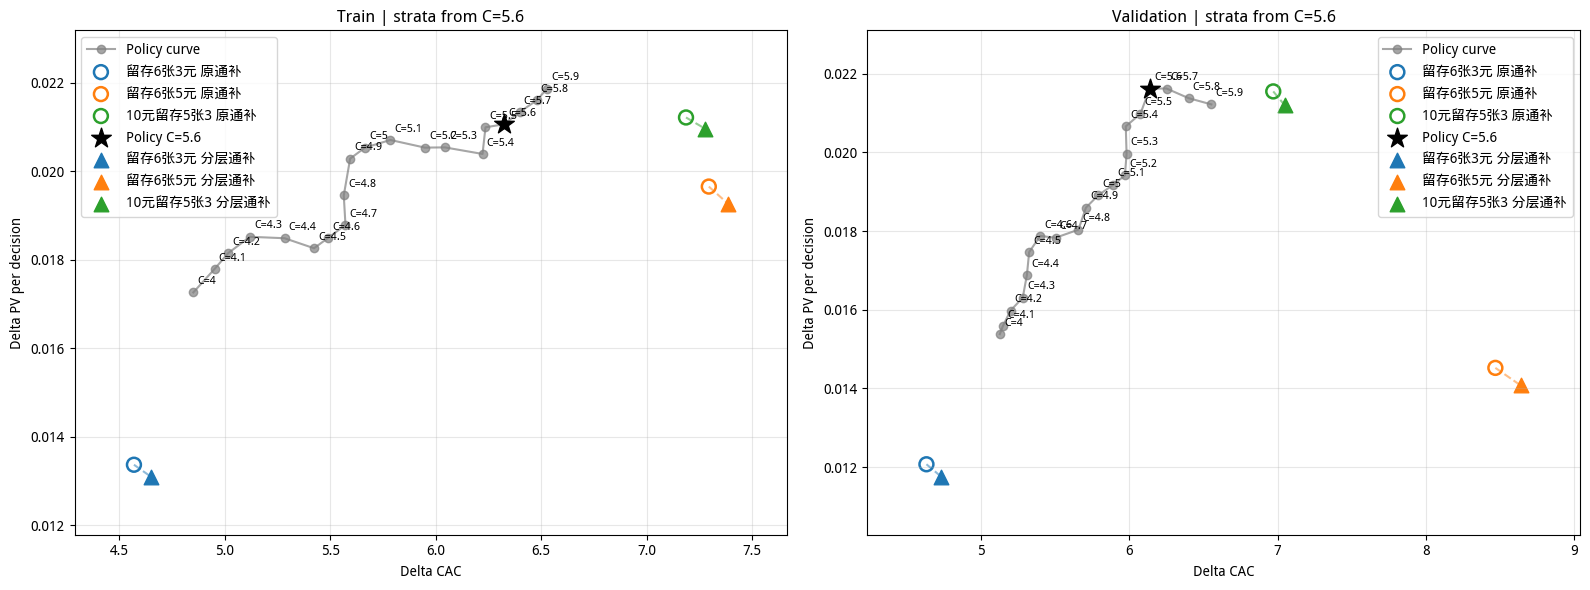

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158062,historical_rct_replay,810705.0,13990.880904,67877.827077,0.017258,4.851576,0,[],17317.708130,69269.889160,3.999946,-0.943359,True,True,0.138286,0.017258,False
1,4.1,0.154580,historical_rct_replay,810705.0,14422.948166,71434.359556,0.017791,4.952826,0,[],17590.871094,72124.210938,4.100093,1.639453,False,False,0.137269,0.017791,False
2,4.2,0.151600,historical_rct_replay,810705.0,14711.992742,73814.174795,0.018147,5.017279,0,[],17861.850830,75019.259766,4.199971,-0.513721,True,True,0.136346,0.018147,False
3,4.3,0.148990,historical_rct_replay,810705.0,15010.493264,76850.701944,0.018515,5.119799,0,[],18132.268311,77968.310547,4.299976,-0.443188,True,True,0.135523,0.018515,False
4,4.4,0.146634,historical_rct_replay,810705.0,14984.015002,79179.305971,0.018483,5.284252,0,[],18402.455566,80971.785156,4.400053,0.980664,False,False,0.134699,0.018483,False
5,4.5,0.144564,historical_rct_replay,810705.0,14800.682966,80275.615322,0.018257,5.423778,0,[],18672.245605,84025.798828,4.500037,0.693604,False,False,0.133998,0.018257,False
6,4.6,0.142723,historical_rct_replay,810705.0,14990.975110,82315.257524,0.018491,5.490988,0,[],18942.333496,87135.398438,4.600035,0.664355,False,False,0.133314,0.018491,False
7,4.7,0.141138,historical_rct_replay,810705.0,15229.068930,84867.799795,0.018785,5.572750,0,[],19213.053223,90301.716797,4.700019,0.366650,False,False,0.132705,0.018785,False
8,4.8,0.139635,historical_rct_replay,810705.0,15769.011430,87750.554210,0.019451,5.564747,0,[],19484.476318,93524.672852,4.799958,-0.813477,True,True,0.132157,0.019451,False
9,4.9,0.138202,historical_rct_replay,810705.0,16442.911199,91997.340589,0.020282,5.594955,0,[],19757.069824,96809.027344,4.899969,-0.614795,True,True,0.131634,0.020282,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158062,historical_rct_replay,803803.0,12362.927168,63391.883624,0.015381,5.127579,0,[],16946.788940,67929.426758,4.008395,142.270996,False,False,0.139167,0.015381,False
1,4.1,0.154580,historical_rct_replay,803803.0,12524.214858,64471.515704,0.015581,5.147749,0,[],17226.725220,70854.622070,4.113064,225.048669,False,False,0.138069,0.015581,False
2,4.2,0.151600,historical_rct_replay,803803.0,12843.832345,66783.601486,0.015979,5.199663,0,[],17494.685303,73717.061523,4.213683,239.383252,False,False,0.137090,0.015979,False
3,4.3,0.148990,historical_rct_replay,803803.0,13107.376979,69235.205910,0.016307,5.282156,0,[],17762.727783,76640.360352,4.314673,260.630884,False,False,0.136276,0.016307,False
4,4.4,0.146634,historical_rct_replay,803803.0,13573.024852,72076.467843,0.016886,5.310273,0,[],18031.519043,79628.280273,4.416061,289.596484,False,False,0.135517,0.016886,False
5,4.5,0.144564,historical_rct_replay,803803.0,14037.387970,74753.519574,0.017464,5.325315,0,[],18307.589111,82752.820312,4.520138,368.669312,False,False,0.134817,0.017464,False
6,4.6,0.142723,historical_rct_replay,803803.0,14369.827029,77587.223503,0.017877,5.399315,0,[],18579.299072,85880.983398,4.622402,416.207666,False,False,0.134197,0.017877,False
7,4.7,0.141138,historical_rct_replay,803803.0,14332.860429,78881.484902,0.017831,5.503541,0,[],18843.979004,88976.697266,4.721757,409.995947,False,False,0.133590,0.017831,False
8,4.8,0.139635,historical_rct_replay,803803.0,14497.322728,82017.921511,0.018036,5.657453,0,[],19120.052002,92254.335938,4.825004,478.086328,False,False,0.133050,0.018036,False
9,4.9,0.138202,historical_rct_replay,803803.0,14948.587461,85330.922564,0.018597,5.708293,0,[],19392.813477,95540.869141,4.926612,516.083105,False,False,0.132534,0.018597,False


In [186]:
# C=5.5, λ=0.1239815851

all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17','2026-08-18']
val_dt = ['2026-08-19', '2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25']

all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

In [ ]:
"3":{"delta_cvr":0.08941344916820526,"cost":0.5313838124275208}

In [211]:
delta_cvr = 0.08941344916820526

In [212]:
cost = 0.5313838124275208

In [213]:
delta_cvr+0.1239815851*(5.5*delta_cvr-cost)

0.08450255817118817

In [188]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest.opt)
importlib.reload(backtest)

# 1. 验证日期与两组固定参数
eval_dates = pd.date_range(
    "2026-09-02", "2026-09-08"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.7, "lambda": 0.02234797637},
    "B": {"C": 5.7, "lambda": 0.02129862416},
}

# 2. 仅复用字段适配函数，不训练、不求解。
# 两个日期参数都传验证期，只取其中一个适配结果。
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v3,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v3_final_",
)

# 3. 两组固定参数分别在同一批每日用户上回放
rows = []

for name, params in params_by_name.items():
    for day, day_df in eval_df.groupby("dt"):
        metrics = backtest.opt.replay(day_df, params)

        row = {
            "strategy": name,
            "effective_dt": day,
            **params,
        }
        for key in [
            "n", "status", "delta_finish_pv_total", "delta_cost",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]:
            row[key] = metrics[key]

        row.update({
            "share_" + action: share
            for action, share in metrics["action_share"].items()
        })
        rows.append(row)

fixed_daily = pd.DataFrame(rows)

# 4. 汇总整周结果，并附上对应参数
fixed_summary = backtest.summarize_daily(fixed_daily)

parameter_table = pd.DataFrame([
    {"strategy": name, **params}
    for name, params in params_by_name.items()
])
fixed_summary = fixed_summary.merge(parameter_table, on="strategy")

with pd.option_context("display.precision", 12):
    display(fixed_summary[
        [
            "strategy", "C", "lambda", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]
    ])

    display(fixed_daily.pivot(
        index="effective_dt",
        columns="strategy",
        values=["delta_cvr_pv_ratio", "delta_cac", "no_send_share"],
    ))

,strategy,C,lambda,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share
0,A,5.7,0.02234797637,698950,7,historical_rct_replay,0.013831166262,7.540942593235,0.299635167036
1,B,5.7,0.02129862416,698950,7,historical_rct_replay,0.013790938355,7.569820523971,0.298081407826


delta_cvr_pv_ratio                       delta_cac  \
strategy                      A               B               A   
effective_dt                                                      
2026-09-02       0.019337404127  0.019320969121  6.637383653813   
2026-09-03       0.009838915577  0.009844598864  9.146302071186   
2026-09-04       0.012894559329  0.012472318990  7.975465220839   
2026-09-05       0.014646050145  0.014879960952  6.910202443702   
2026-09-06       0.009679561003  0.009665974550  9.633204718322   
2026-09-07       0.014367361195  0.014316022538  7.512719557831   
2026-09-08       0.016878110516  0.016855688914  6.487490061087   

                               no_send_share                  
strategy                   B               A               B  
effective_dt                                                  
2026-09-02    6.645198693142  0.316167525310  0.314464344275  
2026-09-03    9.139065138006  0.316675922761  0.315095266576  
2026-09-04    8.222575492910  0.299093825105  0.297373121487  
2026-09-05    6.858163693717  0.274067402103  0.272595935184  
2026-09-06    9.647698220372  0.277233247829  0.275937176545  
2026-09-07    7.538781150019  0.308817998805  0.307258367807  
2026-09-08    6.496381311624  0.315434753691  0.313849598723

In [198]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest.opt)
importlib.reload(backtest)

# 1. 验证日期与两组固定参数
eval_dates = pd.date_range(
    "2026-09-07", "2026-09-13"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.7, "lambda": 0.02234797637},
    "B": {"C": 5.7, "lambda": 0.02129862416},
}

# 2. 仅复用字段适配函数，不训练、不求解。
# 两个日期参数都传验证期，只取其中一个适配结果。
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v3,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v3_final_",
)

# 3. 两组固定参数分别在同一批每日用户上回放
rows = []

for name, params in params_by_name.items():
    for day, day_df in eval_df.groupby("dt"):
        metrics = backtest.opt.replay(day_df, params)

        row = {
            "strategy": name,
            "effective_dt": day,
            **params,
        }
        for key in [
            "n", "status", "delta_finish_pv_total", "delta_cost",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]:
            row[key] = metrics[key]

        row.update({
            "share_" + action: share
            for action, share in metrics["action_share"].items()
        })
        rows.append(row)

fixed_daily = pd.DataFrame(rows)

# 4. 汇总整周结果，并附上对应参数
fixed_summary = backtest.summarize_daily(fixed_daily)

parameter_table = pd.DataFrame([
    {"strategy": name, **params}
    for name, params in params_by_name.items()
])
fixed_summary = fixed_summary.merge(parameter_table, on="strategy")

with pd.option_context("display.precision", 12):
    display(fixed_summary[
        [
            "strategy", "C", "lambda", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]
    ])

    display(fixed_daily.pivot(
        index="effective_dt",
        columns="strategy",
        values=["delta_cvr_pv_ratio", "delta_cac", "no_send_share"],
    ))

,strategy,C,lambda,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share
0,A,5.7,0.02234797637,701728,7,historical_rct_replay,0.009180931746,9.571851558636,0.292650428656
1,B,5.7,0.02129862416,701728,7,historical_rct_replay,0.009183346329,9.578443484655,0.291119921109


delta_cvr_pv_ratio                        delta_cac  \
strategy                      A               B                A   
effective_dt                                                       
2026-09-07       0.014367361195  0.014316022538   7.512719557831   
2026-09-08       0.016878110516  0.016855688914   6.487490061087   
2026-09-09       0.007826788671  0.007818821592  12.652814283637   
2026-09-10       0.013866591744  0.013901924655   7.598800005688   
2026-09-11       0.003952068150  0.003954569209  19.096374840221   
2026-09-12       0.007259733508  0.007252600137  10.956720917323   
2026-09-13       0.003160518910  0.003216264186  16.440564213411   

                                no_send_share                  
strategy                    B               A               B  
effective_dt                                                   
2026-09-07     7.538781150019  0.308817998805  0.307258367807  
2026-09-08     6.496381311624  0.315434753691  0.313849598723  
2026-09-09    12.660160367023  0.311851584621  0.310146163349  
2026-09-10     7.589850665864  0.315020651774  0.313398784681  
2026-09-11    19.078279503672  0.285212018887  0.283866897966  
2026-09-12    10.963439780709  0.263076481885  0.261581778523  
2026-09-13    16.308058252479  0.265197189384  0.263735879105

##### 发券占比

In [194]:
all_rct_data_pdf_v3['dt'].max()

'2026-09-13'

In [195]:
import pandas as pd

eval_dates = pd.date_range(
    "2026-09-07", "2026-09-13"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.7, "lambda": 0.02234797637},
    "B": {"C": 5.7, "lambda": 0.02129862416},
}


# 这里只复用数据适配，不进行训练或选参
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v3,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v3_final_",
)

rows = []
for strategy, params in params_by_name.items():
    selected = backtest.opt.intervention_scores(
        eval_df,
        lambda_val=params["lambda"],
        cost=params["C"],
    ).idxmax(axis=1)

    counts = selected.value_counts().reindex(
        backtest.opt.ACTION_LIST, fill_value=0
    )

    for action, count in counts.items():
        rows.append({
            "strategy": strategy,
            "C": params["C"],
            "lambda": params["lambda"],
            "动作": backtest.opt.DICT_COUPON[action],
            "样本数": int(count),
            "验证期总样本数": len(eval_df),
            "占比": count / len(eval_df),
        })

coupon_share = pd.DataFrame(rows)

# 人数及占比明细
display(coupon_share.style.format({
    "lambda": "{:.11f}",
    "占比": "{:.4%}",
}))

# 两组参数的券占比并排比较
display(
    coupon_share.pivot(
        index="动作", columns="strategy", values="占比"
    ).style.format("{:.4%}")
)

,strategy,C,lambda,动作,样本数,验证期总样本数,占比
0,A,5.700000,0.02234797637,留存6张3元,53673,701728,7.6487%
1,A,5.700000,0.02234797637,DS空白,205361,701728,29.2650%
2,A,5.700000,0.02234797637,留存6张5元,182169,701728,25.9601%
3,A,5.700000,0.02234797637,10元留存5张3,260525,701728,37.1262%
4,B,5.700000,0.02129862416,留存6张3元,51652,701728,7.3607%
5,B,5.700000,0.02129862416,DS空白,204287,701728,29.1120%
6,B,5.700000,0.02129862416,留存6张5元,182528,701728,26.0112%
7,B,5.700000,0.02129862416,10元留存5张3,263261,701728,37.5161%


strategy,A,B
动作,,
10元留存5张3,37.1262%,37.5161%
DS空白,29.2650%,29.1120%
留存6张3元,7.6487%,7.3607%
留存6张5元,25.9601%,26.0112%


In [189]:
import pandas as pd

eval_dates = pd.date_range(
    "2026-09-02", "2026-09-08"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.7, "lambda": 0.02234797637},
    "B": {"C": 5.7, "lambda": 0.02129862416},
}


# 这里只复用数据适配，不进行训练或选参
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v3,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v3_final_",
)

rows = []
for strategy, params in params_by_name.items():
    selected = backtest.opt.intervention_scores(
        eval_df,
        lambda_val=params["lambda"],
        cost=params["C"],
    ).idxmax(axis=1)

    counts = selected.value_counts().reindex(
        backtest.opt.ACTION_LIST, fill_value=0
    )

    for action, count in counts.items():
        rows.append({
            "strategy": strategy,
            "C": params["C"],
            "lambda": params["lambda"],
            "动作": backtest.opt.DICT_COUPON[action],
            "样本数": int(count),
            "验证期总样本数": len(eval_df),
            "占比": count / len(eval_df),
        })

coupon_share = pd.DataFrame(rows)

# 人数及占比明细
display(coupon_share.style.format({
    "lambda": "{:.11f}",
    "占比": "{:.4%}",
}))

# 两组参数的券占比并排比较
display(
    coupon_share.pivot(
        index="动作", columns="strategy", values="占比"
    ).style.format("{:.4%}")
)

,strategy,C,lambda,动作,样本数,验证期总样本数,占比
0,A,5.700000,0.02234797637,留存6张3元,52438,698950,7.5024%
1,A,5.700000,0.02234797637,DS空白,209430,698950,29.9635%
2,A,5.700000,0.02234797637,留存6张5元,177049,698950,25.3307%
3,A,5.700000,0.02234797637,10元留存5张3,260033,698950,37.2034%
4,B,5.700000,0.02129862416,留存6张3元,50464,698950,7.2200%
5,B,5.700000,0.02129862416,DS空白,208344,698950,29.8081%
6,B,5.700000,0.02129862416,留存6张5元,177445,698950,25.3874%
7,B,5.700000,0.02129862416,10元留存5张3,262697,698950,37.5845%


strategy,A,B
动作,,
10元留存5张3,37.2034%,37.5845%
DS空白,29.9635%,29.8081%
留存6张3元,7.5024%,7.2200%
留存6张5元,25.3307%,25.3874%


In [187]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest.opt)
importlib.reload(backtest)

# 1. 验证日期与两组固定参数
eval_dates = pd.date_range(
    "2026-09-02", "2026-09-08"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.5, "lambda": 0.1239815851},
    "B": {"C": 5.5, "lambda": 0.1242497254},
}

# 2. 仅复用字段适配函数，不训练、不求解。
# 两个日期参数都传验证期，只取其中一个适配结果。
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v4,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v4_final_",
)

# 3. 两组固定参数分别在同一批每日用户上回放
rows = []

for name, params in params_by_name.items():
    for day, day_df in eval_df.groupby("dt"):
        metrics = backtest.opt.replay(day_df, params)

        row = {
            "strategy": name,
            "effective_dt": day,
            **params,
        }
        for key in [
            "n", "status", "delta_finish_pv_total", "delta_cost",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]:
            row[key] = metrics[key]

        row.update({
            "share_" + action: share
            for action, share in metrics["action_share"].items()
        })
        rows.append(row)

fixed_daily = pd.DataFrame(rows)

# 4. 汇总整周结果，并附上对应参数
fixed_summary = backtest.summarize_daily(fixed_daily)

parameter_table = pd.DataFrame([
    {"strategy": name, **params}
    for name, params in params_by_name.items()
])
fixed_summary = fixed_summary.merge(parameter_table, on="strategy")

with pd.option_context("display.precision", 12):
    display(fixed_summary[
        [
            "strategy", "C", "lambda", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]
    ])

    display(fixed_daily.pivot(
        index="effective_dt",
        columns="strategy",
        values=["delta_cvr_pv_ratio", "delta_cac", "no_send_share"],
    ))

,strategy,C,lambda,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share
0,A,5.5,0.1239815851,698950,7,historical_rct_replay,0.014841996594,6.914830675894,0.149627298090
1,B,5.5,0.1242497254,698950,7,historical_rct_replay,0.014879729996,6.898984393359,0.149668788898


delta_cvr_pv_ratio                        delta_cac  \
strategy                      A               B                A   
effective_dt                                                       
2026-09-02       0.017235594577  0.017165499913   6.546024839832   
2026-09-03       0.008209374978  0.008220202340  10.748369526210   
2026-09-04       0.014008675136  0.014021133490   7.017747511397   
2026-09-05       0.018307161688  0.018585818176   6.286371703463   
2026-09-06       0.012065378931  0.012063438748   7.666904445532   
2026-09-07       0.018239093231  0.018316060018   5.977569033430   
2026-09-08       0.015913800750  0.015832486283   6.446354668918   

                                no_send_share                  
strategy                    B               A               B  
effective_dt                                                   
2026-09-02     6.546995061617  0.164415153022  0.164457468079  
2026-09-03    10.737825701400  0.159496753247  0.159528793575  
2026-09-04     7.014933365233  0.151178775495  0.151206830445  
2026-09-05     6.223450477484  0.136998029126  0.137060454995  
2026-09-06     7.666856298492  0.138166599163  0.138211601638  
2026-09-07     5.953048642596  0.149182576378  0.149215760016  
2026-09-08     6.470281197483  0.152307896954  0.152352236953

In [197]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest.opt)
importlib.reload(backtest)

# 1. 验证日期与两组固定参数
eval_dates = pd.date_range(
    "2026-09-07", "2026-09-13"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.5, "lambda": 0.1239815851},
    "B": {"C": 5.5, "lambda": 0.1242497254},
}

# 2. 仅复用字段适配函数，不训练、不求解。
# 两个日期参数都传验证期，只取其中一个适配结果。
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v4,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v4_final_",
)

# 3. 两组固定参数分别在同一批每日用户上回放
rows = []

for name, params in params_by_name.items():
    for day, day_df in eval_df.groupby("dt"):
        metrics = backtest.opt.replay(day_df, params)

        row = {
            "strategy": name,
            "effective_dt": day,
            **params,
        }
        for key in [
            "n", "status", "delta_finish_pv_total", "delta_cost",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]:
            row[key] = metrics[key]

        row.update({
            "share_" + action: share
            for action, share in metrics["action_share"].items()
        })
        rows.append(row)

fixed_daily = pd.DataFrame(rows)

# 4. 汇总整周结果，并附上对应参数
fixed_summary = backtest.summarize_daily(fixed_daily)

parameter_table = pd.DataFrame([
    {"strategy": name, **params}
    for name, params in params_by_name.items()
])
fixed_summary = fixed_summary.merge(parameter_table, on="strategy")

with pd.option_context("display.precision", 12):
    display(fixed_summary[
        [
            "strategy", "C", "lambda", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]
    ])

    display(fixed_daily.pivot(
        index="effective_dt",
        columns="strategy",
        values=["delta_cvr_pv_ratio", "delta_cac", "no_send_share"],
    ))

,strategy,C,lambda,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share
0,A,5.5,0.1239815851,701728,7,historical_rct_replay,0.009147971812,8.881222354798,0.155335115600
1,B,5.5,0.1242497254,701728,7,historical_rct_replay,0.009082684596,8.901815833044,0.155363616672


delta_cvr_pv_ratio                        delta_cac  \
strategy                      A               B                A   
effective_dt                                                       
2026-09-07       0.018239093231  0.018316060018   5.977569033430   
2026-09-08       0.015913800750  0.015832486283   6.446354668918   
2026-09-09       0.010991123598  0.011020167436   8.502298401888   
2026-09-10       0.010869828390  0.010364960162   8.134142615445   
2026-09-11       0.003591917989  0.003633435641  18.553830771115   
2026-09-12       0.004495289012  0.004424629326  14.364127772891   
2026-09-13       0.003672231909  0.003691968111  15.634208535668   

                                no_send_share                  
strategy                    B               A               B  
effective_dt                                                   
2026-09-07     5.953048642596  0.149182576378  0.149215760016  
2026-09-08     6.470281197483  0.152307896954  0.152352236953  
2026-09-09     8.491950252042  0.168454079346  0.168465011533  
2026-09-10     8.287948206405  0.168544428346  0.168555240793  
2026-09-11    18.373379309377  0.158761375548  0.158779928941  
2026-09-12    14.478676554754  0.145290380889  0.145325141432  
2026-09-13    15.557314341367  0.148283616699  0.148327368504

##### 发券占比

In [ ]:
求解集 - C=4.8, λ=0.1396348768: delta_cac=5.5647, delta_pv_per_user=0.0195
验证集 - C=4.8, λ=0.1396348768: delta_cac=5.6575, delta_pv_per_user=0.0180
求解集 - C=4.9, λ=0.1382020926: delta_cac=5.5950, delta_pv_per_user=0.0203
验证集 - C=4.9, λ=0.1382020926: delta_cac=5.7083, delta_pv_per_user=0.0186
求解集 - C=5, λ=0.1366723316: delta_cac=5.6650, delta_pv_per_user=0.0205
验证集 - C=5, λ=0.1366723316: delta_cac=5.7897, delta_pv_per_user=0.0189
求解集 - C=5.1, λ=0.1350204524: delta_cac=5.7857, delta_pv_per_user=0.0207
验证集 - C=5.1, λ=0.1350204524: delta_cac=5.8935, delta_pv_per_user=0.0192
求解集 - C=5.2, λ=0.1330205804: delta_cac=5.9491, delta_pv_per_user=0.0205
验证集 - C=5.2, λ=0.1330205804: delta_cac=5.9710, delta_pv_per_user=0.0194
求解集 - C=5.3, λ=0.1304353911: delta_cac=6.0437, delta_pv_per_user=0.0205
验证集 - C=5.3, λ=0.1304353911: delta_cac=5.9821, delta_pv_per_user=0.0200
求解集 - C=5.4, λ=0.1273690869: delta_cac=6.2224, delta_pv_per_user=0.0204
验证集 - C=5.4, λ=0.1273690869: delta_cac=5.9767, delta_pv_per_user=0.0207
求解集 - C=5.5, λ=0.1242497254: delta_cac=6.2364, delta_pv_per_user=0.0210
验证集 - C=5.5, λ=0.1242497254: delta_cac=6.0753, delta_pv_per_user=0.0210
求解集 - C=5.6, λ=0.1217217676: delta_cac=6.3230, delta_pv_per_user=0.0211
验证集 - C=5.6, λ=0.1217217676: delta_cac=6.1388, delta_pv_per_user=0.0216
求解集 - C=5.7, λ=0.1196663024: delta_cac=6.3981, delta_pv_per_user=0.0213
验证集 - C=5.7, λ=0.1196663024: delta_cac=6.2516, delta_pv_per_user=0.0216
求解集 - C=5.8, λ=0.1171593289: delta_cac=6.4791, delta_pv_per_user=0.0216

In [ ]:
求解集 - C=4, λ=0.1580617122: delta_cac=4.8516, delta_pv_per_user=0.0173
验证集 - C=4, λ=0.1580617122: delta_cac=5.1276, delta_pv_per_user=0.0154
求解集 - C=4.1, λ=0.1545803309: delta_cac=4.9528, delta_pv_per_user=0.0178
验证集 - C=4.1, λ=0.1545803309: delta_cac=5.1477, delta_pv_per_user=0.0156
求解集 - C=4.2, λ=0.1516002536: delta_cac=5.0173, delta_pv_per_user=0.0181
验证集 - C=4.2, λ=0.1516002536: delta_cac=5.1997, delta_pv_per_user=0.0160
求解集 - C=4.3, λ=0.1489897507: delta_cac=5.1198, delta_pv_per_user=0.0185
验证集 - C=4.3, λ=0.1489897507: delta_cac=5.2822, delta_pv_per_user=0.0163
求解集 - C=4.4, λ=0.146634301: delta_cac=5.2843, delta_pv_per_user=0.0185
验证集 - C=4.4, λ=0.146634301: delta_cac=5.3103, delta_pv_per_user=0.0169
求解集 - C=4.5, λ=0.144563601: delta_cac=5.4238, delta_pv_per_user=0.0183
验证集 - C=4.5, λ=0.144563601: delta_cac=5.3253, delta_pv_per_user=0.0175
求解集 - C=4.6, λ=0.1427230363: delta_cac=5.4910, delta_pv_per_user=0.0185
验证集 - C=4.6, λ=0.1427230363: delta_cac=5.3993, delta_pv_per_user=0.0179
求解集 - C=4.7, λ=0.141137869: delta_cac=5.5728, delta_pv_per_user=0.0188
验证集 - C=4.7, λ=0.141137869: delta_cac=5.5035, delta_pv_per_user=0.0178
求解集 - C=4.8, λ=0.1396348768: delta_cac=5.5647, delta_pv_per_user=0.0195
验证集 - C=4.8, λ=0.1396348768: delta_cac=5.6575, delta_pv_per_user=0.0180
求解集 - C=4.9, λ=0.1382020926: delta_cac=5.5950, delta_pv_per_user=0.0203
验证集 - C=4.9, λ=0.1382020926: delta_cac=5.7083, delta_pv_per_user=0.0186
求解集 - C=5, λ=0.1366723316: delta_cac=5.6650, delta_pv_per_user=0.0205
验证集 - C=5, λ=0.1366723316: delta_cac=5.7897, delta_pv_per_user=0.0189
求解集 - C=5.1, λ=0.1350204524: delta_cac=5.7857, delta_pv_per_user=0.0207
验证集 - C=5.1, λ=0.1350204524: delta_cac=5.8935, delta_pv_per_user=0.0192
求解集 - C=5.2, λ=0.1330205804: delta_cac=5.9491, delta_pv_per_user=0.0205
验证集 - C=5.2, λ=0.1330205804: delta_cac=5.9710, delta_pv_per_user=0.0194
求解集 - C=5.3, λ=0.1304353911: delta_cac=6.0437, delta_pv_per_user=0.0205
验证集 - C=5.3, λ=0.1304353911: delta_cac=5.9821, delta_pv_per_user=0.0200

In [202]:
import pandas as pd

eval_dates = pd.date_range(
    "2026-09-02", "2026-09-08"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.4, "lambda": 0.1273690869},
    "B": {"C": 5.5, "lambda": 0.1242497254},
    "C": {"C": 5.6, "lambda": 0.1217217676},
    "D": {"C": 4.2, "lambda": 0.1516002536},
    "E": {"C": 4, "lambda": 0.1580617122},
    "F": {"C": 4.8, "lambda": 0.1396348768},
}


# 这里只复用数据适配，不进行训练或选参
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v4,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v4_final_",
)

rows = []
for strategy, params in params_by_name.items():
    selected = backtest.opt.intervention_scores(
        eval_df,
        lambda_val=params["lambda"],
        cost=params["C"],
    ).idxmax(axis=1)

    counts = selected.value_counts().reindex(
        backtest.opt.ACTION_LIST, fill_value=0
    )

    for action, count in counts.items():
        rows.append({
            "strategy": strategy,
            "C": params["C"],
            "lambda": params["lambda"],
            "动作": backtest.opt.DICT_COUPON[action],
            "样本数": int(count),
            "验证期总样本数": len(eval_df),
            "占比": count / len(eval_df),
        })

coupon_share = pd.DataFrame(rows)

# 人数及占比明细
display(coupon_share.style.format({
    "lambda": "{:.11f}",
    "占比": "{:.4%}",
}))

# 两组参数的券占比并排比较
display(
    coupon_share.pivot(
        index="动作", columns="strategy", values="占比"
    ).style.format("{:.4%}")
)

,strategy,C,lambda,动作,样本数,验证期总样本数,占比
0,A,5.400000,0.12736908690,留存6张3元,29346,698950,4.1986%
1,A,5.400000,0.12736908690,DS空白,105088,698950,15.0351%
2,A,5.400000,0.12736908690,留存6张5元,35362,698950,5.0593%
3,A,5.400000,0.12736908690,10元留存5张3,529154,698950,75.7070%
4,B,5.500000,0.12424972540,留存6张3元,22292,698950,3.1894%
5,B,5.500000,0.12424972540,DS空白,104611,698950,14.9669%
6,B,5.500000,0.12424972540,留存6张5元,36540,698950,5.2278%
7,B,5.500000,0.12424972540,10元留存5张3,535507,698950,76.6159%
8,C,5.600000,0.12172176760,留存6张3元,16360,698950,2.3407%
9,C,5.600000,0.12172176760,DS空白,104167,698950,14.9034%


strategy,A,B,C,D,E,F
动作,,,,,,
10元留存5张3,75.7070%,76.6159%,77.2374%,58.8290%,55.7196%,67.9289%
DS空白,15.0351%,14.9669%,14.9034%,15.8649%,16.0805%,15.4083%
留存6张3元,4.1986%,3.1894%,2.3407%,20.9584%,24.0325%,11.9418%
留存6张5元,5.0593%,5.2278%,5.5186%,4.3477%,4.1674%,4.7211%


In [196]:
import pandas as pd

eval_dates = pd.date_range(
    "2026-09-07", "2026-09-13"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.5, "lambda": 0.1239815851},
    "B": {"C": 5.5, "lambda": 0.1242497254},
}


# 这里只复用数据适配，不进行训练或选参
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v4,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v4_final_",
)

rows = []
for strategy, params in params_by_name.items():
    selected = backtest.opt.intervention_scores(
        eval_df,
        lambda_val=params["lambda"],
        cost=params["C"],
    ).idxmax(axis=1)

    counts = selected.value_counts().reindex(
        backtest.opt.ACTION_LIST, fill_value=0
    )

    for action, count in counts.items():
        rows.append({
            "strategy": strategy,
            "C": params["C"],
            "lambda": params["lambda"],
            "动作": backtest.opt.DICT_COUPON[action],
            "样本数": int(count),
            "验证期总样本数": len(eval_df),
            "占比": count / len(eval_df),
        })

coupon_share = pd.DataFrame(rows)

# 人数及占比明细
display(coupon_share.style.format({
    "lambda": "{:.11f}",
    "占比": "{:.4%}",
}))

# 两组参数的券占比并排比较
display(
    coupon_share.pivot(
        index="动作", columns="strategy", values="占比"
    ).style.format("{:.4%}")
)

,strategy,C,lambda,动作,样本数,验证期总样本数,占比
0,A,5.500000,0.12398158510,留存6张3元,22187,701728,3.1618%
1,A,5.500000,0.12398158510,DS空白,109003,701728,15.5335%
2,A,5.500000,0.12398158510,留存6张5元,35864,701728,5.1108%
3,A,5.500000,0.12398158510,10元留存5张3,534674,701728,76.1939%
4,B,5.500000,0.12424972540,留存6张3元,22562,701728,3.2152%
5,B,5.500000,0.12424972540,DS空白,109023,701728,15.5364%
6,B,5.500000,0.12424972540,留存6张5元,35771,701728,5.0976%
7,B,5.500000,0.12424972540,10元留存5张3,534372,701728,76.1509%


strategy,A,B
动作,,
10元留存5张3,76.1939%,76.1509%
DS空白,15.5335%,15.5364%
留存6张3元,3.1618%,3.2152%
留存6张5元,5.1108%,5.0976%


In [ ]:
import pandas as pd

eval_dates = pd.date_range(
    "2026-09-02", "2026-09-08"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.5, "lambda": 0.1239815851},
    "B": {"C": 5.5, "lambda": 0.1242497254},
}


# 这里只复用数据适配，不进行训练或选参
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v4,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v4_final_",
)

rows = []
for strategy, params in params_by_name.items():
    selected = backtest.opt.intervention_scores(
        eval_df,
        lambda_val=params["lambda"],
        cost=params["C"],
    ).idxmax(axis=1)

    counts = selected.value_counts().reindex(
        backtest.opt.ACTION_LIST, fill_value=0
    )

    for action, count in counts.items():
        rows.append({
            "strategy": strategy,
            "C": params["C"],
            "lambda": params["lambda"],
            "动作": backtest.opt.DICT_COUPON[action],
            "样本数": int(count),
            "验证期总样本数": len(eval_df),
            "占比": count / len(eval_df),
        })

coupon_share = pd.DataFrame(rows)

# 人数及占比明细
display(coupon_share.style.format({
    "lambda": "{:.11f}",
    "占比": "{:.4%}",
}))

# 两组参数的券占比并排比较
display(
    coupon_share.pivot(
        index="动作", columns="strategy", values="占比"
    ).style.format("{:.4%}")
)

In [190]:
import pandas as pd

eval_dates = pd.date_range(
    "2026-09-02", "2026-09-08"
).strftime("%Y-%m-%d").tolist()

params_by_name = {
    "A": {"C": 5.5, "lambda": 0.1239815851},
    "B": {"C": 5.5, "lambda": 0.1242497254},
}


# 这里只复用数据适配，不进行训练或选参
eval_df, _ = backtest.opt.prepare_data(
    raw=all_rct_data_pdf_v4,
    train_dates=eval_dates,
    val_dates=eval_dates,
    prediction_prefix="msg_euen_uplift_cost_26_v4_final_",
)

rows = []
for strategy, params in params_by_name.items():
    selected = backtest.opt.intervention_scores(
        eval_df,
        lambda_val=params["lambda"],
        cost=params["C"],
    ).idxmax(axis=1)

    counts = selected.value_counts().reindex(
        backtest.opt.ACTION_LIST, fill_value=0
    )

    for action, count in counts.items():
        rows.append({
            "strategy": strategy,
            "C": params["C"],
            "lambda": params["lambda"],
            "动作": backtest.opt.DICT_COUPON[action],
            "样本数": int(count),
            "验证期总样本数": len(eval_df),
            "占比": count / len(eval_df),
        })

coupon_share = pd.DataFrame(rows)

# 人数及占比明细
display(coupon_share.style.format({
    "lambda": "{:.11f}",
    "占比": "{:.4%}",
}))

# 两组参数的券占比并排比较
display(
    coupon_share.pivot(
        index="动作", columns="strategy", values="占比"
    ).style.format("{:.4%}")
)

,strategy,C,lambda,动作,样本数,验证期总样本数,占比
0,A,5.500000,0.12398158510,留存6张3元,21901,698950,3.1334%
1,A,5.500000,0.12398158510,DS空白,104582,698950,14.9627%
2,A,5.500000,0.12398158510,留存6张5元,36641,698950,5.2423%
3,A,5.500000,0.12398158510,10元留存5张3,535826,698950,76.6616%
4,B,5.500000,0.12424972540,留存6张3元,22292,698950,3.1894%
5,B,5.500000,0.12424972540,DS空白,104611,698950,14.9669%
6,B,5.500000,0.12424972540,留存6张5元,36540,698950,5.2278%
7,B,5.500000,0.12424972540,10元留存5张3,535507,698950,76.6159%


strategy,A,B
动作,,
10元留存5张3,76.6616%,76.6159%
DS空白,14.9627%,14.9669%
留存6张3元,3.1334%,3.1894%
留存6张5元,5.2423%,5.2278%


#### 对应9.1-9.7

求解日期: ['2026-08-11', '2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17'] 验证日期: ['2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24']
求解样本: 812267 验证样本: 807865
求解集 - C=4, λ=0.1614280666: delta_cac=5.2634, delta_pv_per_user=0.0163
验证集 - C=4, λ=0.1614280666: delta_cac=5.3732, delta_pv_per_user=0.0162
求解集 - C=4.1, λ=0.1556157495: delta_cac=5.3899, delta_pv_per_user=0.0166
验证集 - C=4.1, λ=0.1556157495: delta_cac=5.4266, delta_pv_per_user=0.0166
求解集 - C=4.2, λ=0.1502685929: delta_cac=5.4597, delta_pv_per_user=0.0170
验证集 - C=4.2, λ=0.1502685929: delta_cac=5.5257, delta_pv_per_user=0.0168
求解集 - C=4.3, λ=0.1451868031: delta_cac=5.5177, delta_pv_per_user=0.0175
验证集 - C=4.3, λ=0.1451868031: delta_cac=5.6932, delta_pv_per_user=0.0170
求解集 - C=4.4, λ=0.1400221087: delta_cac=5.5615, delta_pv_per_user=0.0182
验证集 - C=4.4, λ=0.1400221087: delta_cac=5.8829, delta_pv_per_user=0.0171
求解集 - C=4.5, λ=0.1341025467: delta_cac=5.6211, d

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.032013,left_63,留存6张3元,True,10423.239340,49817.730441,0.012832,4.779486
1,5.6,0.032013,left_65,留存6张5元,True,15144.627607,115963.971327,0.018645,7.657103
2,5.6,0.032013,left_1053,10元留存5张3,True,15487.800256,120517.362478,0.019067,7.781438


Validation分层通补：C=5.6，λ=0.03201340972


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.032013,left_63,留存6张3元,True,10707.815163,46302.106697,0.013254,4.324141
1,5.6,0.032013,left_65,留存6张5元,True,12971.749939,102766.451210,0.016057,7.922327
2,5.6,0.032013,left_1053,10元留存5张3,True,18274.761955,122265.661521,0.022621,6.690411


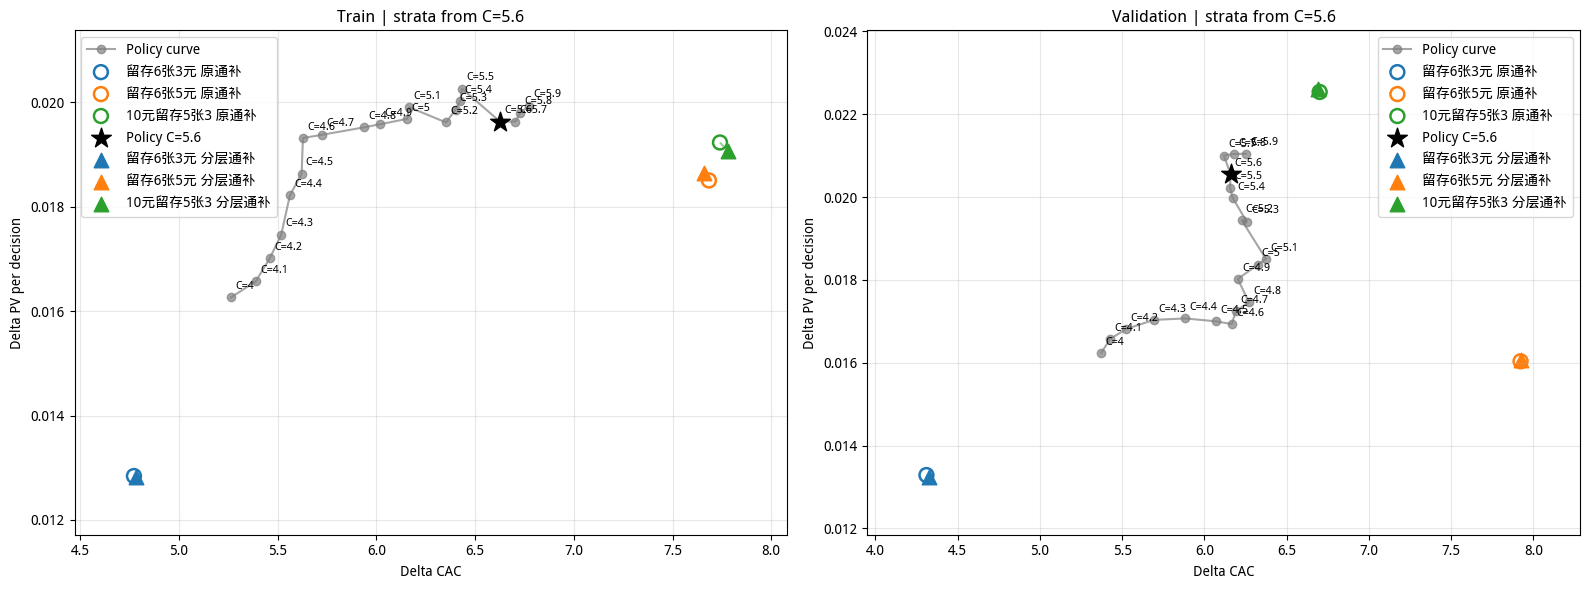

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161428,historical_rct_replay,812267.0,13208.897721,69524.011394,0.016262,5.263423,0,[],21889.123535,87556.847656,4.000016,0.353516,False,False,0.424521,0.016262,False
1,4.1,0.155616,historical_rct_replay,812267.0,13464.128943,72570.522525,0.016576,5.389916,0,[],22238.649902,91177.960938,4.099977,-0.503662,True,True,0.419483,0.016576,False
2,4.2,0.150269,historical_rct_replay,812267.0,13820.217991,75454.920799,0.017014,5.459749,0,[],22581.407715,94842.138672,4.200010,0.226270,False,False,0.414690,0.017014,False
3,4.3,0.145187,historical_rct_replay,812267.0,14185.767201,78272.997588,0.017464,5.517713,0,[],22917.522461,98546.169922,4.300036,0.823340,False,False,0.410205,0.017464,False
4,4.4,0.140022,historical_rct_replay,812267.0,14795.689845,82286.734242,0.018215,5.561534,0,[],23246.564453,102284.455078,4.399982,-0.428516,True,True,0.405843,0.018215,False
5,4.5,0.134103,historical_rct_replay,812267.0,15136.851079,85085.986490,0.018635,5.621115,0,[],23567.850586,106056.996094,4.500071,1.668457,False,False,0.400808,0.018635,False
6,4.6,0.126806,historical_rct_replay,812267.0,15689.481182,88294.342114,0.019316,5.627614,0,[],23877.372559,109835.613281,4.599987,-0.300488,True,True,0.395143,0.019316,False
7,4.7,0.117885,historical_rct_replay,812267.0,15740.476097,90127.554717,0.019378,5.725847,0,[],24171.572266,113606.034180,4.699985,-0.355469,True,True,0.388169,0.019378,False
8,4.8,0.107832,historical_rct_replay,812267.0,15854.994489,94110.551915,0.019519,5.935704,0,[],24446.164551,117342.013672,4.800017,0.423828,False,False,0.380056,0.019519,False
9,4.9,0.097534,historical_rct_replay,812267.0,15904.672182,95737.222309,0.019581,6.019440,0,[],24698.350098,121020.990234,4.899963,-0.925244,True,True,0.371400,0.019581,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161428,historical_rct_replay,807865.0,13118.281555,70487.608095,0.016238,5.373235,0,[],22610.649414,90137.103516,3.986489,-305.494141,True,True,0.417036,0.016238,False
1,4.1,0.155616,historical_rct_replay,807865.0,13390.594677,72666.000032,0.016575,5.426645,0,[],22979.397949,93957.546875,4.088773,-257.984717,True,True,0.412076,0.016575,False
2,4.2,0.150269,historical_rct_replay,807865.0,13586.680128,75076.474520,0.016818,5.525741,0,[],23350.313477,97922.880859,4.193643,-148.435742,True,True,0.407416,0.016818,False
3,4.3,0.145187,historical_rct_replay,807865.0,13762.765589,78354.016588,0.017036,5.693188,0,[],23711.545898,101902.845703,4.297604,-56.801660,True,True,0.403103,0.017036,False
4,4.4,0.140022,historical_rct_replay,807865.0,13791.040516,81130.751063,0.017071,5.882859,0,[],24061.208496,105874.554688,4.400218,5.237305,False,False,0.398773,0.017071,False
5,4.5,0.134103,historical_rct_replay,807865.0,13734.975598,83357.233526,0.017002,6.068976,0,[],24398.827637,109838.181641,4.501781,43.457275,False,False,0.394058,0.017002,False
6,4.6,0.126806,historical_rct_replay,807865.0,13681.822659,84369.216427,0.016936,6.166519,0,[],24720.401855,113763.585938,4.602012,49.737402,False,False,0.388436,0.016936,False
7,4.7,0.117885,historical_rct_replay,807865.0,13935.702348,86281.467792,0.017250,6.191397,0,[],25016.451904,117557.564453,4.699210,-19.759497,True,True,0.381373,0.017250,False
8,4.8,0.107832,historical_rct_replay,807865.0,14105.199967,88460.393273,0.017460,6.271474,0,[],25285.936035,121224.163086,4.794134,-148.329883,True,True,0.373418,0.017460,False
9,4.9,0.097534,historical_rct_replay,807865.0,14559.811562,90311.888680,0.018023,6.202820,0,[],25536.515381,124879.321289,4.890226,-249.604077,True,True,0.364901,0.018023,False


In [174]:
# V3: C=5.7, λ=0.02234797637

all_val_data_pdf_euen = all_rct_data_pdf_v3.copy()
prefix = 'msg_euen_uplift_cost_26_v3_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen['delta_cvr_' + action] = all_val_data_pdf_euen[prefix + f'uplift_{head}']
    all_val_data_pdf_euen['cost_' + action] = all_val_data_pdf_euen[prefix + f'cost_{head}']
all_val_data_pdf_euen['finish_cnt_7d'] = all_val_data_pdf_euen['pv_label_7d']
dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-11', '2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17']
val_dt = ['2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24']

all_val_data_pdf_euen_use = all_val_data_pdf_euen[all_val_data_pdf_euen['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

求解日期: ['2026-08-11', '2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17'] 验证日期: ['2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24']
求解样本: 812267 验证样本: 807865
求解集 - C=4, λ=0.1576289897: delta_cac=4.9530, delta_pv_per_user=0.0167
验证集 - C=4, λ=0.1576289897: delta_cac=4.9828, delta_pv_per_user=0.0161
求解集 - C=4.1, λ=0.1541762253: delta_cac=5.0412, delta_pv_per_user=0.0174
验证集 - C=4.1, λ=0.1541762253: delta_cac=4.9956, delta_pv_per_user=0.0164
求解集 - C=4.2, λ=0.151114982: delta_cac=5.0964, delta_pv_per_user=0.0177
验证集 - C=4.2, λ=0.151114982: delta_cac=5.0234, delta_pv_per_user=0.0169
求解集 - C=4.3, λ=0.148535059: delta_cac=5.2138, delta_pv_per_user=0.0180
验证集 - C=4.3, λ=0.148535059: delta_cac=5.0964, delta_pv_per_user=0.0173
求解集 - C=4.4, λ=0.146237172: delta_cac=5.4161, delta_pv_per_user=0.0177
验证集 - C=4.4, λ=0.146237172: delta_cac=5.1782, delta_pv_per_user=0.0176
求解集 - C=4.5, λ=0.1442485173: delta_cac=5.5072, delta_p

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121539,left_63,留存6张3元,True,10201.020130,49632.201190,0.012559,4.865415
1,5.6,0.121539,left_65,留存6张5元,True,14626.651019,114392.725824,0.018007,7.820842
2,5.6,0.121539,left_1053,10元留存5张3,True,15415.231620,120987.192656,0.018978,7.848548


Validation分层通补：C=5.6，λ=0.1215387017


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121539,left_63,留存6张3元,True,10474.097126,46032.345603,0.012965,4.394875
1,5.6,0.121539,left_65,留存6张5元,True,12649.771011,101724.024743,0.015658,8.041570
2,5.6,0.121539,left_1053,10元留存5张3,True,17934.098824,121465.831761,0.022199,6.772899


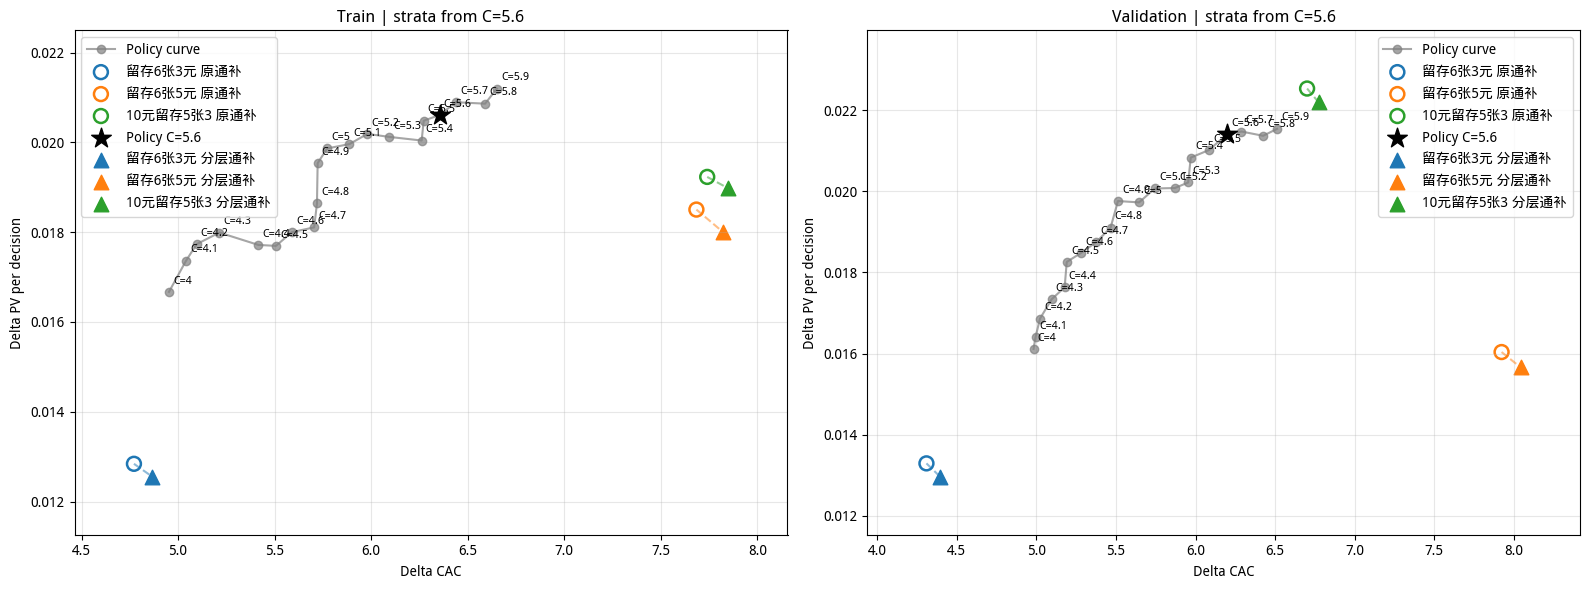

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.157629,historical_rct_replay,812267.0,13540.714348,67067.722876,0.016670,4.953042,0,[],17391.346924,69565.384277,4.000000,-0.003418,True,True,0.138490,0.016670,False
1,4.1,0.154176,historical_rct_replay,812267.0,14103.223507,71097.620236,0.017363,5.041232,0,[],17664.571045,72425.111328,4.100021,0.370044,False,False,0.137412,0.017363,False
2,4.2,0.151115,historical_rct_replay,812267.0,14403.393969,73404.990934,0.017732,5.096368,0,[],17936.250854,75332.529297,4.200015,0.275708,False,False,0.136512,0.017732,False
3,4.3,0.148535,historical_rct_replay,812267.0,14613.743521,76193.753418,0.017991,5.213842,0,[],18207.063965,78291.516602,4.300063,1.141553,False,False,0.135708,0.017991,False
4,4.4,0.146237,historical_rct_replay,812267.0,14389.681676,77936.374617,0.017715,5.416129,0,[],18477.221191,81300.070312,4.400016,0.297070,False,False,0.134921,0.017715,False
5,4.5,0.144249,historical_rct_replay,812267.0,14372.878807,79153.690843,0.017695,5.507156,0,[],18747.274658,84361.646484,4.499942,-1.089478,True,True,0.134210,0.017695,False
6,4.6,0.142427,historical_rct_replay,812267.0,14620.753670,81721.058177,0.018000,5.589388,0,[],19018.010254,87482.712891,4.599993,-0.134277,True,True,0.133535,0.018000,False
7,4.7,0.140834,historical_rct_replay,812267.0,14707.731110,83906.448084,0.018107,5.704921,0,[],19289.262939,90659.270508,4.699986,-0.265308,True,True,0.132946,0.018107,False
8,4.8,0.139351,historical_rct_replay,812267.0,15140.188664,86592.893177,0.018639,5.719406,0,[],19561.317383,93893.915039,4.799979,-0.408398,True,True,0.132410,0.018639,False
9,4.9,0.137941,historical_rct_replay,812267.0,15869.494712,90820.298060,0.019537,5.722948,0,[],19834.685547,97191.429688,4.900074,1.470508,False,False,0.131928,0.019537,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.157629,historical_rct_replay,807865.0,13017.207468,64862.325159,0.016113,4.982814,0,[],17145.111328,68827.281738,4.014397,246.836426,False,False,0.140077,0.016113,False
1,4.1,0.154176,historical_rct_replay,807865.0,13256.802333,66225.083899,0.016410,4.995555,0,[],17424.104980,71747.363281,4.117707,308.532861,False,False,0.139022,0.016410,False
2,4.2,0.151115,historical_rct_replay,807865.0,13622.135799,68429.758841,0.016862,5.023424,0,[],17704.320801,74746.431641,4.221932,388.284277,False,False,0.138068,0.016862,False
3,4.3,0.148535,historical_rct_replay,807865.0,14007.367043,71387.146568,0.017339,5.096400,0,[],17977.674927,77733.438477,4.323887,429.436292,False,False,0.137205,0.017339,False
4,4.4,0.146237,historical_rct_replay,807865.0,14246.517502,73770.674123,0.017635,5.178155,0,[],18243.215332,80690.687500,4.423052,420.540039,False,False,0.136436,0.017635,False
5,4.5,0.144249,historical_rct_replay,807865.0,14750.976880,76576.646078,0.018259,5.191293,0,[],18510.158936,83716.528320,4.522734,420.813110,False,False,0.135775,0.018259,False
6,4.6,0.142427,historical_rct_replay,807865.0,14930.998362,78851.783787,0.018482,5.281079,0,[],18788.263672,86922.601562,4.626431,496.588672,False,False,0.135143,0.018482,False
7,4.7,0.140834,historical_rct_replay,807865.0,15147.188048,81436.088917,0.018750,5.376317,0,[],19059.718018,90101.784180,4.727341,521.109497,False,False,0.134520,0.018750,False
8,4.8,0.139351,historical_rct_replay,807865.0,15432.514690,84361.214288,0.019103,5.466459,0,[],19332.719482,93346.912109,4.828442,549.858594,False,False,0.133961,0.019103,False
9,4.9,0.137941,historical_rct_replay,807865.0,15965.379722,88017.215906,0.019762,5.513005,0,[],19606.383301,96648.092773,4.929420,576.814600,False,False,0.133432,0.019762,False


In [168]:
# V4: C=5.5, λ=0.1239815851

all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-11', '2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17']
val_dt = ['2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24']

all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

## STEP 2: 对比三套方案-应用时间段使用分日计算汇总

In [176]:
# 1. 固定方案： 七天一直使用 C、λ
# 2. 固定C、每日重解λ
# 3. 多C、λ后验筛选

In [175]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest.opt)
importlib.reload(backtest)

bt_v3_three = backtest.run_backtest(
    raw=all_rct_data_pdf_v3,
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    initial_params={
        "C": 5.7,
        "lambda": 0.02234797637,
    },
    cost_list=[i / 10 for i in range(40, 60)],
    train_days=7,
    val_days=7,
    maturity_lag=6,
    include_fixed_c_daily=True,  # 开启三方案比较
)

In [177]:
with pd.option_context("display.precision", 12):
    display(bt_v3_three["summary"][
        [
            "strategy", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]
    ])

,strategy,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share
0,rolling,703042,7,historical_rct_replay,0.014699605481,7.296125030771,0.288395287906
1,fixed_initial,703042,7,historical_rct_replay,0.014287446310,7.372739451203,0.299895312087
2,fixed_c_daily,703042,7,historical_rct_replay,0.014337498550,7.339298736545,0.301284987241


In [178]:
import importlib
import pandas as pd
from IPython.display import display
import online_opt_param_backtest as backtest

importlib.reload(backtest.opt)
importlib.reload(backtest)

bt_v4_three = backtest.run_backtest(
    raw=all_rct_data_pdf_v4,
    model_version="v4",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    initial_params={
        "C": 5.5,
        "lambda": 0.1239815851,
    },
    cost_list=[i / 10 for i in range(40, 60)],
    train_days=7,
    val_days=7,
    maturity_lag=6,
    include_fixed_c_daily=True,  # 开启三方案比较
)

In [179]:
with pd.option_context("display.precision", 12):
    display(bt_v4_three["summary"][
        [
            "strategy", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac", "no_send_share",
        ]
    ])

,strategy,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share
0,rolling,703042,7,historical_rct_replay,0.015070833841,6.988109007963,0.150636804060
1,fixed_initial,703042,7,historical_rct_replay,0.015044919609,6.847166255606,0.151175889918
2,fixed_c_daily,703042,7,historical_rct_replay,0.014933969125,6.854060174733,0.151505884428


# 在线运筹糙版仿真

## 26_V4

In [27]:
all_rct_data_pdf_v4['dt'].unique()

array(['2026-08-27', '2026-08-14', '2026-08-12', '2026-08-20',
       '2026-08-29', '2026-08-13', '2026-08-28', '2026-08-15',
       '2026-09-02', '2026-08-26', '2026-09-03', '2026-09-04',
       '2026-08-30', '2026-08-11', '2026-08-22', '2026-08-23',
       '2026-08-24', '2026-08-18', '2026-08-31', '2026-08-16',
       '2026-08-17', '2026-08-25', '2026-08-21', '2026-09-01',
       '2026-08-19'], dtype=object)

In [63]:
all_rct_data_pdf_v4[all_rct_data_pdf_v4['cost_7d']>0]

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,msg_euen_uplift_cost_26_v4_final_cost_3,msg_euen_uplift_cost_26_v4_final_cost_4,msg_euen_uplift_cost_26_v4_final_uplift_diff_2_1,msg_euen_uplift_cost_26_v4_final_uplift_diff_3_1,msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1,msg_euen_uplift_cost_26_v4_final_uplift_diff_3_2,msg_euen_uplift_cost_26_v4_final_uplift_diff_4_2,msg_euen_uplift_cost_26_v4_final_uplift_diff_4_3,msg_euen_uplift_cost_26_v4_treatment,delta_prob
3,8元留存5张3,100224001,v1_35184375223644,探索,2.0,1.0,0.021,0.0,0.0,0.12,...,0.020591,0.024047,0.001769,0.001846,0.005120,0.000077,0.003351,0.003274,2.0,0.001846
4,10元留存5张3,100234662,v1_17592427224261,探索,2.0,1.0,0.021,0.0,0.0,0.12,...,0.063102,0.096754,0.004110,0.003879,0.007305,-0.000231,0.003196,0.003426,4.0,0.003879
13,留存6张3元,100928942,v1_17592940326927,探索,2.0,1.0,0.021,0.0,0.0,0.12,...,0.126490,0.182688,0.005190,0.003806,0.010597,-0.001384,0.005407,0.006792,1.0,0.003806
19,10元留存5张3,101164670,v1_e57c8db62f481bec981e083cd025051a,探索,2.0,1.0,0.021,0.0,0.0,0.00,...,0.145115,0.195126,0.004585,0.004432,0.010561,-0.000153,0.005976,0.006129,4.0,0.004432
27,留存6张5元,1018341036032,v1_17592786708094,探索,2.0,1.0,0.021,0.0,0.0,0.00,...,0.041172,0.051226,0.002593,0.002931,0.005867,0.000338,0.003273,0.002936,3.0,0.002931
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3162297,留存6张5元,847640530944,v1_17592586052159,探索,2.0,1.0,0.021,0.0,0.0,0.00,...,0.098283,0.135990,0.004991,0.004545,0.013789,-0.000446,0.008799,0.009244,3.0,0.004545
3162337,留存6张3元,942806081537,v1_17592750973445,探索,2.0,1.0,0.021,0.0,0.0,0.12,...,0.196732,0.222871,0.003820,0.006536,0.012609,0.002717,0.008790,0.006073,1.0,0.006536
3162348,留存6张5元,959460741122,v1_17592736138722,探索,2.0,1.0,0.021,0.0,0.0,0.12,...,0.077362,0.116399,0.003687,0.003814,0.007518,0.000128,0.003832,0.003704,3.0,0.003814
3162352,留存6张3元,965679194113,v1_17592752832383,探索,2.0,1.0,0.021,0.0,0.0,0.12,...,0.092175,0.134356,0.004674,0.003440,0.007396,-0.001234,0.002722,0.003956,1.0,0.003440


In [28]:
all_rct_data_pdf_v4['group_name_eve'].unique()

array(['DS空白', '8元留存5张3', '10元留存5张3', '留存6张3元', '留存6张5元'], dtype=object)

In [53]:
df = all_rct_data_pdf_v4  # 建议替换成同一验证日期范围的数据
prefix = 'msg_euen_uplift_cost_26_v4_final_'
groups = {
    1: '留存6张3元',
    2: '8元留存5张3',
    3: '留存6张5元',
    4: '10元留存5张3',
}

control = df.loc[df['group_name_eve'] == 'DS空白', 'pv_label_7d']
rows = []

for head, group in groups.items():
    treatment = df.loc[df['group_name_eve'] == group, 'pv_label_7d']

    predicted = df[prefix + f'uplift_{head}'].mean()
    observed = treatment.mean() - control.mean()

    rows.append({
        'action': group,
        'predicted_uplift': predicted,
        'rct_uplift': observed,
        'prediction_minus_rct': predicted - observed,
        'treatment_n': len(treatment),
        'control_n': len(control),
    })

uplift_calibration_df = pd.DataFrame(rows)
display(uplift_calibration_df)

,action,predicted_uplift,rct_uplift,prediction_minus_rct,treatment_n,control_n
0,留存6张3元,0.009442,0.011368,-0.001926,558633,1572080
1,8元留存5张3,0.014366,0.013493,0.000872,370827,1572080
2,留存6张5元,0.017837,0.015827,0.002009,291926,1572080
3,10元留存5张3,0.021045,0.018185,0.002860,368896,1572080


### 新时间段

求解日期: ['2026-08-12', '2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18'] 验证日期: ['2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25']
求解样本: 810705 验证样本: 803803
求解集 - C=4, λ=0.1580617122: delta_cac=4.8516, delta_pv_per_user=0.0173
验证集 - C=4, λ=0.1580617122: delta_cac=5.1276, delta_pv_per_user=0.0154
求解集 - C=4.1, λ=0.1545803309: delta_cac=4.9528, delta_pv_per_user=0.0178
验证集 - C=4.1, λ=0.1545803309: delta_cac=5.1477, delta_pv_per_user=0.0156
求解集 - C=4.2, λ=0.1516002536: delta_cac=5.0173, delta_pv_per_user=0.0181
验证集 - C=4.2, λ=0.1516002536: delta_cac=5.1997, delta_pv_per_user=0.0160
求解集 - C=4.3, λ=0.1489897507: delta_cac=5.1198, delta_pv_per_user=0.0185
验证集 - C=4.3, λ=0.1489897507: delta_cac=5.2822, delta_pv_per_user=0.0163
求解集 - C=4.4, λ=0.146634301: delta_cac=5.2843, delta_pv_per_user=0.0185
验证集 - C=4.4, λ=0.146634301: delta_cac=5.3103, delta_pv_per_user=0.0169
求解集 - C=4.5, λ=0.144563601: delta_cac=5.4238, delt

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121722,left_63,留存6张3元,True,10617.932815,49368.084868,0.013097,4.649501
1,5.6,0.121722,left_65,留存6张5元,True,15615.565957,115341.396620,0.019262,7.386309
2,5.6,0.121722,left_1053,10元留存5张3,True,16989.041519,123646.494366,0.020956,7.278015


Validation分层通补：C=5.6，λ=0.1217217676


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121722,left_63,留存6张3元,True,9451.583613,44717.240424,0.011759,4.731190
1,5.6,0.121722,left_65,留存6张5元,True,11315.603275,97748.247830,0.014078,8.638359
2,5.6,0.121722,left_1053,10元留存5张3,True,17044.869080,120120.178192,0.021205,7.047293


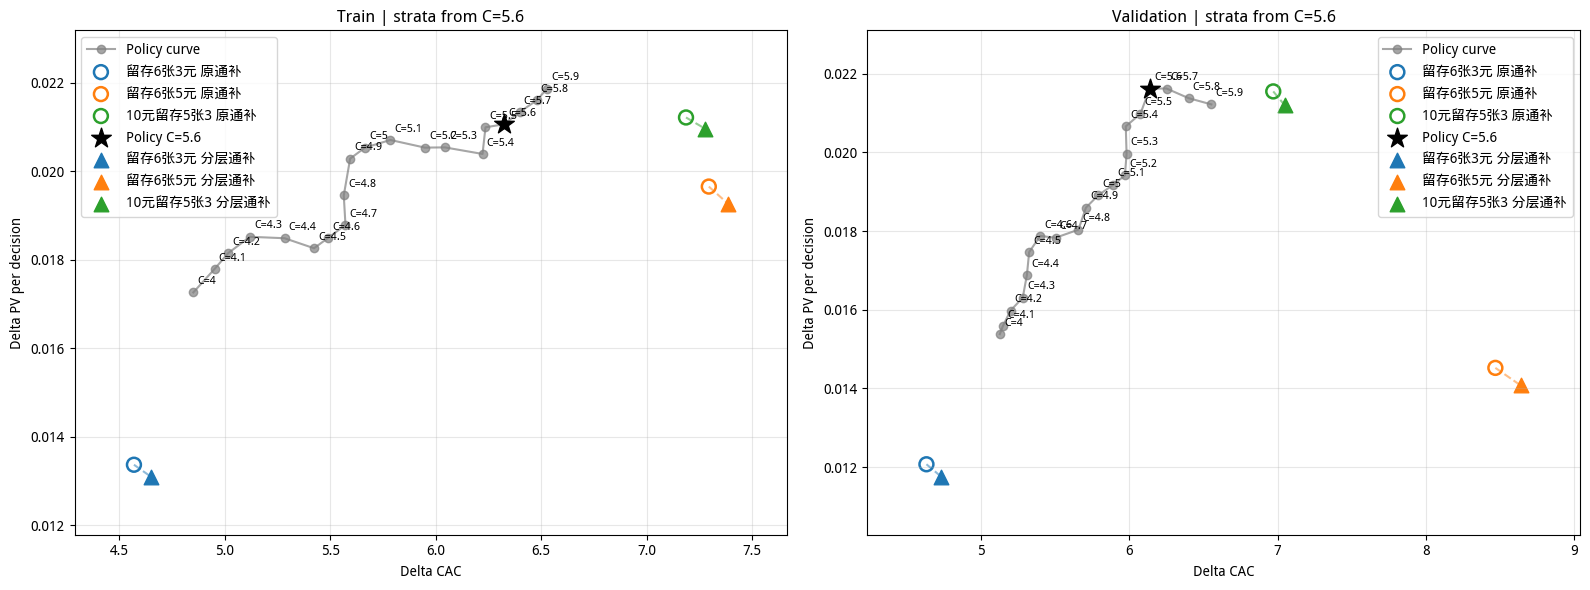

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158062,historical_rct_replay,810705.0,13990.880904,67877.827077,0.017258,4.851576,0,[],17317.707031,69269.891113,3.999946,-0.937012,True,True,0.138286,0.017258,False
1,4.1,0.154580,historical_rct_replay,810705.0,14422.948166,71434.359556,0.017791,4.952826,0,[],17590.871094,72124.210938,4.100093,1.639453,False,False,0.137269,0.017791,False
2,4.2,0.151600,historical_rct_replay,810705.0,14711.992742,73814.174795,0.018147,5.017279,0,[],17861.850830,75019.259766,4.199971,-0.513721,True,True,0.136346,0.018147,False
3,4.3,0.148990,historical_rct_replay,810705.0,15010.493264,76850.701944,0.018515,5.119799,0,[],18132.268311,77968.314453,4.299976,-0.439282,True,True,0.135523,0.018515,False
4,4.4,0.146634,historical_rct_replay,810705.0,14984.015002,79179.305971,0.018483,5.284252,0,[],18402.456055,80971.792969,4.400054,0.986328,False,False,0.134699,0.018483,False
5,4.5,0.144564,historical_rct_replay,810705.0,14800.682966,80275.615322,0.018257,5.423778,0,[],18672.245605,84025.798828,4.500037,0.693604,False,False,0.133998,0.018257,False
6,4.6,0.142723,historical_rct_replay,810705.0,14990.975110,82315.257524,0.018491,5.490988,0,[],18942.333008,87135.394531,4.600035,0.662695,False,False,0.133314,0.018491,False
7,4.7,0.141138,historical_rct_replay,810705.0,15229.068930,84867.799795,0.018785,5.572750,0,[],19213.053955,90301.724609,4.700019,0.371021,False,False,0.132705,0.018785,False
8,4.8,0.139635,historical_rct_replay,810705.0,15769.011430,87750.554210,0.019451,5.564747,0,[],19484.477783,93524.676758,4.799958,-0.816602,True,True,0.132157,0.019451,False
9,4.9,0.138202,historical_rct_replay,810705.0,16442.911199,91997.340589,0.020282,5.594955,0,[],19757.066895,96809.036133,4.899970,-0.591650,True,True,0.131634,0.020282,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158062,historical_rct_replay,803803.0,12362.927168,63391.883624,0.015381,5.127579,0,[],16946.788940,67929.432617,4.008396,142.276855,False,False,0.139167,0.015381,False
1,4.1,0.154580,historical_rct_replay,803803.0,12524.214858,64471.515704,0.015581,5.147749,0,[],17226.724243,70854.620117,4.113064,225.050720,False,False,0.138069,0.015581,False
2,4.2,0.151600,historical_rct_replay,803803.0,12843.832345,66783.601486,0.015979,5.199663,0,[],17494.684448,73717.053711,4.213683,239.379028,False,False,0.137090,0.015979,False
3,4.3,0.148990,historical_rct_replay,803803.0,13107.376979,69235.205910,0.016307,5.282156,0,[],17762.728760,76640.375977,4.314674,260.642310,False,False,0.136276,0.016307,False
4,4.4,0.146634,historical_rct_replay,803803.0,13573.024852,72076.467843,0.016886,5.310273,0,[],18031.518066,79628.270508,4.416060,289.591016,False,False,0.135517,0.016886,False
5,4.5,0.144564,historical_rct_replay,803803.0,14037.387970,74753.519574,0.017464,5.325315,0,[],18307.589111,82752.825195,4.520138,368.674194,False,False,0.134817,0.017464,False
6,4.6,0.142723,historical_rct_replay,803803.0,14369.827029,77587.223503,0.017877,5.399315,0,[],18579.299072,85880.983398,4.622402,416.207666,False,False,0.134197,0.017877,False
7,4.7,0.141138,historical_rct_replay,803803.0,14332.860429,78881.484902,0.017831,5.503541,0,[],18843.979004,88976.697266,4.721757,409.995947,False,False,0.133590,0.017831,False
8,4.8,0.139635,historical_rct_replay,803803.0,14497.322728,82017.921511,0.018036,5.657453,0,[],19120.051758,92254.332031,4.825004,478.083594,False,False,0.133050,0.018036,False
9,4.9,0.138202,historical_rct_replay,803803.0,14948.587461,85330.922564,0.018597,5.708293,0,[],19392.812988,95540.869141,4.926612,516.085498,False,False,0.132534,0.018597,False


In [123]:
all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-12', '2026-08-13','2026-08-14','2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18']
val_dt = ['2026-08-19', '2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25']

all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

In [99]:
focus_cost = 5.6
optimal_lambda = next(
    r['optimal_lambda']
    for r in train_results
    if r['cost_setting'] == focus_cost
)

val_metrics, val_replay_detail, val_selected = apply_lambda_strategy(
    val_df, optimal_lambda, focus_cost,
    dict_coupon, control_name, action_list,
    return_details=True,
)

# 推荐占比按全部验证样本计算，与历史实际RCT分组占比不同。
action_share_df = (
    val_selected['best_intervention'].value_counts()
    .reindex(action_list, fill_value=0)
    .rename_axis('action').rename('count').reset_index()
)
action_share_df['coupon'] = action_share_df['action'].map(dict_coupon)
total_n = len(val_selected)
send_n = int(action_share_df.loc[action_share_df.action != 'C', 'count'].sum())
action_share_df['share_all_pct'] = action_share_df['count'] / total_n * 100 if total_n else np.nan
action_share_df['share_sent_pct'] = np.nan
if send_n:
    mask = action_share_df.action != 'C'
    action_share_df.loc[mask, 'share_sent_pct'] = action_share_df.loc[mask, 'count'] / send_n * 100
action_share_df['cost_setting'] = focus_cost
action_share_df['optimal_lambda'] = optimal_lambda
action_share_df = action_share_df[['cost_setting', 'optimal_lambda', 'action', 'coupon',
                                 'count', 'share_all_pct', 'share_sent_pct']]
print(f'验证集推荐占比：C={focus_cost:g}，λ={optimal_lambda:.10g}，总样本={total_n}，发券样本={send_n}')
display(action_share_df.round({'share_all_pct': 2, 'share_sent_pct': 2}))

验证集推荐占比：C=5.6，λ=0.1218002994，总样本=792415，发券样本=691526


,cost_setting,optimal_lambda,action,coupon,count,share_all_pct,share_sent_pct
0,5.6,0.1218,left_63,留存6张3元,18807,2.37,2.72
1,5.6,0.1218,C,DS空白,100889,12.73,NaN
2,5.6,0.1218,left_65,留存6张5元,45319,5.72,6.55
3,5.6,0.1218,left_1053,10元留存5张3,627400,79.18,90.73


In [107]:
len(val_df[val_df['group_name_eve']=='10元留存5张3'])

104521

求解日期: ['2026-08-13', '2026-08-14', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19'] 验证日期: ['2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26']
求解样本: 815179 验证样本: 792415
求解集 - C=4, λ=0.1583258632: delta_cac=5.0211, delta_pv_per_user=0.0166
验证集 - C=4, λ=0.1583258632: delta_cac=5.1352, delta_pv_per_user=0.0153
求解集 - C=4.1, λ=0.1548378342: delta_cac=5.0750, delta_pv_per_user=0.0172
验证集 - C=4.1, λ=0.1548378342: delta_cac=5.1948, delta_pv_per_user=0.0153
求解集 - C=4.2, λ=0.1518643895: delta_cac=5.1000, delta_pv_per_user=0.0176
验证集 - C=4.2, λ=0.1518643895: delta_cac=5.2714, delta_pv_per_user=0.0155
求解集 - C=4.3, λ=0.1491951127: delta_cac=5.2189, delta_pv_per_user=0.0179
验证集 - C=4.3, λ=0.1491951127: delta_cac=5.3394, delta_pv_per_user=0.0160
求解集 - C=4.4, λ=0.1468309784: delta_cac=5.3401, delta_pv_per_user=0.0182
验证集 - C=4.4, λ=0.1468309784: delta_cac=5.3505, delta_pv_per_user=0.0164
求解集 - C=4.5, λ=0.1447413237: delta_cac=5.5021, d

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121965,left_63,留存6张3元,True,10269.814098,48153.218497,0.012598,4.688811
1,5.6,0.121965,left_65,留存6张5元,True,15485.275523,115905.605876,0.018996,7.484891
2,5.6,0.121965,left_1053,10元留存5张3,True,17761.832063,125508.341417,0.021789,7.066182


Validation分层通补：C=5.6，λ=0.1219645679


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.121965,left_63,留存6张3元,True,9481.318052,44223.621204,0.011965,4.664290
1,5.6,0.121965,left_65,留存6张5元,True,11896.858794,97098.338704,0.015013,8.161679
2,5.6,0.121965,left_1053,10元留存5张3,True,15636.733552,114697.549395,0.019733,7.335135


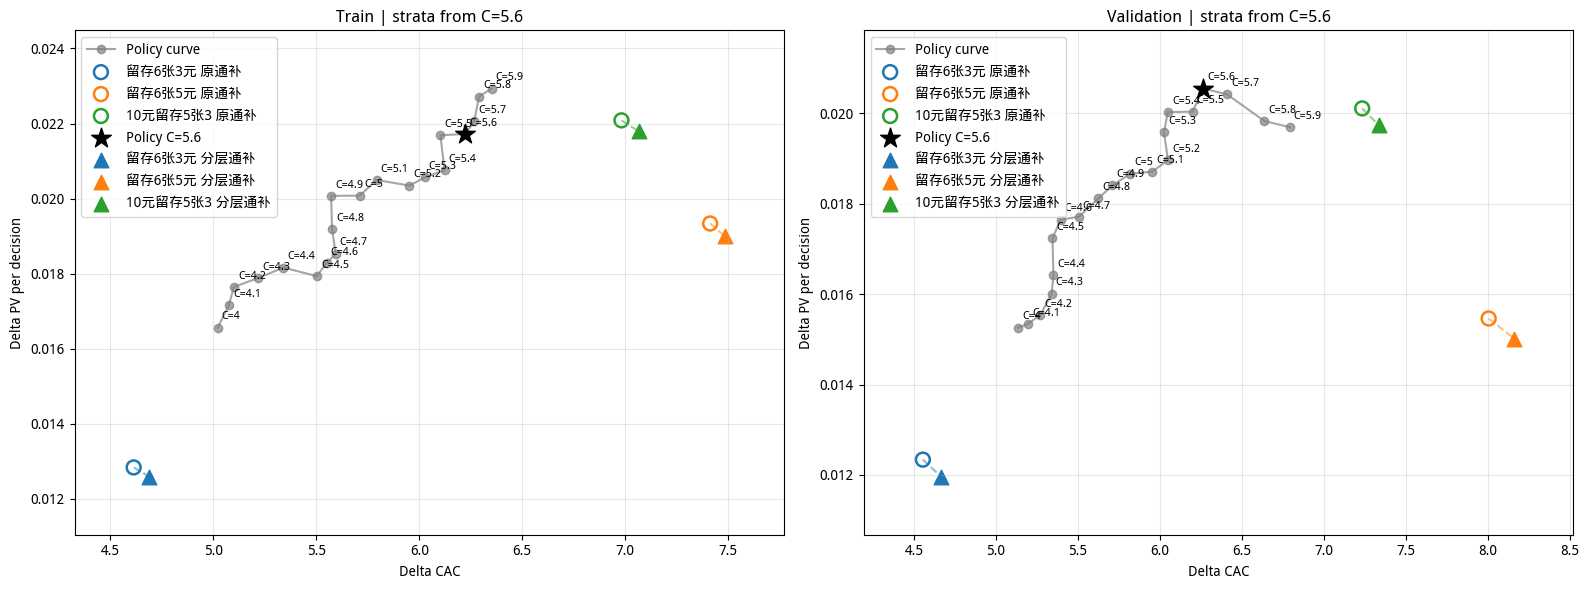

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158326,historical_rct_replay,815179.0,13502.794325,67798.221397,0.016564,5.021051,0,[],17368.227295,69472.679199,3.999987,-0.229980,True,True,0.137813,0.016564,False
1,4.1,0.154838,historical_rct_replay,815179.0,13983.468826,70965.441482,0.017154,5.074953,0,[],17642.506104,72335.509766,4.100070,1.234741,False,False,0.136775,0.017154,False
2,4.2,0.151864,historical_rct_replay,815179.0,14387.329817,73375.360779,0.017649,5.099999,0,[],17914.711914,75240.602539,4.199934,-1.187500,True,True,0.135843,0.017649,False
3,4.3,0.149195,historical_rct_replay,815179.0,14581.501962,76098.951179,0.017887,5.218869,0,[],18186.301270,78199.449219,4.299909,-1.646240,True,True,0.135035,0.017887,False
4,4.4,0.146831,historical_rct_replay,815179.0,14807.206605,79072.486322,0.018164,5.340135,0,[],18457.632324,81213.057617,4.399972,-0.524609,True,True,0.134253,0.018164,False
5,4.5,0.144741,historical_rct_replay,815179.0,14621.251137,80447.098780,0.017936,5.502067,0,[],18728.562012,84277.345703,4.499937,-1.183350,True,True,0.133534,0.017936,False
6,4.6,0.142887,historical_rct_replay,815179.0,14901.938344,82710.192531,0.018281,5.550298,0,[],19000.056396,87400.575195,4.600017,0.315771,False,False,0.132844,0.018281,False
7,4.7,0.141343,historical_rct_replay,815179.0,15107.349125,84513.889403,0.018533,5.594224,0,[],19272.089355,90579.742188,4.700048,0.922217,False,False,0.132234,0.018533,False
8,4.8,0.139822,historical_rct_replay,815179.0,15641.462320,87225.327285,0.019188,5.576546,0,[],19544.736328,93814.623047,4.799994,-0.111328,True,True,0.131683,0.019188,False
9,4.9,0.138387,historical_rct_replay,815179.0,16363.756092,91178.206488,0.020074,5.571961,0,[],19818.542480,97111.068359,4.900011,0.210205,False,False,0.131133,0.020074,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158326,historical_rct_replay,792415.0,12089.644594,62082.873381,0.015257,5.135211,0,[],16664.800537,66737.397949,4.004692,78.195801,False,False,0.138309,0.015257,False
1,4.1,0.154838,historical_rct_replay,792415.0,12154.122487,63138.374443,0.015338,5.194811,0,[],16939.211182,69601.893555,4.108922,151.127710,False,False,0.137215,0.015338,False
2,4.2,0.151864,historical_rct_replay,792415.0,12315.290147,64918.220925,0.015541,5.271351,0,[],17201.685547,72402.849609,4.209056,155.770312,False,False,0.136228,0.015541,False
3,4.3,0.149195,historical_rct_replay,792415.0,12685.594523,67733.235684,0.016009,5.339382,0,[],17466.904297,75292.670898,4.310590,184.982422,False,False,0.135385,0.016009,False
4,4.4,0.146831,historical_rct_replay,792415.0,13008.129044,69600.245089,0.016416,5.350519,0,[],17732.267334,78240.125000,4.412302,218.148730,False,False,0.134599,0.016416,False
5,4.5,0.144741,historical_rct_replay,792415.0,13656.698923,72988.425279,0.017234,5.344514,0,[],18003.650879,81309.523438,4.516280,293.094482,False,False,0.133887,0.017234,False
6,4.6,0.142887,historical_rct_replay,792415.0,13985.208742,75440.969947,0.017649,5.394340,0,[],18269.343018,84366.374023,4.617921,327.396143,False,False,0.133271,0.017649,False
7,4.7,0.141343,historical_rct_replay,792415.0,14033.083356,77244.478526,0.017709,5.504455,0,[],18526.859863,87375.897461,4.716174,299.656104,False,False,0.132683,0.017709,False
8,4.8,0.139822,historical_rct_replay,792415.0,14357.531517,80765.070124,0.018119,5.625275,0,[],18799.083740,90605.326172,4.819667,369.724219,False,False,0.132132,0.018119,False
9,4.9,0.138387,historical_rct_replay,792415.0,14584.858764,83281.173907,0.018406,5.710112,0,[],19065.556641,93813.559570,4.920578,392.332031,False,False,0.131638,0.018406,False


In [100]:
all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-13','2026-08-14','2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19']
val_dt = ['2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26']

all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

In [101]:
val_tongbu_points

{'留存6张3元': (4.554034085965027, 0.012338762447203264),
 '留存6张5元': (8.005399114463831, 0.015460531076017227),
 '10元留存5张3': (7.233911457976402, 0.020107566825703978)}

求解日期: ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21'] 验证日期: ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
求解样本: 812972 验证样本: 728329
求解集 - C=4, λ=0.1583429088: delta_cac=4.7935, delta_pv_per_user=0.0177
验证集 - C=4, λ=0.1583429088: delta_cac=5.1947, delta_pv_per_user=0.0113
求解集 - C=4.1, λ=0.1549249563: delta_cac=4.8750, delta_pv_per_user=0.0179
验证集 - C=4.1, λ=0.1549249563: delta_cac=5.2126, delta_pv_per_user=0.0117
求解集 - C=4.2, λ=0.151979221: delta_cac=4.9205, delta_pv_per_user=0.0183
验证集 - C=4.2, λ=0.151979221: delta_cac=5.3261, delta_pv_per_user=0.0117
求解集 - C=4.3, λ=0.149250509: delta_cac=5.0172, delta_pv_per_user=0.0184
验证集 - C=4.3, λ=0.149250509: delta_cac=5.4570, delta_pv_per_user=0.0117
求解集 - C=4.4, λ=0.1468620667: delta_cac=5.0924, delta_pv_per_user=0.0187
验证集 - C=4.4, λ=0.1468620667: delta_cac=5.4933, delta_pv_per_user=0.0122
求解集 - C=4.5, λ=0.144760492: delta_cac=5.2078, delta_

,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.122117,left_63,留存6张3元,True,10682.360569,48314.633597,0.013140,4.522842
1,5.6,0.122117,left_65,留存6张5元,True,14580.865235,110666.477876,0.017935,7.589843
2,5.6,0.122117,left_1053,10元留存5张3,True,18435.379418,125836.283774,0.022677,6.825804


Validation分层通补：C=5.6，λ=0.1221168435


,cost_setting,optimal_lambda,action,coupon,supported,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac
0,5.6,0.122117,left_63,留存6张3元,True,6219.020771,32242.811185,0.008539,5.184548
1,5.6,0.122117,left_65,留存6张5元,True,9687.295437,65224.865982,0.013301,6.733032
2,5.6,0.122117,left_1053,10元留存5张3,True,9919.781797,80728.726844,0.013620,8.138156


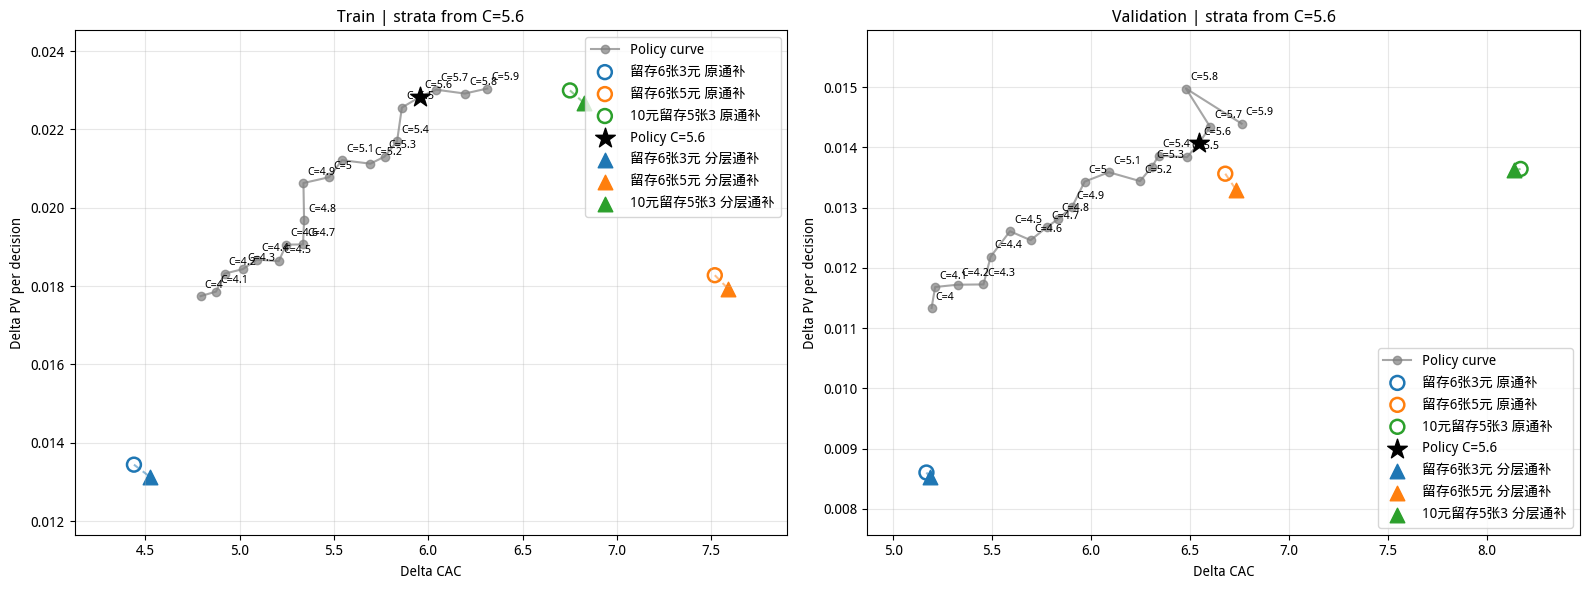

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158343,historical_rct_replay,812972.0,14426.097131,69151.121443,0.017745,4.793474,0,[],17321.293213,69284.793945,3.999978,-0.378906,True,True,0.138478,0.017745,False
1,4.1,0.154925,historical_rct_replay,812972.0,14519.642931,70783.537954,0.017860,4.875019,0,[],17594.812500,72139.255859,4.100030,0.524609,False,False,0.137440,0.017860,False
2,4.2,0.151979,historical_rct_replay,812972.0,14892.422694,73278.735962,0.018318,4.920538,0,[],17866.624634,75039.166016,4.199963,-0.657446,True,True,0.136519,0.018318,False
3,4.3,0.149251,historical_rct_replay,812972.0,14986.386233,75189.758548,0.018434,5.017204,0,[],18137.758667,77992.029297,4.299982,-0.332971,True,True,0.135664,0.018434,False
4,4.4,0.146862,historical_rct_replay,812972.0,15184.610465,77326.776654,0.018678,5.092444,0,[],18408.163086,80994.835938,4.399941,-1.081641,True,True,0.134889,0.018678,False
5,4.5,0.144760,historical_rct_replay,812972.0,15151.307561,78904.890271,0.018637,5.207794,0,[],18678.677734,84054.027344,4.499999,-0.022461,True,True,0.134194,0.018637,False
6,4.6,0.142944,historical_rct_replay,812972.0,15495.218342,81313.145001,0.019060,5.247628,0,[],18949.187500,87165.655273,4.599968,-0.607227,True,True,0.133564,0.019060,False
7,4.7,0.141368,historical_rct_replay,812972.0,15498.134632,82707.711966,0.019064,5.336624,0,[],19220.570312,90336.769531,4.700005,0.089063,False,False,0.132943,0.019064,False
8,4.8,0.139912,historical_rct_replay,812972.0,15996.003009,85448.766570,0.019676,5.341882,0,[],19492.653320,93564.019531,4.799963,-0.716406,True,True,0.132391,0.019676,False
9,4.9,0.138527,historical_rct_replay,812972.0,16773.249812,89545.556836,0.020632,5.338593,0,[],19765.954834,96852.964844,4.899989,-0.213843,True,True,0.131864,0.020632,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158343,historical_rct_replay,728329.0,8256.628395,42890.820159,0.011336,5.194714,0,[],14644.703857,59058.029785,4.032723,479.214355,False,False,0.158596,0.011336,False
1,4.1,0.154925,historical_rct_replay,728329.0,8509.693109,44357.953262,0.011684,5.212638,0,[],14874.402588,61455.616699,4.131636,470.566089,False,False,0.157460,0.011684,False
2,4.2,0.151979,historical_rct_replay,728329.0,8537.445462,45471.141508,0.011722,5.326083,0,[],15101.472168,63877.816406,4.229907,451.633301,False,False,0.156436,0.011722,False
3,4.3,0.149251,historical_rct_replay,728329.0,8540.848919,46606.990810,0.011727,5.456951,0,[],15335.503540,66426.520508,4.331551,483.855286,False,False,0.155470,0.011727,False
4,4.4,0.146862,historical_rct_replay,728329.0,8876.606837,48762.246860,0.012188,5.493343,0,[],15571.366333,69045.728516,4.434147,531.716650,False,False,0.154544,0.012188,False
5,4.5,0.144760,historical_rct_replay,728329.0,9183.848629,51347.404534,0.012609,5.591055,0,[],15806.172119,71701.353516,4.536288,573.578979,False,False,0.153816,0.012609,False
6,4.6,0.142944,historical_rct_replay,728329.0,9075.670921,51686.686325,0.012461,5.695082,0,[],16043.138184,74427.100586,4.639186,628.664941,False,False,0.153107,0.012461,False
7,4.7,0.141368,historical_rct_replay,728329.0,9233.542782,53349.664661,0.012678,5.777811,0,[],16275.954102,77147.718750,4.739981,650.734473,False,False,0.152494,0.012678,False
8,4.8,0.139912,historical_rct_replay,728329.0,9326.615855,54385.544625,0.012805,5.831220,0,[],16510.566650,79930.441406,4.841169,679.721484,False,False,0.151857,0.012805,False
9,4.9,0.138527,historical_rct_replay,728329.0,9474.165453,55936.274226,0.013008,5.904085,0,[],16739.682129,82687.388672,4.939603,662.946240,False,False,0.151289,0.013008,False


In [93]:
all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21']
val_dt = ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name,focus_cost=5.6)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

求解日期: ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21'] 验证日期: ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
求解样本: 812972 验证样本: 728329


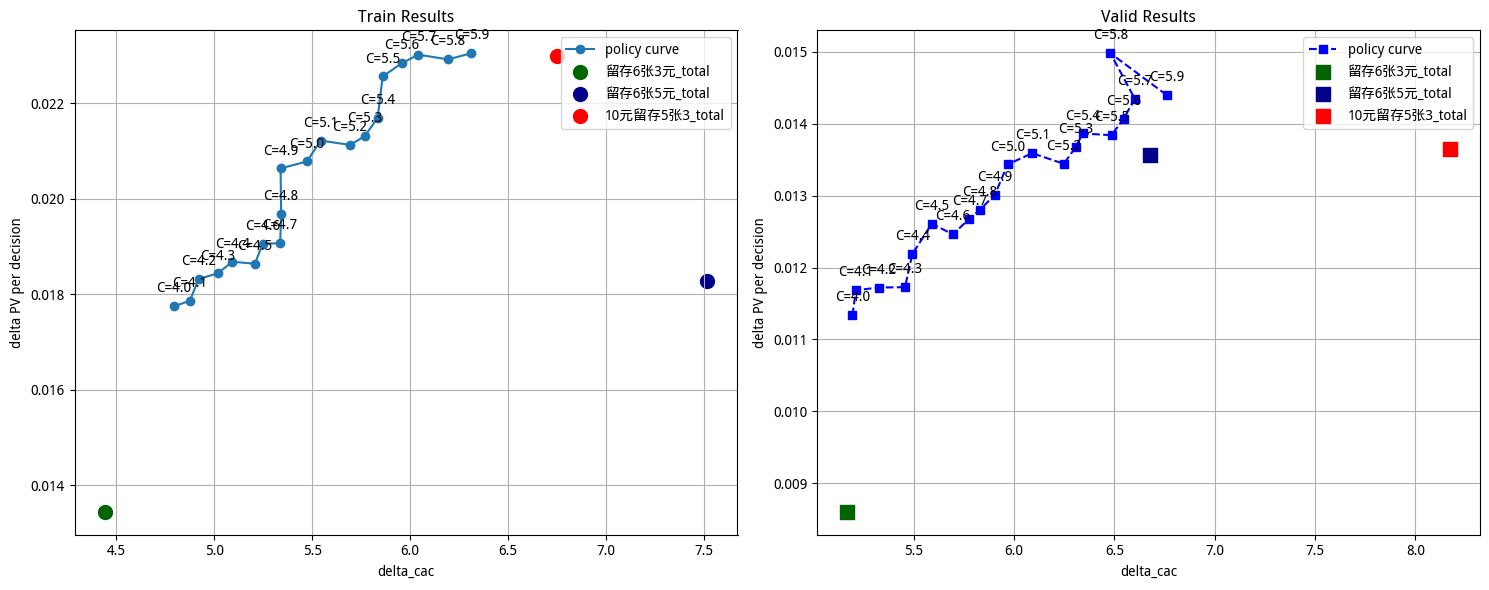

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158343,historical_rct_replay,812972.0,14426.097131,69151.121443,0.017745,4.793474,0,[],17321.293213,69284.793945,3.999978,-0.378906,True,True,0.138478,0.017745,False
1,4.1,0.154925,historical_rct_replay,812972.0,14519.642931,70783.537954,0.017860,4.875019,0,[],17594.812500,72139.255859,4.100030,0.524609,False,False,0.137440,0.017860,False
2,4.2,0.151979,historical_rct_replay,812972.0,14892.422694,73278.735962,0.018318,4.920538,0,[],17866.624634,75039.166016,4.199963,-0.657446,True,True,0.136519,0.018318,False
3,4.3,0.149251,historical_rct_replay,812972.0,14986.386233,75189.758548,0.018434,5.017204,0,[],18137.758667,77992.029297,4.299982,-0.332971,True,True,0.135664,0.018434,False
4,4.4,0.146862,historical_rct_replay,812972.0,15184.610465,77326.776654,0.018678,5.092444,0,[],18408.163086,80994.835938,4.399941,-1.081641,True,True,0.134889,0.018678,False
5,4.5,0.144760,historical_rct_replay,812972.0,15151.307561,78904.890271,0.018637,5.207794,0,[],18678.677734,84054.027344,4.499999,-0.022461,True,True,0.134194,0.018637,False
6,4.6,0.142944,historical_rct_replay,812972.0,15495.218342,81313.145001,0.019060,5.247628,0,[],18949.187500,87165.655273,4.599968,-0.607227,True,True,0.133564,0.019060,False
7,4.7,0.141368,historical_rct_replay,812972.0,15498.134632,82707.711966,0.019064,5.336624,0,[],19220.570312,90336.769531,4.700005,0.089063,False,False,0.132943,0.019064,False
8,4.8,0.139912,historical_rct_replay,812972.0,15996.003009,85448.766570,0.019676,5.341882,0,[],19492.653320,93564.019531,4.799963,-0.716406,True,True,0.132391,0.019676,False
9,4.9,0.138527,historical_rct_replay,812972.0,16773.249812,89545.556836,0.020632,5.338593,0,[],19765.954834,96852.964844,4.899989,-0.213843,True,True,0.131864,0.020632,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.158343,historical_rct_replay,728329.0,8256.628395,42890.820159,0.011336,5.194714,0,[],14644.703857,59058.029785,4.032723,479.214355,False,False,0.158596,0.011336,False
1,4.1,0.154925,historical_rct_replay,728329.0,8509.693109,44357.953262,0.011684,5.212638,0,[],14874.402588,61455.616699,4.131636,470.566089,False,False,0.157460,0.011684,False
2,4.2,0.151979,historical_rct_replay,728329.0,8537.445462,45471.141508,0.011722,5.326083,0,[],15101.472168,63877.816406,4.229907,451.633301,False,False,0.156436,0.011722,False
3,4.3,0.149251,historical_rct_replay,728329.0,8540.848919,46606.990810,0.011727,5.456951,0,[],15335.503540,66426.520508,4.331551,483.855286,False,False,0.155470,0.011727,False
4,4.4,0.146862,historical_rct_replay,728329.0,8876.606837,48762.246860,0.012188,5.493343,0,[],15571.366333,69045.728516,4.434147,531.716650,False,False,0.154544,0.012188,False
5,4.5,0.144760,historical_rct_replay,728329.0,9183.848629,51347.404534,0.012609,5.591055,0,[],15806.172119,71701.353516,4.536288,573.578979,False,False,0.153816,0.012609,False
6,4.6,0.142944,historical_rct_replay,728329.0,9075.670921,51686.686325,0.012461,5.695082,0,[],16043.138184,74427.100586,4.639186,628.664941,False,False,0.153107,0.012461,False
7,4.7,0.141368,historical_rct_replay,728329.0,9233.542782,53349.664661,0.012678,5.777811,0,[],16275.954102,77147.718750,4.739981,650.734473,False,False,0.152494,0.012678,False
8,4.8,0.139912,historical_rct_replay,728329.0,9326.615855,54385.544625,0.012805,5.831220,0,[],16510.566650,79930.441406,4.841169,679.721484,False,False,0.151857,0.012805,False
9,4.9,0.138527,historical_rct_replay,728329.0,9474.165453,55936.274226,0.013008,5.904085,0,[],16739.682129,82687.388672,4.939603,662.946240,False,False,0.151289,0.013008,False


In [90]:
all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21']
val_dt = ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

In [72]:
# 当前指定C下，推荐不发的用户
no_send_df = val_selected.loc[
    val_selected['best_intervention'].eq('C')
].copy()

coupon_actions = [a for a in action_list if a != 'C']
uplift_cols = ['delta_cvr_' + a for a in coupon_actions]

max_uplift = no_send_df[uplift_cols].max(axis=1)

no_send_df['no_send_reason'] = np.select(
    [
        max_uplift.lt(0),
        max_uplift.eq(0),
        max_uplift.gt(0),
    ],
    [
        '所有券uplift均为负',
        '所有券uplift均≤0，至少一张为0',
        '存在正uplift，但成本惩罚使所有券得分为负',
    ],
    default='需检查预测值',
)

reason_summary = (
    no_send_df['no_send_reason']
    .value_counts()
    .rename_axis('reason')
    .rename('count')
    .reset_index()
)
reason_summary['share_of_no_send_pct'] = (
    reason_summary['count'] / len(no_send_df) * 100
    if len(no_send_df) else np.nan
)

display(reason_summary)

,reason,count,share_of_no_send_pct
0,所有券uplift均为负,88293,82.519907
1,存在正uplift，但成本惩罚使所有券得分为负,18703,17.480093


In [71]:
scores = intervention_scores(
    val_selected, optimal_lambda, focus_cost, action_list
)

coupon_cols = [
    'intervention_' + a
    for a in action_list
    if a != 'C'
]
coupon_scores = scores[coupon_cols]

is_no_send = val_selected['best_intervention'].eq('C')
valid_scores = pd.Series(
    np.isfinite(coupon_scores.to_numpy()).all(axis=1),
    index=val_selected.index,
)
all_negative = coupon_scores.lt(0).all(axis=1)
best_coupon_score = coupon_scores.max(axis=1)

reason = pd.Series('其他情况', index=val_selected.index)
reason.loc[~valid_scores] = '存在无效券分数'
reason.loc[valid_scores & all_negative] = '所有券得分均小于0'
reason.loc[valid_scores & best_coupon_score.eq(0)] = '最高券分为0，同分规则选择不发'

no_send_reason = (
    reason.loc[is_no_send]
    .value_counts()
    .rename_axis('reason')
    .rename('count')
    .reset_index()
)

no_send_n = int(is_no_send.sum())
no_send_reason['share_of_no_send_pct'] = (
    no_send_reason['count'] / no_send_n * 100
    if no_send_n else np.nan
)

display(no_send_reason)

,reason,count,share_of_no_send_pct
0,所有券得分均小于0,106996,100.0


In [66]:
all_val_data_pdf_euen_v4.columns

Index(['group_name_eve', 'pid', 'oneid', 'flowtree_group_name', 'send_cnt',
       'send_success_cnt', 'send_cost', 'send_remind_cost', 'outcall_cost',
       'remind_cost', 'coupon_cost', 'outcall_coupon_cost',
       'outcall_coupon2_cost', 'uv_label', 'pv_label', 'uv_label_7d',
       'pv_label_7d', 'cost', 'cost_7d', 'dt', 'fin_order_wxmini_28d',
       'fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v4_final_uplift_1',
       'msg_euen_uplift_cost_26_v4_final_uplift_2',
       'msg_euen_uplift_cost_26_v4_final_uplift_3',
       'msg_euen_uplift_cost_26_v4_final_uplift_4',
       'msg_euen_uplift_cost_26_v4_final_cost_1',
       'msg_euen_uplift_cost_26_v4_final_cost_2',
       'msg_euen_uplift_cost_26_v4_final_cost_3',
       'msg_euen_uplift_cost_26_v4_final_cost_4',
       'msg_euen_uplift_cost_26_v4_final_uplift_diff_2_1',
       'msg_euen_uplift_cost_26_v4_final_uplift_diff_3_1',
       'msg_euen_uplift_cost_26_v4_final_uplift_diff_4_1',
       'msg_euen_uplift_cost_26_v4

26/09/11 07:23:33 ERROR YarnScheduler: Lost executor 30 on bigdata-s2102-hdp1161.nmg03.diditaxi.com: Container killed by YARN for exceeding physical memory limits.  Consider boosting spark.executor.memoryOverhead.


求解日期: ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21'] 验证日期: ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
求解样本: 920809 验证样本: 824900
===== 训练集策略评估 =====
区间内求得λ: 0.1570045387
训练集 - C=4.0: delta_cac=4.8104, delta_finish_pv=0.0177
区间内求得λ: 0.1535666352
训练集 - C=4.1: delta_cac=4.8921, delta_finish_pv=0.0178
区间内求得λ: 0.1506749733
训练集 - C=4.2: delta_cac=4.9153, delta_finish_pv=0.0183
区间内求得λ: 0.1480490138
训练集 - C=4.3: delta_cac=5.0689, delta_finish_pv=0.0182
区间内求得λ: 0.1456968568
训练集 - C=4.4: delta_cac=5.1505, delta_finish_pv=0.0184
区间内求得λ: 0.1436827485
训练集 - C=4.5: delta_cac=5.1868, delta_finish_pv=0.0188
区间内求得λ: 0.1419120441
训练集 - C=4.6: delta_cac=5.2665, delta_finish_pv=0.0191
区间内求得λ: 0.140413245
训练集 - C=4.7: delta_cac=5.3344, delta_finish_pv=0.0193
区间内求得λ: 0.1389900081
训练集 - C=4.8: delta_cac=5.3935, delta_finish_pv=0.0196
区间内求得λ: 0.137616614
训练集 - C=4.9: delta_cac=5.3995, delta_finish_pv=0.0

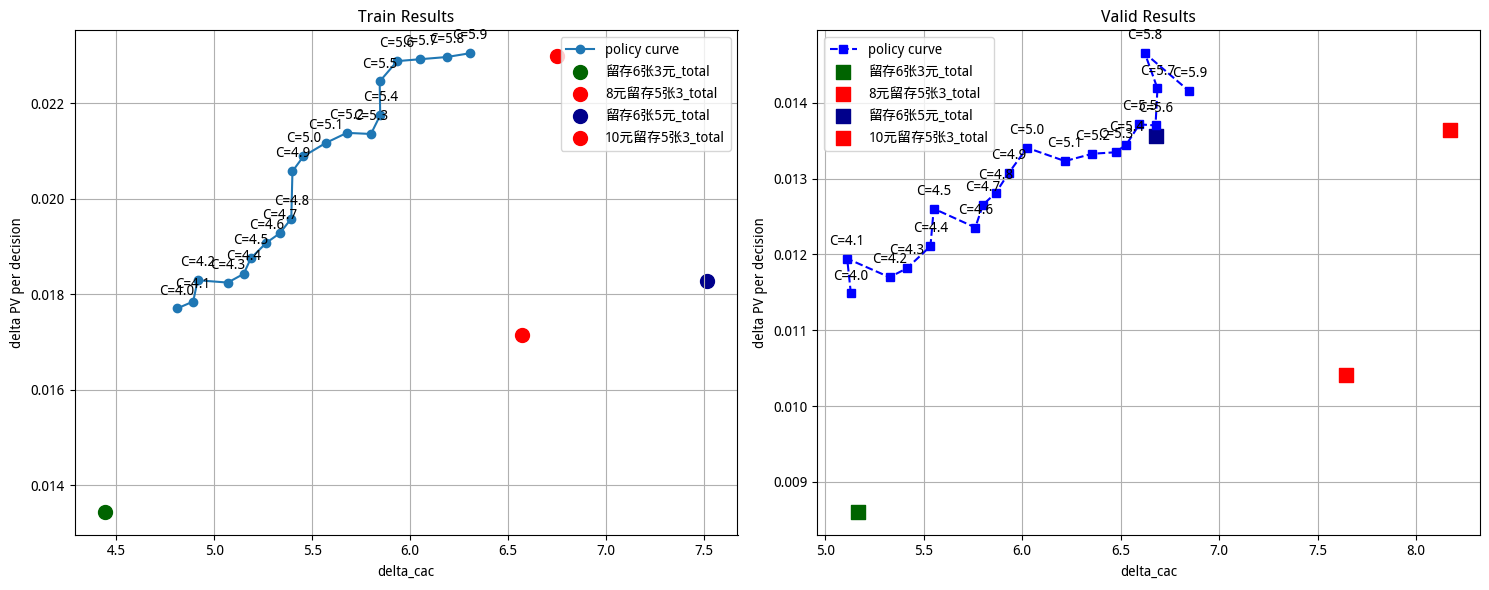

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.157005,historical_rct_replay,920809.0,16302.852708,78423.479230,0.017705,4.810415,0,[],19756.760223,79028.235596,4.000060,1.194702,False,False,0.138000,0.017705,False
1,4.1,0.153567,historical_rct_replay,920809.0,16435.995904,80406.971619,0.017850,4.892127,0,[],20065.415649,82266.585938,4.099919,-1.618225,True,True,0.136957,0.017850,False
2,4.2,0.150675,historical_rct_replay,920809.0,16846.817433,82806.712781,0.018296,4.915273,0,[],20373.142212,85566.929932,4.199987,-0.267358,True,True,0.136061,0.018296,False
3,4.3,0.148049,historical_rct_replay,920809.0,16801.795508,85167.434126,0.018247,5.068948,0,[],20679.521362,88920.864990,4.299948,-1.076868,True,True,0.135209,0.018247,False
4,4.4,0.145697,historical_rct_replay,920809.0,16970.416685,87406.900547,0.018430,5.150545,0,[],20985.531616,92335.873291,4.399978,-0.465820,True,True,0.134460,0.018430,False
5,4.5,0.143683,historical_rct_replay,920809.0,17271.717860,89585.613914,0.018757,5.186839,0,[],21291.248352,95809.442871,4.499945,-1.174713,True,True,0.133779,0.018757,False
6,4.6,0.141912,historical_rct_replay,920809.0,17571.001674,92538.543248,0.019082,5.266549,0,[],21597.879242,99352.149902,4.600088,1.905389,False,False,0.133185,0.019082,False
7,4.7,0.140413,historical_rct_replay,920809.0,17752.626164,94700.047297,0.019279,5.334425,0,[],21904.761078,102953.017822,4.700029,0.640756,False,False,0.132586,0.019279,False
8,4.8,0.138990,historical_rct_replay,920809.0,18035.663924,97274.708776,0.019587,5.393464,0,[],22212.945831,106622.898193,4.800034,0.758203,False,False,0.132027,0.019587,False
9,4.9,0.137617,historical_rct_replay,920809.0,18949.358547,102316.504423,0.020579,5.399471,0,[],22522.141907,110357.838623,4.899971,-0.656720,True,True,0.131506,0.020579,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.157005,historical_rct_replay,824900.0,9474.702087,48606.013336,0.011486,5.130084,0,[],16708.503906,67449.053467,4.036810,615.037842,False,False,0.158257,0.011486,False
1,4.1,0.153567,historical_rct_replay,824900.0,9853.572579,50363.399415,0.011945,5.111182,0,[],16973.208069,70226.488281,4.137491,636.335199,False,False,0.157093,0.011945,False
2,4.2,0.150675,historical_rct_replay,824900.0,9651.303474,51405.187564,0.011700,5.326243,0,[],17227.285889,72951.551758,4.234651,596.951025,False,False,0.156093,0.011700,False
3,4.3,0.148049,historical_rct_replay,824900.0,9748.228300,52784.280008,0.011817,5.414756,0,[],17493.092072,75861.246094,4.336640,640.950186,False,False,0.155149,0.011817,False
4,4.4,0.145697,historical_rct_replay,824900.0,9989.039336,55280.405798,0.012109,5.534106,0,[],17762.416687,78866.698975,4.440088,712.065552,False,False,0.154278,0.012109,False
5,4.5,0.143683,historical_rct_replay,824900.0,10397.451771,57715.826386,0.012604,5.550959,0,[],18031.944855,81929.315918,4.543565,785.564072,False,False,0.153563,0.012604,False
6,4.6,0.141912,historical_rct_replay,824900.0,10192.378893,58727.533404,0.012356,5.761906,0,[],18298.405975,85008.016113,4.645651,835.348627,False,False,0.152867,0.012356,False
7,4.7,0.140413,historical_rct_replay,824900.0,10440.402173,60566.630735,0.012657,5.801178,0,[],18560.862885,88087.840332,4.745891,851.784775,False,False,0.152250,0.012657,False
8,4.8,0.138990,historical_rct_replay,824900.0,10567.998084,61984.466413,0.012811,5.865299,0,[],18825.016510,91233.425537,4.846393,873.346289,False,False,0.151626,0.012811,False
9,4.9,0.137617,historical_rct_replay,824900.0,10786.288423,63985.700982,0.013076,5.932133,0,[],19083.133331,94351.813721,4.944252,844.460397,False,False,0.151068,0.013076,False


In [34]:
all_val_data_pdf_euen_v4 = all_rct_data_pdf_v4.copy()
prefix = 'msg_euen_uplift_cost_26_v4_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_853': 2, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_853', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen_v4['delta_cvr_' + action] = all_val_data_pdf_euen_v4[prefix + f'uplift_{head}']
    all_val_data_pdf_euen_v4['cost_' + action] = all_val_data_pdf_euen_v4[prefix + f'cost_{head}']
all_val_data_pdf_euen_v4['finish_cnt_7d'] = all_val_data_pdf_euen_v4['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白', 'left_853':'8元留存5张3', 'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21']
val_dt = ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
all_val_data_pdf_euen_v4_use = all_val_data_pdf_euen_v4[all_val_data_pdf_euen_v4['group_name_eve'].isin(['留存6张3元', '留存6张5元', '8元留存5张3', 'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_v4_use[all_val_data_pdf_euen_v4_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

## 26_V3

### 新时间段

求解日期: ['2026-08-12', '2026-08-13', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19'] 验证日期: ['2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26']
求解样本: 809587 验证样本: 792415
求解集 - C=4, λ=0.1611323024: delta_cac=5.0210, delta_pv_per_user=0.0182
验证集 - C=4, λ=0.1611323024: delta_cac=5.9022, delta_pv_per_user=0.0137
求解集 - C=4.1, λ=0.1554472062: delta_cac=5.0936, delta_pv_per_user=0.0185
验证集 - C=4.1, λ=0.1554472062: delta_cac=6.0798, delta_pv_per_user=0.0139
求解集 - C=4.2, λ=0.150177179: delta_cac=5.2043, delta_pv_per_user=0.0187
验证集 - C=4.2, λ=0.150177179: delta_cac=6.3208, delta_pv_per_user=0.0139
求解集 - C=4.3, λ=0.1451614004: delta_cac=5.2576, delta_pv_per_user=0.0193
验证集 - C=4.3, λ=0.1451614004: delta_cac=6.5271, delta_pv_per_user=0.0139
求解集 - C=4.4, λ=0.1400232195: delta_cac=5.3967, delta_pv_per_user=0.0195
验证集 - C=4.4, λ=0.1400232195: delta_cac=6.6382, delta_pv_per_user=0.0141
求解集 - C=4.5, λ=0.1341314666: delta_cac=5.5042, del

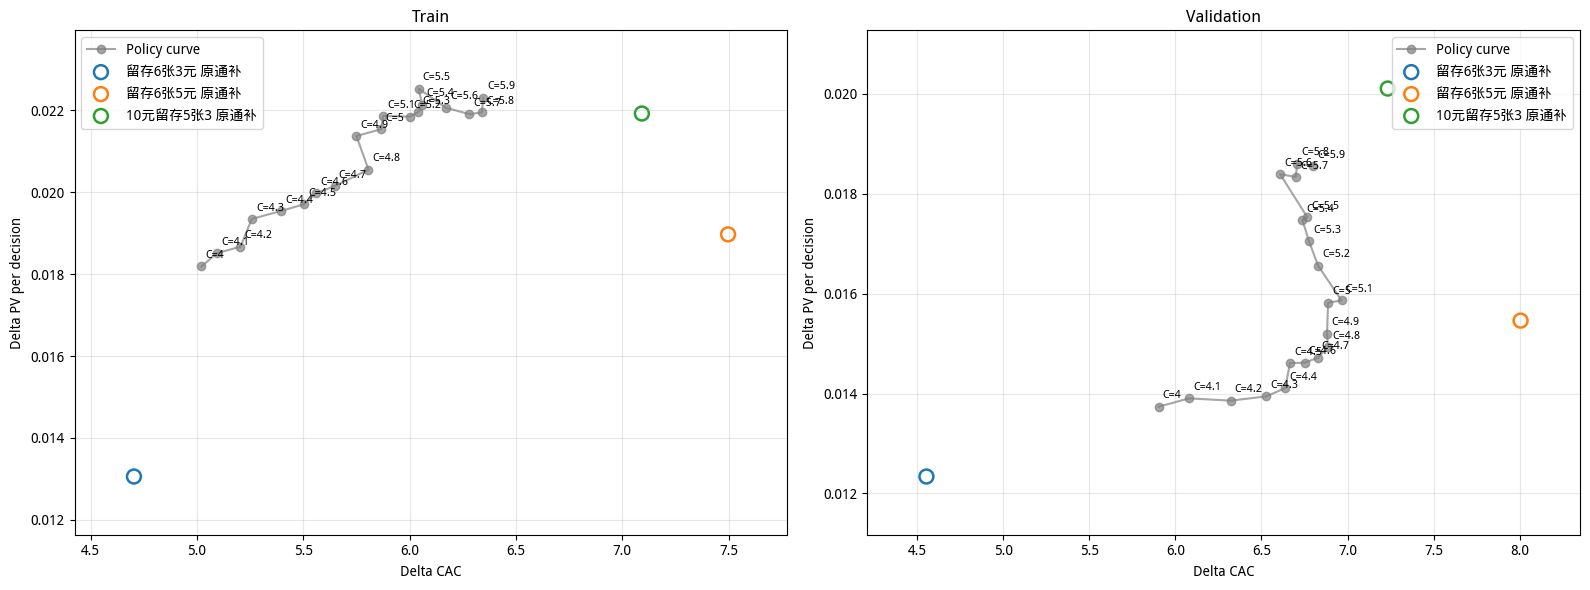

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161132,historical_rct_replay,809587.0,14722.946419,73924.372520,0.018186,5.021031,0,[],22104.144043,88417.279297,4.000032,0.703125,False,False,0.420764,0.018186,False
1,4.1,0.155447,historical_rct_replay,809587.0,14986.298652,76334.251273,0.018511,5.093603,0,[],22456.676758,92072.865234,4.100022,0.490527,False,False,0.415734,0.018511,False
2,4.2,0.150177,historical_rct_replay,809587.0,15112.810920,78651.043267,0.018667,5.204263,0,[],22802.233398,95769.064453,4.199986,-0.315820,True,True,0.411010,0.018667,False
3,4.3,0.145161,historical_rct_replay,809587.0,15662.625038,82347.809435,0.019346,5.257599,0,[],23141.729492,99510.859375,4.300061,1.422559,False,False,0.406518,0.019346,False
4,4.4,0.140023,historical_rct_replay,809587.0,15821.206312,85381.759958,0.019542,5.396666,0,[],23473.810547,103283.523438,4.399947,-1.242969,True,True,0.402247,0.019542,False
5,4.5,0.134131,historical_rct_replay,809587.0,15953.490613,87810.430741,0.019706,5.504152,0,[],23798.375000,107094.082031,4.500059,1.394531,False,False,0.397387,0.019706,False
6,4.6,0.126897,historical_rct_replay,809587.0,16171.232594,89901.232172,0.019975,5.559331,0,[],24111.185547,110911.865234,4.600017,0.411719,False,False,0.391821,0.019975,False
7,4.7,0.117872,historical_rct_replay,809587.0,16310.606556,92099.007886,0.020147,5.646572,0,[],24408.263428,114718.621094,4.699991,-0.217017,True,True,0.384799,0.020147,False
8,4.8,0.107658,historical_rct_replay,809587.0,16635.750643,96593.535060,0.020548,5.806383,0,[],24685.326416,118489.582031,4.800001,0.015234,False,False,0.376620,0.020548,False
9,4.9,0.097233,historical_rct_replay,809587.0,17301.422775,99478.268882,0.021371,5.749716,0,[],24939.446045,122202.481445,4.899968,-0.804175,True,True,0.367941,0.021371,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161132,historical_rct_replay,792415.0,10884.453379,64242.367485,0.013736,5.902213,0,[],21631.380859,86303.966797,3.989758,-221.556641,True,True,0.420902,0.013736,False
1,4.1,0.155447,historical_rct_replay,792415.0,11017.725609,66985.025427,0.013904,6.079751,0,[],21979.754883,89916.878906,4.090895,-200.116113,True,True,0.416052,0.013904,False
2,4.2,0.150177,historical_rct_replay,792415.0,10980.995915,69409.104536,0.013858,6.320839,0,[],22332.670410,93691.466797,4.195265,-105.748926,True,True,0.411483,0.013858,False
3,4.3,0.145161,historical_rct_replay,792415.0,11048.812964,72117.044899,0.013943,6.527131,0,[],22671.796875,97429.005859,4.297366,-59.720703,True,True,0.407173,0.013943,False
4,4.4,0.140023,historical_rct_replay,792415.0,11179.735517,74213.192136,0.014108,6.638189,0,[],23004.773438,101211.601562,4.399591,-9.401563,True,True,0.402839,0.014108,False
5,4.5,0.134131,historical_rct_replay,792415.0,11579.373296,77187.100204,0.014613,6.665913,0,[],23328.952148,105017.304688,4.501587,37.020020,False,False,0.398060,0.014613,False
6,4.6,0.126897,historical_rct_replay,792415.0,11582.161152,78187.011844,0.014616,6.750641,0,[],23634.659668,108748.109375,4.601213,28.674902,False,False,0.392374,0.014616,False
7,4.7,0.117872,historical_rct_replay,792415.0,11660.908931,79597.305905,0.014716,6.825995,0,[],23926.080566,112481.873047,4.701224,29.294385,False,False,0.385289,0.014716,False
8,4.8,0.107658,historical_rct_replay,792415.0,11826.562806,81435.555552,0.014925,6.885818,0,[],24194.220215,116132.007812,4.799990,-0.249219,True,True,0.377210,0.014925,False
9,4.9,0.097233,historical_rct_replay,792415.0,12046.203067,82893.085970,0.015202,6.881263,0,[],24442.410400,119758.215820,4.899607,-9.595142,True,True,0.368595,0.015202,False


In [97]:
all_val_data_pdf_euen = all_rct_data_pdf_v3.copy()
prefix = 'msg_euen_uplift_cost_26_v3_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen['delta_cvr_' + action] = all_val_data_pdf_euen[prefix + f'uplift_{head}']
    all_val_data_pdf_euen['cost_' + action] = all_val_data_pdf_euen[prefix + f'cost_{head}']
all_val_data_pdf_euen['finish_cnt_7d'] = all_val_data_pdf_euen['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-12','2026-08-13','2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19']
val_dt = ['2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26']

all_val_data_pdf_euen_use = all_val_data_pdf_euen[all_val_data_pdf_euen['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

求解日期: ['2026-08-12', '2026-08-13', '2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19'] 验证日期: ['2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26']
求解样本: 917515 验证样本: 897284
求解集 - C=4, λ=0.1615609406: delta_cac=5.0458, delta_pv_per_user=0.0181
验证集 - C=4, λ=0.1615609406: delta_cac=5.9510, delta_pv_per_user=0.0137
求解集 - C=4.1, λ=0.1557965541: delta_cac=5.0938, delta_pv_per_user=0.0185
验证集 - C=4.1, λ=0.1557965541: delta_cac=6.0607, delta_pv_per_user=0.0140
求解集 - C=4.2, λ=0.1503853559: delta_cac=5.2274, delta_pv_per_user=0.0186
验证集 - C=4.2, λ=0.1503853559: delta_cac=6.3015, delta_pv_per_user=0.0140
求解集 - C=4.3, λ=0.1452894279: delta_cac=5.2322, delta_pv_per_user=0.0195
验证集 - C=4.3, λ=0.1452894279: delta_cac=6.5120, delta_pv_per_user=0.0140
求解集 - C=4.4, λ=0.1400451228: delta_cac=5.3891, delta_pv_per_user=0.0197
验证集 - C=4.4, λ=0.1400451228: delta_cac=6.6212, delta_pv_per_user=0.0142
求解集 - C=4.5, λ=0.1340918253: delta_cac=5.4908, d

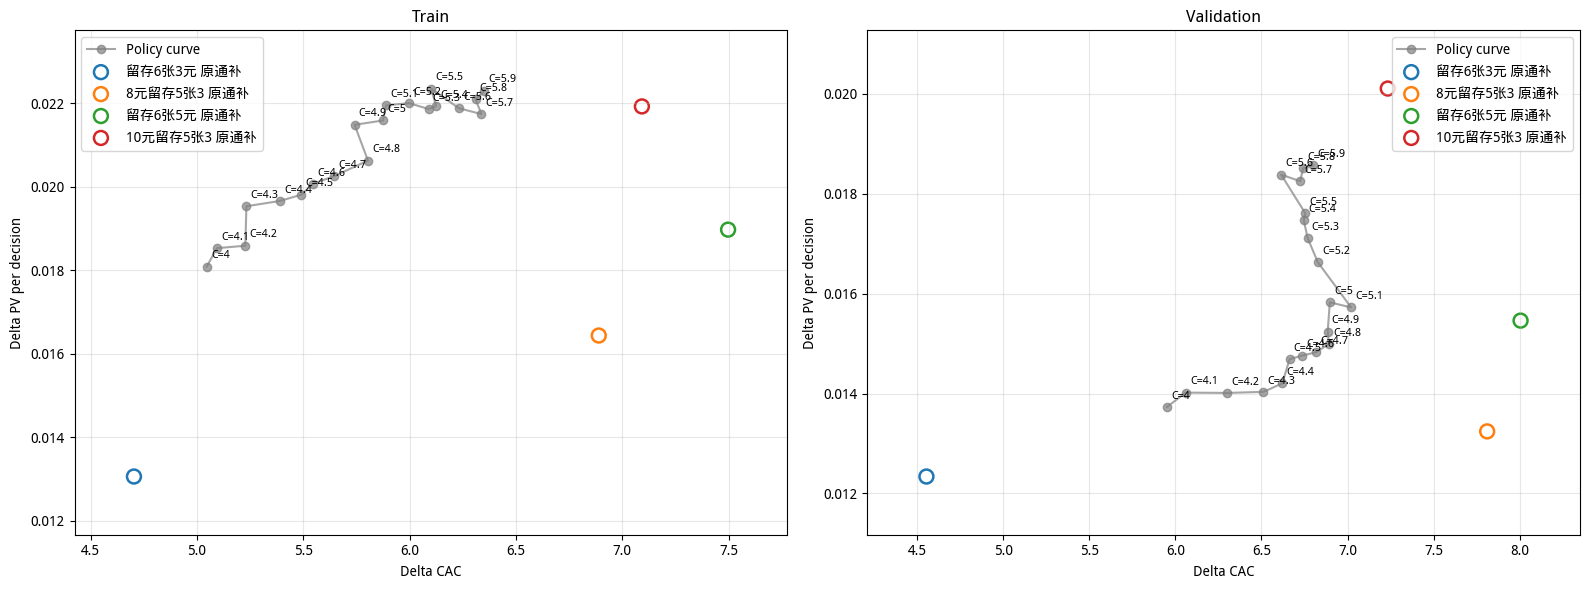

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161561,historical_rct_replay,917515.0,16592.954975,83725.546470,0.018085,5.045849,0,[],25163.906433,100656.228210,4.000024,0.602478,False,False,0.421134,0.018085,False
1,4.1,0.155797,historical_rct_replay,917515.0,16997.691219,86582.177492,0.018526,5.093761,0,[],25566.176971,104821.239624,4.099997,-0.085959,True,True,0.416103,0.018526,False
2,4.2,0.150385,historical_rct_replay,917515.0,17051.529547,89135.142402,0.018584,5.227399,0,[],25960.410004,109033.324219,4.199985,-0.397797,True,True,0.411324,0.018584,False
3,4.3,0.145289,historical_rct_replay,917515.0,17918.766062,93754.844821,0.019530,5.232215,0,[],26347.290039,113294.385010,4.300039,1.037842,False,False,0.406812,0.019530,False
4,4.4,0.140045,historical_rct_replay,917515.0,18033.918919,97185.727370,0.019655,5.389052,0,[],26725.842346,117593.420654,4.399989,-0.285669,True,True,0.402482,0.019655,False
5,4.5,0.134092,historical_rct_replay,917515.0,18171.816958,99778.216126,0.019805,5.490822,0,[],27094.928711,121927.009521,4.499994,-0.169678,True,True,0.397601,0.019805,False
6,4.6,0.126750,historical_rct_replay,917515.0,18410.114068,102086.205801,0.020065,5.545115,0,[],27450.931152,126273.804321,4.599983,-0.478979,True,True,0.391924,0.020065,False
7,4.7,0.117643,historical_rct_replay,917515.0,18583.209758,104925.184014,0.020254,5.646236,0,[],27788.838806,130607.417603,4.699996,-0.124786,True,True,0.384816,0.020254,False
8,4.8,0.107381,historical_rct_replay,917515.0,18921.734080,109822.299225,0.020623,5.804029,0,[],28103.526794,134896.947754,4.800001,0.019141,False,False,0.376570,0.020623,False
9,4.9,0.096933,historical_rct_replay,917515.0,19707.679102,113139.404656,0.021479,5.740879,0,[],28392.146362,139121.812988,4.900010,0.295813,False,False,0.367828,0.021479,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161561,historical_rct_replay,897284.0,12320.892940,73322.134092,0.013731,5.951041,0,[],24572.508560,98086.392822,3.991713,-203.641418,True,True,0.421625,0.013731,False
1,4.1,0.155797,historical_rct_replay,897284.0,12579.154763,76238.669640,0.014019,6.060715,0,[],24970.132416,102203.833252,4.093043,-173.709653,True,True,0.416686,0.014019,False
2,4.2,0.150385,historical_rct_replay,897284.0,12573.350550,79231.002183,0.014013,6.301503,0,[],25366.682129,106440.202148,4.196063,-99.862793,True,True,0.412061,0.014013,False
3,4.3,0.145289,historical_rct_replay,897284.0,12592.571422,82002.405447,0.014034,6.511967,0,[],25750.630432,110668.829346,4.297713,-58.881512,True,True,0.407715,0.014034,False
4,4.4,0.140045,historical_rct_replay,897284.0,12745.266647,84389.326528,0.014204,6.621229,0,[],26127.943604,114953.950073,4.399655,-9.001782,True,True,0.403317,0.014204,False
5,4.5,0.134092,historical_rct_replay,897284.0,13177.644431,87807.040905,0.014686,6.663334,0,[],26493.396362,119244.378418,4.500909,24.094788,False,False,0.398520,0.014686,False
6,4.6,0.126750,historical_rct_replay,897284.0,13242.480004,89179.912432,0.014758,6.734382,0,[],26840.953552,123488.040527,4.600732,19.654187,False,False,0.392771,0.014758,False
7,4.7,0.117643,historical_rct_replay,897284.0,13303.532729,90684.223750,0.014826,6.816552,0,[],27170.378845,127712.470581,4.700430,11.690009,False,False,0.385604,0.014826,False
8,4.8,0.107381,historical_rct_replay,897284.0,13449.305636,92688.343738,0.014989,6.891682,0,[],27474.704468,131861.300537,4.799371,-17.280908,True,True,0.377517,0.014989,False
9,4.9,0.096933,historical_rct_replay,897284.0,13676.076236,94159.178265,0.015242,6.884956,0,[],27755.402283,135970.293701,4.898877,-31.177484,True,True,0.368824,0.015242,False


In [94]:
all_val_data_pdf_euen = all_rct_data_pdf_v3.copy()
prefix = 'msg_euen_uplift_cost_26_v3_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_853': 2, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_853', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen['delta_cvr_' + action] = all_val_data_pdf_euen[prefix + f'uplift_{head}']
    all_val_data_pdf_euen['cost_' + action] = all_val_data_pdf_euen[prefix + f'cost_{head}']
all_val_data_pdf_euen['finish_cnt_7d'] = all_val_data_pdf_euen['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_853': '8元留存5张3', 'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-12','2026-08-13','2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19']
val_dt = ['2026-08-20', '2026-08-21','2026-08-22', '2026-08-23', '2026-08-24', '2026-08-25', '2026-08-26']

all_val_data_pdf_euen_use = all_val_data_pdf_euen[all_val_data_pdf_euen['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白','8元留存5张3','10元留存5张3'])]
train_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

求解日期: ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21'] 验证日期: ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
求解样本: 920809 验证样本: 824900
===== 训练集策略评估 =====
区间内求得λ: 0.161152444
训练集 - C=4.0: delta_cac=4.9536, delta_finish_pv=0.0188
区间内求得λ: 0.1554566614
训练集 - C=4.1: delta_cac=5.0254, delta_finish_pv=0.0193
区间内求得λ: 0.1501410349
训练集 - C=4.2: delta_cac=5.1792, delta_finish_pv=0.0190
区间内求得λ: 0.1451121902
训练集 - C=4.3: delta_cac=5.2944, delta_finish_pv=0.0193
区间内求得λ: 0.1399557069
训练集 - C=4.4: delta_cac=5.4804, delta_finish_pv=0.0193
区间内求得λ: 0.1339470912
训练集 - C=4.5: delta_cac=5.5919, delta_finish_pv=0.0193
区间内求得λ: 0.1265865709
训练集 - C=4.6: delta_cac=5.6750, delta_finish_pv=0.0192
区间内求得λ: 0.1173811597
训练集 - C=4.7: delta_cac=5.7857, delta_finish_pv=0.0194
区间内求得λ: 0.1068938512
训练集 - C=4.8: delta_cac=5.9006, delta_finish_pv=0.0197
区间内求得λ: 0.09625849105
训练集 - C=4.9: delta_cac=5.8611, delta_finish_pv=0

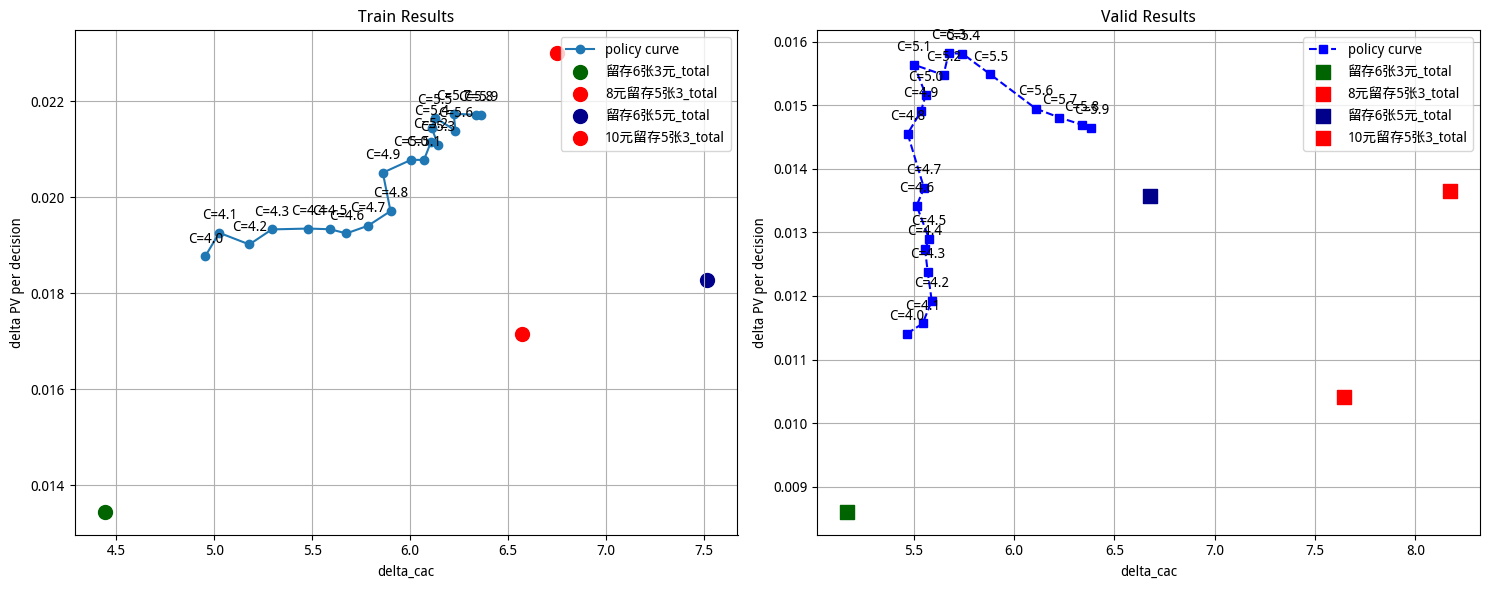

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161152,historical_rct_replay,920809.0,17277.438469,85585.211819,0.018763,4.953582,0,[],25590.460327,102362.558716,4.000028,0.717407,False,False,0.418624,0.018763,False
1,4.1,0.155457,historical_rct_replay,920809.0,17730.682818,89103.078600,0.019256,5.025361,0,[],25998.598511,106594.366455,4.100004,0.112561,False,False,0.413698,0.019256,False
2,4.2,0.150141,historical_rct_replay,920809.0,17506.576893,90669.265918,0.019012,5.179154,0,[],26398.747253,110874.752563,4.200001,0.014099,False,False,0.408983,0.019012,False
3,4.3,0.145112,historical_rct_replay,920809.0,17795.412397,94216.346674,0.019326,5.294418,0,[],26791.422363,115203.083984,4.299999,-0.032178,True,True,0.404642,0.019326,False
4,4.4,0.139956,historical_rct_replay,920809.0,17811.638014,97615.596907,0.019343,5.480439,0,[],27175.976318,119572.879395,4.399948,-1.416406,True,True,0.400360,0.019343,False
5,4.5,0.133947,historical_rct_replay,920809.0,17798.468627,99527.759481,0.019329,5.591928,0,[],27551.189941,123980.543945,4.500007,0.189209,False,False,0.395536,0.019329,False
6,4.6,0.126587,historical_rct_replay,920809.0,17718.875806,100554.947684,0.019243,5.675018,0,[],27912.761841,128398.787476,4.600003,0.083008,False,False,0.389898,0.019243,False
7,4.7,0.117381,historical_rct_replay,920809.0,17865.924795,103367.606035,0.019402,5.785741,0,[],28255.888489,132804.364746,4.700060,1.688849,False,False,0.382684,0.019402,False
8,4.8,0.106894,historical_rct_replay,920809.0,18146.790546,107076.165293,0.019707,5.900557,0,[],28574.586456,137158.297363,4.800010,0.282373,False,False,0.374287,0.019707,False
9,4.9,0.096258,historical_rct_replay,920809.0,18883.055371,110676.300008,0.020507,5.861144,0,[],28866.428040,141445.949097,4.900016,0.451703,False,False,0.365310,0.020507,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.161152,historical_rct_replay,824900.0,9407.972510,51427.553737,0.011405,5.466380,0,[],21304.438766,85374.075562,4.007337,156.320496,False,False,0.432666,0.011405,False
1,4.1,0.155457,historical_rct_replay,824900.0,9541.758133,52908.000505,0.011567,5.544890,0,[],21633.744217,88788.726196,4.104177,90.374907,False,False,0.427754,0.011567,False
2,4.2,0.150141,historical_rct_replay,824900.0,9835.403723,54982.213329,0.011923,5.590235,0,[],21959.005112,92267.283020,4.201797,39.461551,False,False,0.423101,0.011923,False
3,4.3,0.145112,historical_rct_replay,824900.0,10206.246949,56850.921624,0.012373,5.570208,0,[],22272.785675,95725.963867,4.297889,-47.014536,True,True,0.418715,0.012373,False
4,4.4,0.139956,historical_rct_replay,824900.0,10507.834035,58389.342996,0.012738,5.556744,0,[],22587.823914,99306.232666,4.396450,-80.192554,True,True,0.414347,0.012738,False
5,4.5,0.133947,historical_rct_replay,824900.0,10637.625085,59328.067539,0.012896,5.577191,0,[],22894.938782,102914.460693,4.495075,-112.763824,True,True,0.409539,0.012896,False
6,4.6,0.126587,historical_rct_replay,824900.0,11071.245902,61056.542287,0.013421,5.514875,0,[],23197.740921,106614.487488,4.595900,-95.120749,True,True,0.403771,0.013421,False
7,4.7,0.117381,historical_rct_replay,824900.0,11297.513366,62720.929876,0.013696,5.551746,0,[],23493.894913,110417.049927,4.699819,-4.256163,True,True,0.396583,0.013696,False
8,4.8,0.106894,historical_rct_replay,824900.0,12003.558752,65660.676609,0.014552,5.470101,0,[],23776.033981,114272.812744,4.806218,147.849634,False,False,0.388079,0.014552,False
9,4.9,0.096258,historical_rct_replay,824900.0,12294.206487,68064.105685,0.014904,5.536275,0,[],24033.852966,118062.367798,4.912336,296.488263,False,False,0.378913,0.014904,False


In [40]:
all_val_data_pdf_euen = all_rct_data_pdf_v3.copy()
prefix = 'msg_euen_uplift_cost_26_v3_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_853': 2, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_853', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen['delta_cvr_' + action] = all_val_data_pdf_euen[prefix + f'uplift_{head}']
    all_val_data_pdf_euen['cost_' + action] = all_val_data_pdf_euen[prefix + f'cost_{head}']
all_val_data_pdf_euen['finish_cnt_7d'] = all_val_data_pdf_euen['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白',  'left_853': '8元留存5张3', 'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21']
val_dt = ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']

all_val_data_pdf_euen_use = all_val_data_pdf_euen[all_val_data_pdf_euen['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白','8元留存5张3','10元留存5张3'])]
train_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

In [46]:
train_tongbu_points

{'留存6张3元': (4.439962295508831, 0.01344288570061079),
 '8元留存5张3': (6.571969243761788, 0.017148904187503224),
 '留存6张5元': (7.519399456989196, 0.018278536753708535),
 '10元留存5张3': (6.75147913145074, 0.022995429987490722)}

In [57]:
focus_cost = 5.6
optimal_lambda = next(r['optimal_lambda'] for r in train_results if r['cost_setting'] == focus_cost)
val_metrics, val_replay_detail, val_selected = apply_lambda_strategy(
    val_df, optimal_lambda, focus_cost, dict_coupon, control_name, action_list, return_details=True)
display(pd.DataFrame([val_metrics]))
display(val_replay_detail)
# 推荐占比按全部验证样本计算，与历史实际RCT分组占比不同。
action_share_df = (
    val_selected['best_intervention'].value_counts()
    .reindex(action_list, fill_value=0)
    .rename_axis('action').rename('count').reset_index()
)
action_share_df['coupon'] = action_share_df['action'].map(dict_coupon)
total_n = len(val_selected)
send_n = int(action_share_df.loc[action_share_df.action != 'C', 'count'].sum())
action_share_df['share_all_pct'] = action_share_df['count'] / total_n * 100 if total_n else np.nan
action_share_df['share_sent_pct'] = np.nan
if send_n:
    mask = action_share_df.action != 'C'
    action_share_df.loc[mask, 'share_sent_pct'] = action_share_df.loc[mask, 'count'] / send_n * 100
action_share_df['cost_setting'] = focus_cost
action_share_df['optimal_lambda'] = optimal_lambda
action_share_df = action_share_df[['cost_setting', 'optimal_lambda', 'action', 'coupon',
                                 'count', 'share_all_pct', 'share_sent_pct']]
print(f'验证集推荐占比：C={focus_cost:g}，λ={optimal_lambda:.10g}，总样本={total_n}，发券样本={send_n}')
display(action_share_df.round({'share_all_pct': 2, 'share_sent_pct': 2}))

,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share
0,historical_rct_replay,824900.0,12329.361254,75316.578171,0.014946,6.108717,0,[],25183.323822,142682.72583,5.665762,1656.112427,False,False,0.30268


,action,n,n_t,n_c,supported,zoom_delta_pv,zoom_delta_cost
0,C,249681.0,122285,122285,True,0.000000,0.000000
1,left_1053,286044.0,33150,143427,True,5687.046757,35595.237701
2,left_63,78962.0,13628,39646,True,193.563231,1866.801202
3,left_65,209682.0,19670,103077,True,6486.468284,37823.839883
4,left_853,531.0,70,251,True,-37.717018,30.699386


验证集推荐占比：C=5.6，λ=0.02909045832，总样本=824900，发券样本=575219


,cost_setting,optimal_lambda,action,coupon,count,share_all_pct,share_sent_pct
0,5.6,0.02909,left_63,留存6张3元,78962,9.57,13.73
1,5.6,0.02909,C,DS空白,249681,30.27,NaN
2,5.6,0.02909,left_853,8元留存5张3,531,0.06,0.09
3,5.6,0.02909,left_65,留存6张5元,209682,25.42,36.45
4,5.6,0.02909,left_1053,10元留存5张3,286044,34.68,49.73


In [58]:
train_result = next(
    r for r in train_results
    if r['cost_setting'] == focus_cost
)
display(pd.DataFrame([train_result]))

,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,5.6,0.02909,historical_rct_replay,920809.0,19690.220976,122719.007088,0.021384,6.232485,0,[],30149.904694,168838.65271,5.599973,-0.813574,True,True,0.289495,0.021384,False


求解日期: ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21'] 验证日期: ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']
求解样本: 812972 验证样本: 728329
===== 训练集策略评估 =====
区间内求得λ: 0.1606658809
训练集 - C=4.0: delta_cac=4.9066, delta_finish_pv=0.0190
区间内求得λ: 0.155059829
训练集 - C=4.1: delta_cac=5.0145, delta_finish_pv=0.0193
区间内求得λ: 0.1499202732
训练集 - C=4.2: delta_cac=5.1613, delta_finish_pv=0.0190
区间内求得λ: 0.1449984613
训练集 - C=4.3: delta_cac=5.3011, delta_finish_pv=0.0192
区间内求得λ: 0.1399345239
训练集 - C=4.4: delta_cac=5.4886, delta_finish_pv=0.0192
区间内求得λ: 0.1340319237
训练集 - C=4.5: delta_cac=5.6123, delta_finish_pv=0.0192
区间内求得λ: 0.1267770111
训练集 - C=4.6: delta_cac=5.6879, delta_finish_pv=0.0192
区间内求得λ: 0.1176399515
训练集 - C=4.7: delta_cac=5.7999, delta_finish_pv=0.0193
区间内求得λ: 0.107196456
训练集 - C=4.8: delta_cac=5.9230, delta_finish_pv=0.0195
区间内求得λ: 0.09660766958
训练集 - C=4.9: delta_cac=5.8713, delta_finish_pv=0.

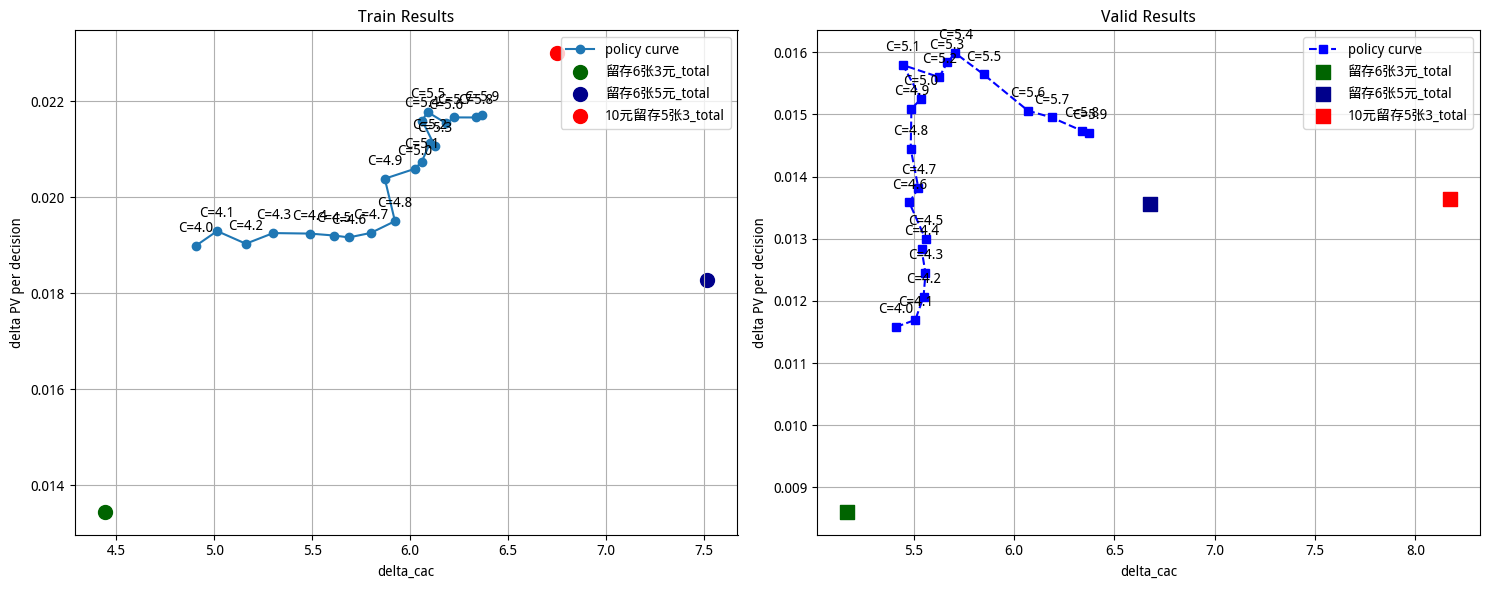

求解集：λ与RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.160666,historical_rct_replay,812972.0,15436.421216,75740.201947,0.018988,4.906591,0,[],22494.490234,89977.878906,3.999996,-0.082031,True,True,0.418054,0.018988,False
1,4.1,0.155060,historical_rct_replay,812972.0,15683.342760,78643.950733,0.019291,5.014489,0,[],22852.356934,93694.904297,4.100011,0.240869,False,False,0.413184,0.019291,False
2,4.2,0.149920,historical_rct_replay,812972.0,15468.717437,79838.351945,0.019027,5.161278,0,[],23203.415039,97454.609375,4.200011,0.266211,False,False,0.408523,0.019027,False
3,4.3,0.144998,historical_rct_replay,812972.0,15649.346030,82959.472371,0.019250,5.301146,0,[],23548.274902,101258.654297,4.300046,1.072217,False,False,0.404208,0.019250,False
4,4.4,0.139935,historical_rct_replay,812972.0,15640.660085,85844.555486,0.019239,5.488551,0,[],23886.170898,105099.316406,4.400007,0.164453,False,False,0.399989,0.019239,False
5,4.5,0.134032,historical_rct_replay,812972.0,15607.725241,87594.961755,0.019198,5.612282,0,[],24215.625000,108968.689453,4.499933,-1.623047,True,True,0.395207,0.019198,False
6,4.6,0.126777,historical_rct_replay,812972.0,15575.842213,88593.793289,0.019159,5.687897,0,[],24533.896484,112855.218750,4.599971,-0.705078,True,True,0.389722,0.019159,False
7,4.7,0.117640,historical_rct_replay,812972.0,15651.868272,90779.600868,0.019253,5.799921,0,[],24835.959961,116729.349609,4.700014,0.337793,False,False,0.382606,0.019253,False
8,4.8,0.107196,historical_rct_replay,812972.0,15851.154932,93886.677678,0.019498,5.923018,0,[],25116.989990,120561.837891,4.800011,0.285938,False,False,0.374224,0.019498,False
9,4.9,0.096608,historical_rct_replay,812972.0,16570.386542,97289.103902,0.020382,5.871263,0,[],25374.361328,124334.793945,4.900017,0.423437,False,False,0.365337,0.020382,False


验证集：冻结λ后的RCT回放


,cost_setting,optimal_lambda,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share,delta_finish_pv,lambda_at_boundary
0,4.0,0.160666,historical_rct_replay,728329.0,8433.391624,45637.695438,0.011579,5.411547,0,[],18773.783203,75268.220703,4.009220,173.087891,False,False,0.431768,0.011579,False
1,4.1,0.155060,historical_rct_replay,728329.0,8517.567896,46916.870724,0.011695,5.508247,0,[],19065.690918,78300.162109,4.106862,130.829346,False,False,0.426938,0.011695,False
2,4.2,0.149920,historical_rct_replay,728329.0,8785.469650,48752.640272,0.012063,5.549236,0,[],19347.929199,81322.505859,4.203163,61.203223,False,False,0.422387,0.012063,False
3,4.3,0.144998,historical_rct_replay,728329.0,9062.634596,50379.400355,0.012443,5.559024,0,[],19624.881348,84377.357422,4.299509,-9.632373,True,True,0.418067,0.012443,False
4,4.4,0.139935,historical_rct_replay,728329.0,9349.882578,51790.976905,0.012837,5.539211,0,[],19901.848633,87525.898438,4.397878,-42.235547,True,True,0.413726,0.012837,False
5,4.5,0.134032,historical_rct_replay,728329.0,9462.360704,52605.618505,0.012992,5.559460,0,[],20170.214355,90678.402344,4.495659,-87.562256,True,True,0.408975,0.012992,False
6,4.6,0.126777,historical_rct_replay,728329.0,9894.381641,54201.505454,0.013585,5.478008,0,[],20437.322510,93940.210938,4.596503,-71.472607,True,True,0.403279,0.013585,False
7,4.7,0.117640,historical_rct_replay,728329.0,10059.193269,55564.301996,0.013811,5.523733,0,[],20696.499268,97264.158203,4.699546,-9.388354,True,True,0.396145,0.013811,False
8,4.8,0.107196,historical_rct_replay,728329.0,10522.824381,57720.954159,0.014448,5.485310,0,[],20945.006592,100654.658203,4.805664,118.626563,False,False,0.387645,0.014448,False
9,4.9,0.096608,historical_rct_replay,728329.0,10990.704654,60326.686522,0.015090,5.488883,0,[],21172.976562,103998.438477,4.911848,250.853320,False,False,0.378516,0.015090,False


In [39]:
all_val_data_pdf_euen = all_rct_data_pdf_v3.copy()
prefix = 'msg_euen_uplift_cost_26_v3_final_'
# 保持源SQL输出头编号，删除8元动作后不能重新编号。
action_heads = {'left_63': 1, 'left_65': 3,  'left_1053': 4}
action_list = ['left_63', 'C', 'left_65', 'left_1053']
for action in action_list:
    if action == 'C':
        continue
    head = action_heads[action]
    all_val_data_pdf_euen['delta_cvr_' + action] = all_val_data_pdf_euen[prefix + f'uplift_{head}']
    all_val_data_pdf_euen['cost_' + action] = all_val_data_pdf_euen[prefix + f'cost_{head}']
all_val_data_pdf_euen['finish_cnt_7d'] = all_val_data_pdf_euen['pv_label_7d']

dict_coupon = {'left_63': '留存6张3元', 'left_65': '留存6张5元', 'C': 'DS空白', 'left_1053': '10元留存5张3'}
group_name_list = [dict_coupon[a] for a in action_list]
control_name = 'DS空白'

train_dt = ['2026-08-15', '2026-08-16', '2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21']
val_dt = ['2026-08-29', '2026-08-30', '2026-08-31', '2026-09-01', '2026-09-02', '2026-09-03', '2026-09-04']

all_val_data_pdf_euen_use = all_val_data_pdf_euen[all_val_data_pdf_euen['group_name_eve'].isin(['留存6张3元', '留存6张5元',  'DS空白', '10元留存5张3'])]
train_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(train_dt)].copy()
val_df = all_val_data_pdf_euen_use[all_val_data_pdf_euen_use['dt'].isin(val_dt)].copy()
cost_list = np.round(np.arange(4.0, 6.0, 0.1), 1)
lamb_s, lamb_end = 0, 10
print('求解日期:', train_dt, '验证日期:', val_dt)
print('求解样本:', len(train_df), '验证样本:', len(val_df))

train_results, val_results, train_tongbu_points, val_tongbu_points = evaluate_train_val_strategy(
    train_df=train_df, val_df=val_df, cost_list=cost_list,
    dict_coupon=dict_coupon, group_name_list=group_name_list,action_list=action_list,
    lamb_s=lamb_s, lamb_end=lamb_end, control_name=control_name)
print('求解集：λ与RCT回放')
display(pd.DataFrame(train_results))
print('验证集：冻结λ后的RCT回放')
display(pd.DataFrame(val_results))

## 指定CAC的预测约束与分层回放明细

In [70]:
focus_cost = 5.4
optimal_lambda = next(
    r['optimal_lambda']
    for r in train_results
    if r['cost_setting'] == focus_cost
)

val_metrics, val_replay_detail, val_selected = apply_lambda_strategy(
    val_df, optimal_lambda, focus_cost,
    dict_coupon, control_name, action_list,
    return_details=True,
)

# 推荐占比按全部验证样本计算，与历史实际RCT分组占比不同。
action_share_df = (
    val_selected['best_intervention'].value_counts()
    .reindex(action_list, fill_value=0)
    .rename_axis('action').rename('count').reset_index()
)
action_share_df['coupon'] = action_share_df['action'].map(dict_coupon)
total_n = len(val_selected)
send_n = int(action_share_df.loc[action_share_df.action != 'C', 'count'].sum())
action_share_df['share_all_pct'] = action_share_df['count'] / total_n * 100 if total_n else np.nan
action_share_df['share_sent_pct'] = np.nan
if send_n:
    mask = action_share_df.action != 'C'
    action_share_df.loc[mask, 'share_sent_pct'] = action_share_df.loc[mask, 'count'] / send_n * 100
action_share_df['cost_setting'] = focus_cost
action_share_df['optimal_lambda'] = optimal_lambda
action_share_df = action_share_df[['cost_setting', 'optimal_lambda', 'action', 'coupon',
                                 'count', 'share_all_pct', 'share_sent_pct']]
print(f'验证集推荐占比：C={focus_cost:g}，λ={optimal_lambda:.10g}，总样本={total_n}，发券样本={send_n}')
display(action_share_df.round({'share_all_pct': 2, 'share_sent_pct': 2}))

验证集推荐占比：C=5.6，λ=0.1221168435，总样本=728329，发券样本=621333


,cost_setting,optimal_lambda,action,coupon,count,share_all_pct,share_sent_pct
0,5.6,0.122117,left_63,留存6张3元,17780,2.44,2.86
1,5.6,0.122117,C,DS空白,106996,14.69,NaN
2,5.6,0.122117,left_65,留存6张5元,39722,5.45,6.39
3,5.6,0.122117,left_1053,10元留存5张3,563831,77.41,90.75


In [72]:
# 当前指定C下，推荐不发的用户
no_send_df = val_selected.loc[
    val_selected['best_intervention'].eq('C')
].copy()

coupon_actions = [a for a in action_list if a != 'C']
uplift_cols = ['delta_cvr_' + a for a in coupon_actions]

max_uplift = no_send_df[uplift_cols].max(axis=1)

no_send_df['no_send_reason'] = np.select(
    [
        max_uplift.lt(0),
        max_uplift.eq(0),
        max_uplift.gt(0),
    ],
    [
        '所有券uplift均为负',
        '所有券uplift均≤0，至少一张为0',
        '存在正uplift，但成本惩罚使所有券得分为负',
    ],
    default='需检查预测值',
)

reason_summary = (
    no_send_df['no_send_reason']
    .value_counts()
    .rename_axis('reason')
    .rename('count')
    .reset_index()
)
reason_summary['share_of_no_send_pct'] = (
    reason_summary['count'] / len(no_send_df) * 100
    if len(no_send_df) else np.nan
)

display(reason_summary)

,reason,count,share_of_no_send_pct
0,所有券uplift均为负,88293,82.519907
1,存在正uplift，但成本惩罚使所有券得分为负,18703,17.480093


In [71]:
scores = intervention_scores(
    val_selected, optimal_lambda, focus_cost, action_list
)

coupon_cols = [
    'intervention_' + a
    for a in action_list
    if a != 'C'
]
coupon_scores = scores[coupon_cols]

is_no_send = val_selected['best_intervention'].eq('C')
valid_scores = pd.Series(
    np.isfinite(coupon_scores.to_numpy()).all(axis=1),
    index=val_selected.index,
)
all_negative = coupon_scores.lt(0).all(axis=1)
best_coupon_score = coupon_scores.max(axis=1)

reason = pd.Series('其他情况', index=val_selected.index)
reason.loc[~valid_scores] = '存在无效券分数'
reason.loc[valid_scores & all_negative] = '所有券得分均小于0'
reason.loc[valid_scores & best_coupon_score.eq(0)] = '最高券分为0，同分规则选择不发'

no_send_reason = (
    reason.loc[is_no_send]
    .value_counts()
    .rename_axis('reason')
    .rename('count')
    .reset_index()
)

no_send_n = int(is_no_send.sum())
no_send_reason['share_of_no_send_pct'] = (
    no_send_reason['count'] / no_send_n * 100
    if no_send_n else np.nan
)

display(no_send_reason)

,reason,count,share_of_no_send_pct
0,所有券得分均小于0,106996,100.0


In [26]:
focus_cost = cost_list[len(cost_list)//2]
optimal_lambda = next(r['optimal_lambda'] for r in train_results if r['cost_setting'] == focus_cost)
val_metrics, val_replay_detail, val_selected = apply_lambda_strategy(
    val_df, optimal_lambda, focus_cost, dict_coupon, control_name, action_list, return_details=True)
display(pd.DataFrame([val_metrics]))
display(val_replay_detail)
display(val_selected.best_intervention.value_counts().rename('count').to_frame())

,status,n,delta_finish_pv_total,delta_cost,delta_pv_per_user,delta_cac,unsupported_n,missing_support,predicted_delta_pv,predicted_cost,predicted_delta_cac,constraint_residual,constraint_satisfied,predicted_feasible,no_send_share
0,historical_rct_replay,792415.0,14081.272621,85721.931338,0.01777,6.087655,0,[],22298.636719,100367.049316,4.50104,23.184082,False,False,0.397203


,action,n,n_t,n_c,supported,zoom_delta_pv,zoom_delta_cost
0,C,314750.0,176430,176430,True,0.000000,0.000000
1,left_1053,163992.0,21751,91700,True,11275.800237,70227.834257
2,left_63,309718.0,60702,176728,True,2110.199635,11059.002081
3,left_65,3955.0,452,2099,True,695.272749,4435.095000


,count
C,314750
left_63,309718
left_1053,163992
left_65,3955


# 离线分桶运筹静态仿真

## 帮助敲定在线运筹初始参数

train_df_bucket_num: [14  5  7  1  2 11  6  8 13  3 10 12  9  0  4]
{'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

验证集 bucket_num 统计:
  总数据量: 701728
  未知组合数量 (bucket_num=-1): 61
  未知组合占比: 0.01%
  已知组合数量: 701667


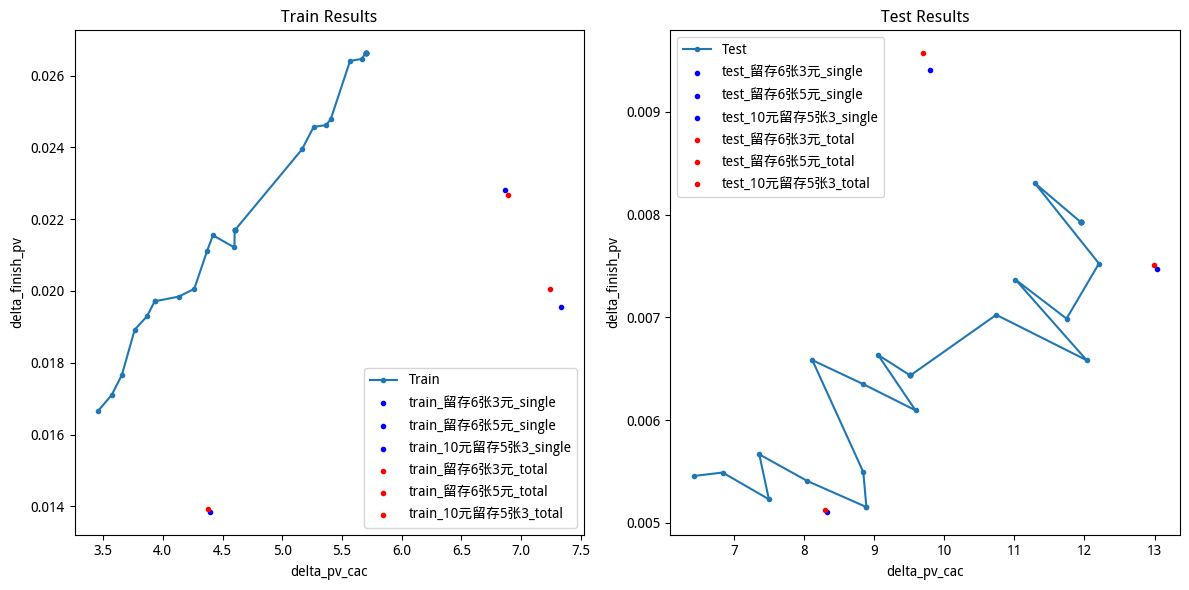

In [199]:
fixed_train_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-12', '2026-08-18')]
fixed_val_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-09-07', '2026-09-13')]

group_name_list = ['DS空白', '留存6张3元','8元留存5张3', '留存6张5元','10元留存5张3']
columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1']

BIN_COUNT_BY_COLUMN = {
    "msg_euen_uplift_cost_26_v3_final_cost_3": 5,
    "msg_euen_uplift_cost_26_v3_final_cost_4": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_1": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1": 3,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1": 3
}

all_columns = ['fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v3_final_cost_3_per','msg_euen_uplift_cost_26_v3_final_cost_4_per', 'msg_euen_uplift_cost_26_v3_final_uplift_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per'] 

stages = [
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
            "msg_euen_uplift_cost_26_v3_final_cost_4_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
        ],
        20000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
        ],
        20000,
    ),
    (
        ["fin_order_wxmini_28d_per"],
        20000,
    ),
]
quantile_thresholds, train_df_single = move_threshold_train_with_nan_list(
    fixed_train_data.copy(),
    group_name_list,
    columns,
    bin_count=BIN_COUNT_BY_COLUMN
)

val_df_single = apply_threshold_to_test(
    fixed_val_data.copy(),
    quantile_thresholds,
    columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1'],
)
        

cost_list = np.arange(3.5, 6.5, 0.1)
use_train_all = train_df_single.copy()
combined_val_data = val_df_single.copy()
group_name_list = ['DS空白', '留存6张3元', '留存6张5元', '10元留存5张3']
discount_para = {'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

train_df_package, val_df_package, bucket_mapping_package, reverse_mapping_package, processed_data_new_fea_dev00, next_processed_data_package, discount_res_list_new_fea_dev00, train_list_package, test_list_new_fea_dev00, tongbu_list_package, tongbu_all_list_package = main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name='DS空白', cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag=True)

train_df_bucket_num: [26 18 11  6  1  5  8 22 15  2 20 23 19 10 25  9  7 16 24 12 27 17 21 14
  0  4 28  3 13]
{'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

验证集 bucket_num 统计:
  总数据量: 807865
  未知组合数量 (bucket_num=-1): 32
  未知组合占比: 0.00%
  已知组合数量: 807833


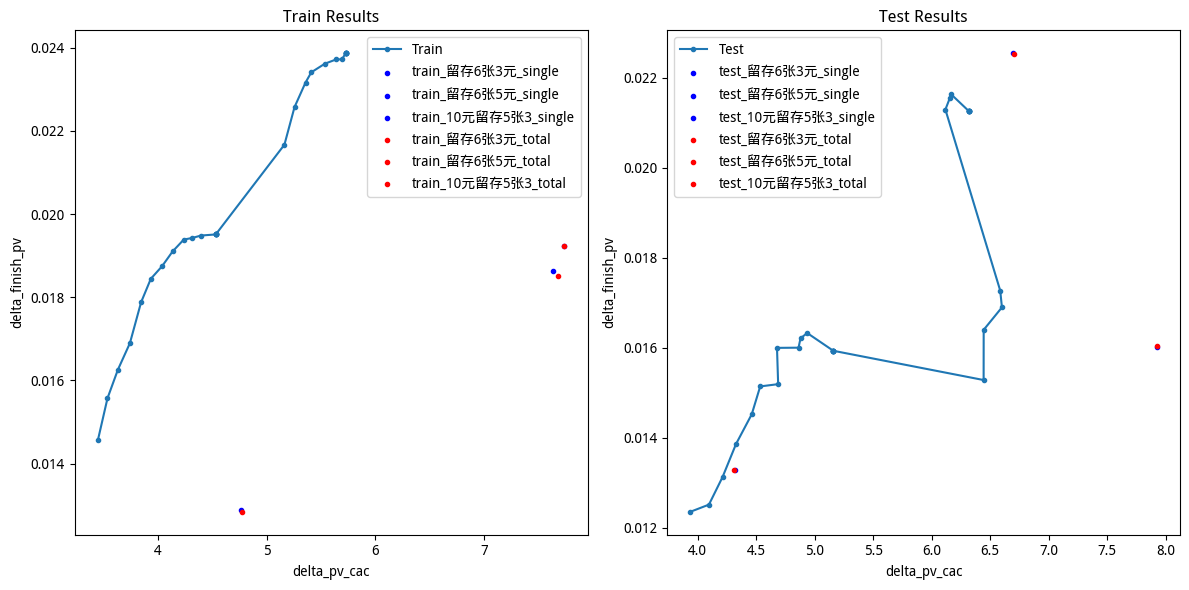

In [170]:
fixed_train_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-11', '2026-08-17')]
fixed_val_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-18', '2026-08-24')]

group_name_list = ['DS空白', '留存6张3元','8元留存5张3', '留存6张5元','10元留存5张3']
columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1']

BIN_COUNT_BY_COLUMN = {
    "msg_euen_uplift_cost_26_v3_final_cost_3": 5,
    "msg_euen_uplift_cost_26_v3_final_cost_4": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_1": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1": 3,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1": 3
}

all_columns = ['fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v3_final_cost_3_per','msg_euen_uplift_cost_26_v3_final_cost_4_per', 'msg_euen_uplift_cost_26_v3_final_uplift_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per'] 

stages = [
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
            "msg_euen_uplift_cost_26_v3_final_cost_4_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
        ],
        20000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
        ],
        20000,
    ),
    (
        ["fin_order_wxmini_28d_per"],
        20000,
    ),
]
quantile_thresholds, train_df_single = move_threshold_train_with_nan_list(
    fixed_train_data.copy(),
    group_name_list,
    columns,
    bin_count=BIN_COUNT_BY_COLUMN
)

val_df_single = apply_threshold_to_test(
    fixed_val_data.copy(),
    quantile_thresholds,
    columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1'],
)
        

cost_list = np.arange(3.5, 6.5, 0.1)
use_train_all = train_df_single.copy()
combined_val_data = val_df_single.copy()
group_name_list = ['DS空白', '留存6张3元', '留存6张5元', '10元留存5张3']
discount_para = {'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

train_df_package, val_df_package, bucket_mapping_package, reverse_mapping_package, processed_data_new_fea_dev00, next_processed_data_package, discount_res_list_new_fea_dev00, train_list_package, test_list_new_fea_dev00, tongbu_list_package, tongbu_all_list_package = main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name='DS空白', cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag=True)

In [171]:
test_list_new_fea_dev00

[[3.5,
  3.9365313342411703,
  0.012350717762343639,
  0.004552047330932884,
  2.7132226148915097],
 [3.6,
  4.095422097266152,
  0.012510075176804355,
  0.004646921824320543,
  2.6921208597335364],
 [3.7,
  4.2122240485526445,
  0.013124826507697328,
  0.00482848138466364,
  2.7182100254926476],
 [3.8000000000000003,
  4.327201370197014,
  0.013858295782712205,
  0.00512741191565105,
  2.7027857349261857],
 [3.9000000000000004,
  4.461607961027039,
  0.014518902416311517,
  0.005356155847402174,
  2.710694541002467],
 [4.0,
  4.533776684317212,
  0.015138066445962474,
  0.005489329991473609,
  2.757725709599518],
 [4.1000000000000005,
  4.6873375906486165,
  0.015188369350998251,
  0.0055666421213319255,
  2.7284616147308824],
 [4.200000000000001,
  4.677414628614458,
  0.015995049584870517,
  0.0055988977197885545,
  2.8568211789863844],
 [4.300000000000001,
  4.861518528045883,
  0.015999162467702444,
  0.005637400930481804,
  2.8380387815232195],
 [4.4,
  4.878511604929509,
  0.016

## 仿真

train_df_bucket_num: [26 18 11  1 10  5  8 22 15  2  6 20 23 25  9  7 19 24 12 16 27 17 21 14
  0  4 28  3 13]
{'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

验证集 bucket_num 统计:
  总数据量: 803803
  未知组合数量 (bucket_num=-1): 26
  未知组合占比: 0.00%
  已知组合数量: 803777


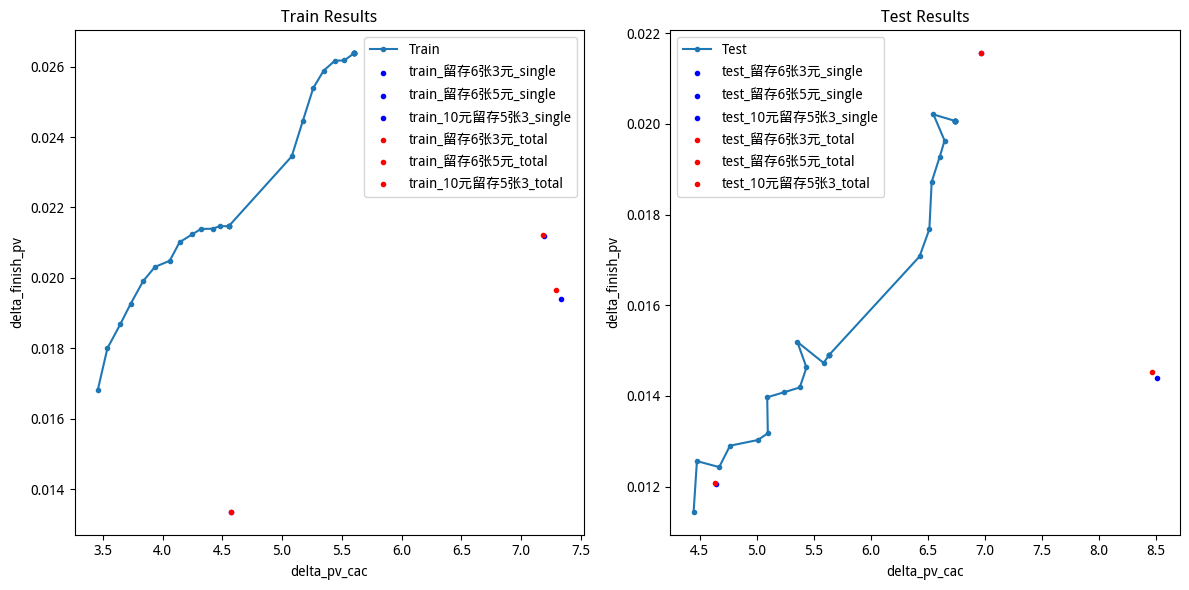

In [128]:
fixed_train_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-12', '2026-08-18')]
fixed_val_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-19', '2026-08-25')]

group_name_list = ['DS空白', '留存6张3元','8元留存5张3', '留存6张5元','10元留存5张3']
columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1']

BIN_COUNT_BY_COLUMN = {
    "msg_euen_uplift_cost_26_v3_final_cost_3": 5,
    "msg_euen_uplift_cost_26_v3_final_cost_4": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_1": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1": 3,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1": 3
}

all_columns = ['fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v3_final_cost_3_per','msg_euen_uplift_cost_26_v3_final_cost_4_per', 'msg_euen_uplift_cost_26_v3_final_uplift_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per'] 

stages = [
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
            "msg_euen_uplift_cost_26_v3_final_cost_4_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
        ],
        20000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
        ],
        20000,
    ),
    (
        ["fin_order_wxmini_28d_per"],
        20000,
    ),
]
quantile_thresholds, train_df_single = move_threshold_train_with_nan_list(
    fixed_train_data.copy(),
    group_name_list,
    columns,
    bin_count=BIN_COUNT_BY_COLUMN
)

val_df_single = apply_threshold_to_test(
    fixed_val_data.copy(),
    quantile_thresholds,
    columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1'],
)
        

cost_list = np.arange(3.5, 6.5, 0.1)
use_train_all = train_df_single.copy()
combined_val_data = val_df_single.copy()
group_name_list = ['DS空白', '留存6张3元', '留存6张5元', '10元留存5张3']
discount_para = {'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

train_df_package, val_df_package, bucket_mapping_package, reverse_mapping_package, processed_data_new_fea_dev01, next_processed_data_package, discount_res_list_new_fea_dev01, train_list_package, test_list_new_fea_dev01, tongbu_list_package, tongbu_all_list_package = main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name='DS空白', cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag=True)

In [129]:
test_list_new_fea_dev01

[[3.5,
  4.445596560657188,
  0.011445466046894883,
  0.004466680351196231,
  2.5624099212359464],
 [3.6,
  4.474701652404715,
  0.012563303582677484,
  0.004805488834271808,
  2.6143653675935017],
 [3.7,
  4.66998175688513,
  0.012430818048814676,
  0.004848012878717672,
  2.5641058222812934],
 [3.8000000000000003,
  4.7652641624059004,
  0.012902904899388477,
  0.004993608000447976,
  2.583884217229498],
 [3.9000000000000004,
  5.009459270803518,
  0.0130281848149509,
  0.005088983343924664,
  2.560076135934739],
 [4.0,
  5.096935372187842,
  0.013176321275477295,
  0.0050892806043735025,
  2.5890341483930257],
 [4.1000000000000005,
  5.091470066390388,
  0.013970097298102791,
  0.005128203433367185,
  2.7241698734502053],
 [4.200000000000001,
  5.2425031603325385,
  0.01408328388234678,
  0.005167070687470843,
  2.7255837464147814],
 [4.300000000000001,
  5.377257104392742,
  0.014186632457048279,
  0.005265724789044379,
  2.6941462050132823],
 [4.4,
  5.436265388967822,
  0.0146274

train_df_bucket_num: [26 18 11  1 10  5  8 22 15  2  6 20 23 25  9  7 19 24 12 16 27 17 21 14
  0  4 28  3 13]
{'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

验证集 bucket_num 统计:
  总数据量: 703042
  未知组合数量 (bucket_num=-1): 28
  未知组合占比: 0.00%
  已知组合数量: 703014


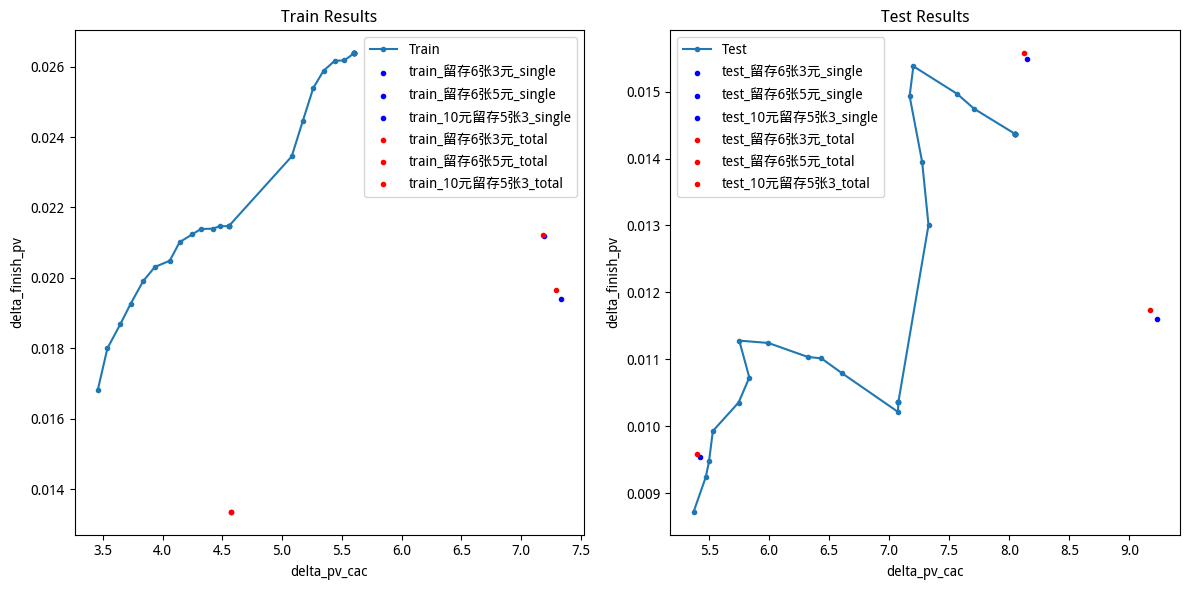

In [140]:
fixed_train_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-12', '2026-08-18')]
fixed_val_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-09-01', '2026-09-07')]

group_name_list = ['DS空白', '留存6张3元','8元留存5张3', '留存6张5元','10元留存5张3']
columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1']

BIN_COUNT_BY_COLUMN = {
    "msg_euen_uplift_cost_26_v3_final_cost_3": 5,
    "msg_euen_uplift_cost_26_v3_final_cost_4": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_1": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1": 3,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1": 3
}

all_columns = ['fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v3_final_cost_3_per','msg_euen_uplift_cost_26_v3_final_cost_4_per', 'msg_euen_uplift_cost_26_v3_final_uplift_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per'] 

stages = [
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
            "msg_euen_uplift_cost_26_v3_final_cost_4_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
        ],
        20000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
        ],
        20000,
    ),
    (
        ["fin_order_wxmini_28d_per"],
        20000,
    ),
]

quantile_thresholds, train_df_single = move_threshold_train_with_nan_list(
    fixed_train_data.copy(),
    group_name_list,
    columns,
    bin_count=BIN_COUNT_BY_COLUMN
)

val_df_single = apply_threshold_to_test(
    fixed_val_data.copy(),
    quantile_thresholds,
    columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1'],
)
        

cost_list = np.arange(3.5, 6.5, 0.1)
use_train_all = train_df_single.copy()
combined_val_data = val_df_single.copy()
group_name_list = ['DS空白', '留存6张3元', '留存6张5元', '10元留存5张3']
discount_para = {'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

train_df_package, val_df_package, bucket_mapping_package, reverse_mapping_package, processed_data_new_fea_dev03, next_processed_data_package, discount_res_list_new_fea_dev03, train_list_package, test_list_new_fea_dev03, tongbu_list_package, tongbu_all_list_package = main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name='DS空白', cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag=True)

In [141]:
test_list_new_fea_dev03

[[3.5,
  5.370648082093778,
  0.008720483038316656,
  0.003576202932054104,
  2.438475445605592],
 [3.6,
  5.471522488449241,
  0.00923715288592817,
  0.00372191448550407,
  2.4818283498733194],
 [3.7,
  5.49911139256871,
  0.00947444753063598,
  0.003823073658814232,
  2.4782278282272445],
 [3.8000000000000003,
  5.530747108126043,
  0.00992749516739488,
  0.004105268796156811,
  2.4182326810582064],
 [3.9000000000000004,
  5.745386607611806,
  0.010353542677611629,
  0.004212056391553594,
  2.458073139375226],
 [4.0,
  5.834576490183777,
  0.010727417374618013,
  0.004246548294586306,
  2.52614985876737],
 [4.1000000000000005,
  5.750802688172069,
  0.011278851480693514,
  0.004354049580520804,
  2.5904278929557822],
 [4.200000000000001,
  5.992910696703186,
  0.011243772770017958,
  0.004353583400167078,
  2.582647841221201],
 [4.300000000000001,
  6.320910190276371,
  0.011035471220760913,
  0.004402605970066818,
  2.506577080890441],
 [4.4,
  6.434817098549596,
  0.011013687642894

train_df_bucket_num: [ 7 13 14 20 10  5  8  2  6  1 27  0 23 18 26 11 24 19 25  3  9 12 15 17
 22  4 28 16 21]
{'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

验证集 bucket_num 统计:
  总数据量: 703042
  未知组合数量 (bucket_num=-1): 28
  未知组合占比: 0.00%
  已知组合数量: 703014


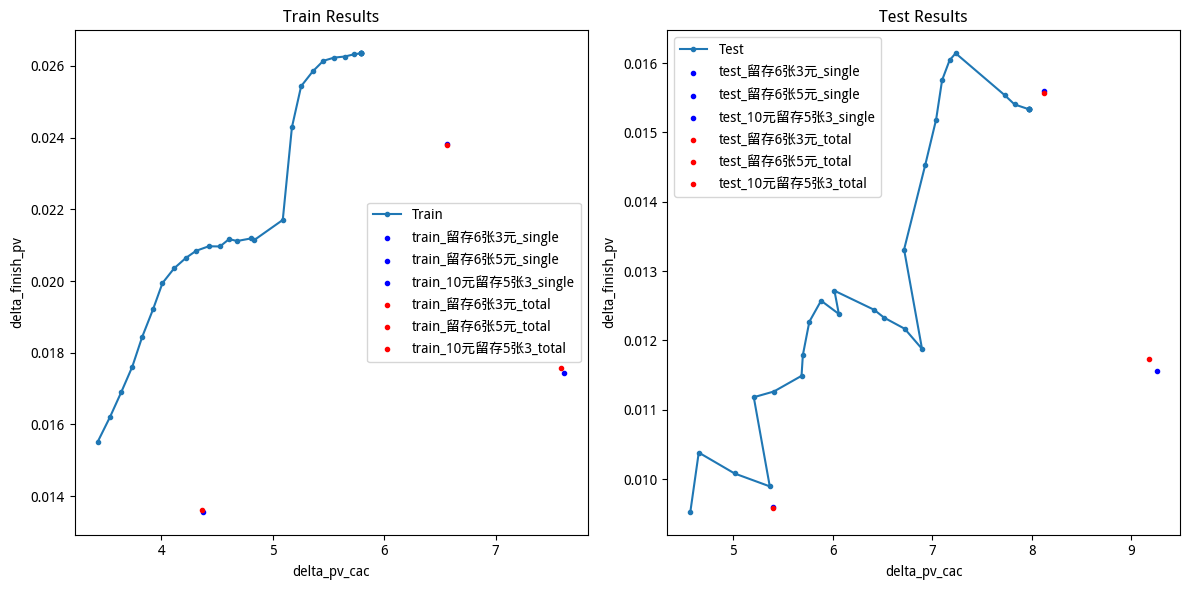

In [130]:
fixed_train_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-16', '2026-08-22')]
fixed_val_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-09-01', '2026-09-07')]

group_name_list = ['DS空白', '留存6张3元','8元留存5张3', '留存6张5元','10元留存5张3']
columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1']

BIN_COUNT_BY_COLUMN = {
    "msg_euen_uplift_cost_26_v3_final_cost_3": 5,
    "msg_euen_uplift_cost_26_v3_final_cost_4": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_1": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1": 3,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1": 3
}

all_columns = ['fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v3_final_cost_3_per','msg_euen_uplift_cost_26_v3_final_cost_4_per', 'msg_euen_uplift_cost_26_v3_final_uplift_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per'] 

stages = [
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
            "msg_euen_uplift_cost_26_v3_final_cost_4_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
        ],
        20000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
        ],
        20000,
    ),
    (
        ["fin_order_wxmini_28d_per"],
        20000,
    ),
]
quantile_thresholds, train_df_single = move_threshold_train_with_nan_list(
    fixed_train_data.copy(),
    group_name_list,
    columns,
    bin_count=BIN_COUNT_BY_COLUMN
)

val_df_single = apply_threshold_to_test(
    fixed_val_data.copy(),
    quantile_thresholds,
    columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1'],
)
        

cost_list = np.arange(3.5, 6.5, 0.1)
use_train_all = train_df_single.copy()
combined_val_data = val_df_single.copy()
group_name_list = ['DS空白', '留存6张3元', '留存6张5元', '10元留存5张3']
discount_para = {'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

train_df_package, val_df_package, bucket_mapping_package, reverse_mapping_package, processed_data_new_fea_dev01, next_processed_data_package, discount_res_list_new_fea_dev01, train_list_package, test_list_new_fea_dev02, tongbu_list_package, tongbu_all_list_package = main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name='DS空白', cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag=True)

In [131]:
test_list_new_fea_dev02

[[3.5,
  4.570201865500878,
  0.00952787895258271,
  0.0038664288100422133,
  2.4642582136353073],
 [3.6,
  4.6546369148257885,
  0.010382351154954743,
  0.004070482983503595,
  2.5506435469773963],
 [3.7,
  5.014807651288581,
  0.01008073579725293,
  0.003968138651580434,
  2.5404192449873104],
 [3.8000000000000003,
  5.368268554720777,
  0.009894567869360667,
  0.003983880414757556,
  2.483650822627118],
 [3.9000000000000004,
  5.207432980071177,
  0.011180972166378023,
  0.0043296757955324835,
  2.5824040169277698],
 [4.0,
  5.409388653109744,
  0.011263332395812965,
  0.004327402981800553,
  2.602792585572074],
 [4.1000000000000005,
  5.687313988448506,
  0.011489089212870795,
  0.004381093906583428,
  2.6224247774297305],
 [4.200000000000001,
  5.700596427183674,
  0.01178862238667586,
  0.004453412144129623,
  2.6470988997089187],
 [4.300000000000001,
  5.76568355989025,
  0.012269887340627426,
  0.004670015628440386,
  2.627376076838766],
 [4.4,
  5.883824024829731,
  0.01257355

train_df_bucket_num: [ 7  5 13 24 20 22 26  1 19 16 23  2 10 25 21 17  6 15  3  8  9 11  0 14
 27 12  4 18]
{'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

验证集 bucket_num 统计:
  总数据量: 703042
  未知组合数量 (bucket_num=-1): 29
  未知组合占比: 0.00%
  已知组合数量: 703013


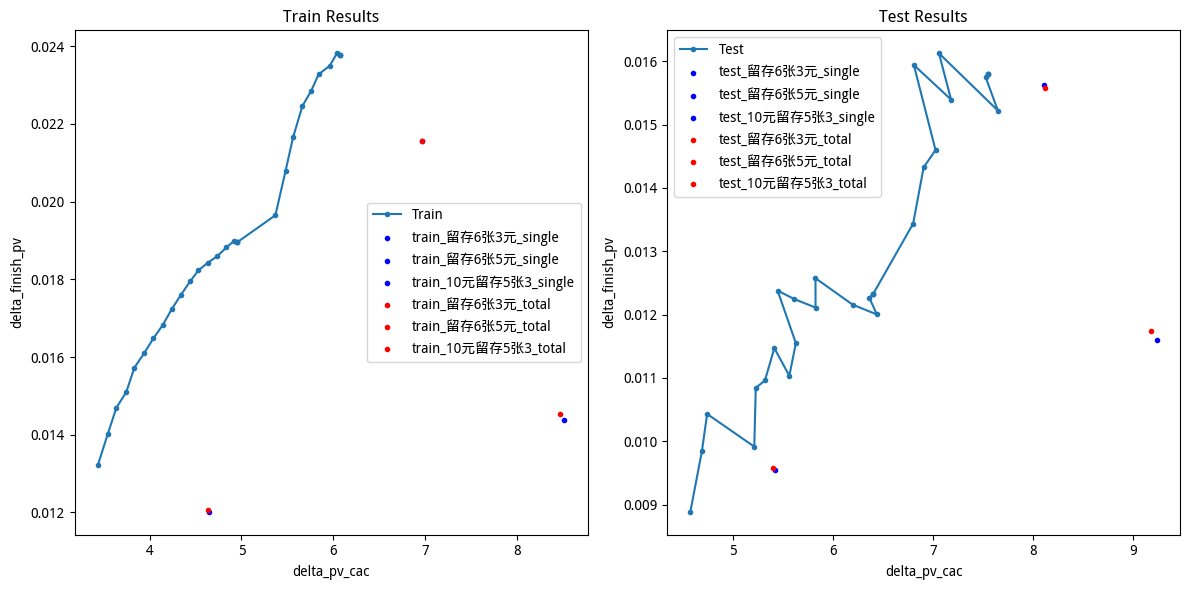

In [160]:
fixed_train_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-08-19', '2026-08-25')]
fixed_val_data = all_rct_data_pdf_v3[all_rct_data_pdf_v3["dt"].between('2026-09-01', '2026-09-07')]

group_name_list = ['DS空白', '留存6张3元','8元留存5张3', '留存6张5元','10元留存5张3']
columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1']

BIN_COUNT_BY_COLUMN = {
    "msg_euen_uplift_cost_26_v3_final_cost_3": 5,
    "msg_euen_uplift_cost_26_v3_final_cost_4": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_1": 5,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1": 3,
    "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1": 3
}

all_columns = ['fin_order_wxmini_28d_per', 'msg_euen_uplift_cost_26_v3_final_cost_3_per','msg_euen_uplift_cost_26_v3_final_cost_4_per', 'msg_euen_uplift_cost_26_v3_final_uplift_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per'] 

stages = [
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
            "msg_euen_uplift_cost_26_v3_final_cost_4_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1_per",
        ],
        15000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
            "msg_euen_uplift_cost_26_v3_final_cost_3_per",
        ],
        20000,
    ),
    (
        [
            "fin_order_wxmini_28d_per",
            "msg_euen_uplift_cost_26_v3_final_uplift_1_per",
        ],
        20000,
    ),
    (
        ["fin_order_wxmini_28d_per"],
        20000,
    ),
]
quantile_thresholds, train_df_single = move_threshold_train_with_nan_list(
    fixed_train_data.copy(),
    group_name_list,
    columns,
    bin_count=BIN_COUNT_BY_COLUMN
)

val_df_single = apply_threshold_to_test(
    fixed_val_data.copy(),
    quantile_thresholds,
    columns = ['msg_euen_uplift_cost_26_v3_final_cost_3', 'msg_euen_uplift_cost_26_v3_final_cost_4',  'msg_euen_uplift_cost_26_v3_final_uplift_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_3_1', 'msg_euen_uplift_cost_26_v3_final_uplift_diff_4_1'],
)
        

cost_list = np.arange(3.5, 6.5, 0.1)
use_train_all = train_df_single.copy()
combined_val_data = val_df_single.copy()
group_name_list = ['DS空白', '留存6张3元', '留存6张5元', '10元留存5张3']
discount_para = {'DS空白': 0, '留存6张5元': 1, '留存6张3元': 2, '10元留存5张3': 3}

train_df_package, val_df_package, bucket_mapping_package, reverse_mapping_package, processed_data_new_fea_dev04, next_processed_data_package, discount_res_list_new_fea_dev04, train_list_package, test_list_new_fea_dev04, tongbu_list_package, tongbu_all_list_package = main_no_cartesian(use_train_all, combined_val_data, group_name_list, control_name='DS空白', cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag=True)

In [161]:
test_list_new_fea_dev04

[[3.5,
  4.575115735060094,
  0.008887768224796073,
  0.003468638835586295,
  2.562321603971143],
 [3.6,
  4.6908638203038,
  0.009846412587088972,
  0.003845638220019491,
  2.560410528434749],
 [3.7,
  4.742951748730387,
  0.010431838377255233,
  0.004000900107513942,
  2.6073728653368735],
 [3.8000000000000003,
  5.213893673993403,
  0.00991631907486958,
  0.004023074410208322,
  2.4648609654615106],
 [3.9000000000000004,
  5.228992654402281,
  0.010841809990962584,
  0.004205184070547031,
  2.5782010511497604],
 [4.0,
  5.320463080951031,
  0.010961124462271318,
  0.004271150431459917,
  2.566316648913887],
 [4.1000000000000005,
  5.414741948041416,
  0.01147093061734676,
  0.0045096135459917145,
  2.5436615577719475],
 [4.200000000000001,
  5.564090838658478,
  0.011034446006207019,
  0.004454864032218102,
  2.4769433873637006],
 [4.300000000000001,
  5.629634951676974,
  0.011548921791848056,
  0.004666913055542024,
  2.4746383003929227],
 [4.4,
  5.447439078980507,
  0.0123786146

# 离线分桶运筹滑动仿真

## 分日计算汇总

In [157]:
import importlib
import pandas as pd
from IPython.display import display
import bucket_opt_backtest as bucket_bt

importlib.reload(bucket_bt.legacy)
importlib.reload(bucket_bt)

bucket_result = bucket_bt.run_bucket_backtest(
    raw=all_rct_data_pdf_v3,
    target_cac=5.5,  # 使用你现有分桶策略的固定值
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    train_window_size=7,
    train_gap_days=6,
    default_coupon="留存6张3元",  # 未知分桶组合的兜底动作
)

with pd.option_context(
    "display.precision", 12,
    "display.max_columns", None,
):
    display(bucket_result["trajectory"])  # 每天训练日期、样本量、桶数
    display(bucket_result["daily"])       # 每天应用期后验效果
    display(bucket_result["summary"])     # 整周效果

,effective_dt,train_start,train_end,target_cac,train_n,bucket_count,status,train_objective
0,2026-09-01,2026-08-19,2026-08-25,5.5,910097,32,SOLVED,20315.419402736850
1,2026-09-02,2026-08-20,2026-08-26,5.5,897284,32,SOLVED,21019.447668504516
2,2026-09-03,2026-08-21,2026-08-27,5.5,887677,30,SOLVED,19291.061204603226
3,2026-09-04,2026-08-22,2026-08-28,5.5,887675,31,SOLVED,15853.023426573171
4,2026-09-05,2026-08-23,2026-08-29,5.5,887801,31,SOLVED,14512.090760917423
5,2026-09-06,2026-08-24,2026-08-30,5.5,889902,31,SOLVED,15173.719000150244
6,2026-09-07,2026-08-25,2026-08-31,5.5,886189,31,SOLVED,15880.080351979570


,effective_dt,strategy,target_cac,n,evaluated_n,status,unsupported_actions,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share,action_share
0,2026-09-01,bucket_rolling,5.5,94304,94304.0,historical_rct_replay,[],1241.056320945347,9162.137342870468,0.013160166281,0.013160166281,7.382531467945,0.189451136749,0.000042416016,"{'DS空白': 0.1894511367492365, '留存6张3元': 0.31201..."
1,2026-09-02,bucket_rolling,5.5,94529,94529.0,historical_rct_replay,[],1340.077895341014,10954.010255473531,0.014176368049,0.014176368049,8.174159348167,0.206169535275,0.000031736293,"{'DS空白': 0.20616953527488918, '留存6张3元': 0.1822..."
2,2026-09-03,bucket_rolling,5.5,93632,93632.0,historical_rct_replay,[],1029.492581073198,9304.264108130566,0.010995093356,0.010995093356,9.037718463625,0.249391233766,0.000064080656,"{'DS空白': 0.24939123376623376, '留存6张3元': 0.2033..."
3,2026-09-04,bucket_rolling,5.5,106933,106933.0,historical_rct_replay,[],940.016698549994,7023.077879369355,0.008790707252,0.008790707252,7.471226724166,0.144679378676,0.000046758250,"{'DS空白': 0.14467937867636743, '留存6张3元': 0.2335..."
4,2026-09-05,bucket_rolling,5.5,112133,112133.0,historical_rct_replay,[],1276.163226018843,8705.584308360079,0.011380799818,0.011380799818,6.821685604841,0.347052161273,0.000026753944,"{'DS空白': 0.3470521612727743, '留存6张3元': 0.25577..."
5,2026-09-06,bucket_rolling,5.5,111105,111105.0,historical_rct_replay,[],671.829816983712,8804.359535560045,0.006046800927,0.006046800927,13.105044332639,0.187903334683,0.000018000990,"{'DS空白': 0.18790333468340759, '留存6张3元': 0.1894..."
6,2026-09-07,bucket_rolling,5.5,90406,90406.0,historical_rct_replay,[],1010.429915028581,9497.355046387604,0.011176580260,0.011176580260,9.399320927784,0.068701192399,0.000044244851,"{'DS空白': 0.0687011923987346, '留存6张3元': 0.25087..."


,strategy,n,days,target_cac,status,unsupported_dates,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share
0,bucket_rolling,703042,7,5.5,historical_rct_replay,[],7509.066453940687,63450.788476151647,0.010680821991,0.010680821991,8.449890391215,0.202236850714,0.000038404533


In [158]:
import importlib
import pandas as pd
from IPython.display import display
import bucket_opt_backtest as bucket_bt

importlib.reload(bucket_bt.legacy)
importlib.reload(bucket_bt)

bucket_result1 = bucket_bt.run_bucket_backtest(
    raw=all_rct_data_pdf_v3,
    target_cac=6.0,  # 使用你现有分桶策略的固定值
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    train_window_size=7,
    train_gap_days=6,
    default_coupon="留存6张3元",  # 未知分桶组合的兜底动作
)

with pd.option_context(
    "display.precision", 12,
    "display.max_columns", None,
):
    display(bucket_result1["trajectory"])  # 每天训练日期、样本量、桶数
    display(bucket_result1["daily"])       # 每天应用期后验效果
    display(bucket_result1["summary"])     # 整周效果

,effective_dt,train_start,train_end,target_cac,train_n,bucket_count,status,train_objective
0,2026-09-01,2026-08-19,2026-08-25,6.0,910097,32,SOLVED,21797.969075672001
1,2026-09-02,2026-08-20,2026-08-26,6.0,897284,32,SOLVED,21433.314126839174
2,2026-09-03,2026-08-21,2026-08-27,6.0,887677,30,SOLVED,20058.681573656642
3,2026-09-04,2026-08-22,2026-08-28,6.0,887675,31,SOLVED,18694.722640895518
4,2026-09-05,2026-08-23,2026-08-29,6.0,887801,31,SOLVED,16922.652684736844
5,2026-09-06,2026-08-24,2026-08-30,6.0,889902,31,SOLVED,16298.566607083239
6,2026-09-07,2026-08-25,2026-08-31,6.0,886189,31,SOLVED,15992.862034027205


,effective_dt,strategy,target_cac,n,evaluated_n,status,unsupported_actions,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share,action_share
0,2026-09-01,bucket_rolling,6.0,94304,94304.0,historical_rct_replay,[],1666.129404941662,10910.617604952869,0.017667642994,0.017667642994,6.548481512056,0.074768832711,0.000042416016,"{'DS空白': 0.07476883271123176, '留存6张3元': 0.2334..."
1,2026-09-02,bucket_rolling,6.0,94529,94529.0,historical_rct_replay,[],1425.966721651146,11380.897171418856,0.015084965689,0.015084965689,7.981180064455,0.072803055147,0.000031736293,"{'DS空白': 0.07280305514709771, '留存6张3元': 0.1270..."
2,2026-09-03,bucket_rolling,6.0,93632,93632.0,historical_rct_replay,[],1057.257814276009,10138.759350071901,0.011291629083,0.011291629083,9.589675491795,0.074098598770,0.000064080656,"{'DS空白': 0.0740985987696514, '留存6张3元': 0.13367..."
3,2026-09-04,bucket_rolling,6.0,106933,106933.0,historical_rct_replay,[],1633.432362726249,11532.899522649177,0.015275287916,0.015275287916,7.060530809736,0.144679378676,0.000046758250,"{'DS空白': 0.14467937867636743, '留存6张3元': 0.1096..."
4,2026-09-05,bucket_rolling,6.0,112133,112133.0,historical_rct_replay,[],1718.882440266829,12090.025964291875,0.015328961503,0.015328961503,7.033654938272,0.297066875942,0.000026753944,"{'DS空白': 0.2970668759419618, '留存6张3元': 0.23182..."
5,2026-09-06,bucket_rolling,6.0,111105,111105.0,historical_rct_replay,[],1438.719616567999,11524.044799868871,0.012949188754,0.012949188754,8.009930960251,0.143422888259,0.000018000990,"{'DS空白': 0.14342288825885424, '留存6张3元': 0.2352..."
6,2026-09-07,bucket_rolling,6.0,90406,90406.0,historical_rct_replay,[],967.952254786902,9535.116532475862,0.010706725823,0.010706725823,9.850812873591,0.068701192399,0.000044244851,"{'DS空白': 0.0687011923987346, '留存6张3元': 0.15647..."


,strategy,n,days,target_cac,status,unsupported_dates,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share
0,bucket_rolling,703042,7,6.0,historical_rct_replay,[],9908.340615216795,77112.360945729408,0.014093525871,0.014093525871,7.782570658431,0.130573991312,0.000038404533


In [159]:
import pandas as pd
from IPython.display import display

# 按需修改
target_cac_list = [5.6, 5.7, 5.8, 5.9]

bucket_results_by_cac = {}
summary_parts = []
daily_parts = []

for cac in target_cac_list:
    print(f"开始仿真 target_cac={cac}")

    result = bucket_bt.run_bucket_backtest(
        raw=all_rct_data_pdf_v3,
        target_cac=cac,
        model_version="v3",
        start_dt="2026-09-01",
        end_dt="2026-09-07",
        train_window_size=7,
        train_gap_days=6,
        default_coupon="留存6张3元",
    )

    bucket_results_by_cac[cac] = result
    summary_parts.append(result["summary"])
    daily_parts.append(result["daily"])

bucket_summary_all = pd.concat(
    summary_parts, ignore_index=True
).sort_values("target_cac")

bucket_daily_all = pd.concat(
    daily_parts, ignore_index=True
).sort_values(["target_cac", "effective_dt"])

with pd.option_context("display.precision", 12):
    display(bucket_summary_all[
        [
            "target_cac", "n", "days", "status",
            "delta_cvr_pv_ratio", "delta_cac",
            "no_send_share", "unknown_bucket_share",
        ]
    ])

开始仿真 target_cac=5.6
开始仿真 target_cac=5.7
开始仿真 target_cac=5.8
开始仿真 target_cac=5.9


,target_cac,n,days,status,delta_cvr_pv_ratio,delta_cac,no_send_share,unknown_bucket_share
0,5.6,703042,7,historical_rct_replay,0.010773544317,8.736085252221,0.155014920872,0.000038404533
1,5.7,703042,7,historical_rct_replay,0.012264917135,8.202032960666,0.137144011311,0.000038404533
2,5.8,703042,7,historical_rct_replay,0.012761225461,8.092215910265,0.158354692892,0.000038404533
3,5.9,703042,7,historical_rct_replay,0.014322110802,7.609824013269,0.130986484449,0.000038404533


## 合并应用周期计算汇总

In [180]:
importlib.reload(bucket_bt)

bucket_result1 = bucket_bt.run_bucket_backtest(
    raw=all_rct_data_pdf_v3,
    target_cac=6.0,
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    train_window_size=7,
    train_gap_days=6,
    default_coupon="留存6张3元",
    evaluation_mode="pooled",
)

with pd.option_context("display.precision", 12, "display.max_columns", None):
    display(bucket_result1["summary"])        # 合并后统一放缩
    display(bucket_result1["summary_daily"])  # 同批决策的逐日放缩汇总

,strategy,days,target_cac,evaluation_mode,daily_unsupported_dates,n,evaluated_n,status,unsupported_actions,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share,action_share
0,bucket_rolling,7,6.0,pooled,[],703042,703042.0,historical_rct_replay,[],9952.227509903572,77221.785830181849,0.014155950156,0.014155950156,7.759246435367,0.130573991312,0.000038404533,"{'DS空白': 0.1305739913120411, '留存6张3元': 0.17715..."


,strategy,n,days,target_cac,evaluation_mode,status,unsupported_dates,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share
0,bucket_rolling,703042,7,6.0,daily,historical_rct_replay,[],9908.340615216795,77112.360945729408,0.014093525871,0.014093525871,7.782570658431,0.130573991312,0.000038404533


In [181]:
importlib.reload(bucket_bt)

bucket_result2 = bucket_bt.run_bucket_backtest(
    raw=all_rct_data_pdf_v3,
    target_cac=6.0,
    model_version="v3",
    start_dt="2026-09-01",
    end_dt="2026-09-07",
    train_window_size=7,
    train_gap_days=6,
    default_coupon="留存6张3元",
    evaluation_mode="daily",
)

with pd.option_context("display.precision", 12, "display.max_columns", None):
    display(bucket_result2["summary"])        # 合并后统一放缩
    display(bucket_result2["summary_daily"])  # 同批决策的逐日放缩汇总

,strategy,n,days,target_cac,evaluation_mode,status,unsupported_dates,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share
0,bucket_rolling,703042,7,6.0,daily,historical_rct_replay,[],9908.340615216795,77112.360945729408,0.014093525871,0.014093525871,7.782570658431,0.130573991312,0.000038404533


,strategy,n,days,target_cac,evaluation_mode,status,unsupported_dates,delta_finish_pv_total,delta_cost,delta_cvr_pv_ratio,delta_pv_per_user,delta_cac,no_send_share,unknown_bucket_share
0,bucket_rolling,703042,7,6.0,daily,historical_rct_replay,[],9908.340615216795,77112.360945729408,0.014093525871,0.014093525871,7.782570658431,0.130573991312,0.000038404533
